In [1]:
# ==========================================
# REAL ESTATE INVESTMENT ADVISOR
# PHASE 1: DATASET LOADING AND INSPECTION
# STEP 1: IMPORT REQUIRED LIBRARIES
# ==========================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.2f}".format)

print("Libraries imported successfully.")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Libraries imported successfully.
Pandas version: 3.1.0
NumPy version: 2.5.4


In [3]:
# ==========================================
# FIND THE DATASET LOCATION
# ==========================================

import os
from pathlib import Path

# Current notebook working directory
current_dir = Path.cwd()

print("Current Working Directory:")
print(current_dir)

print("\nFiles in Current Directory:")

for file in current_dir.iterdir():
    print(file.name)

print("\nSearching for CSV files:")

for file in current_dir.rglob("*.csv"):
    print(file)

Current Working Directory:
C:\Users\rahul\Real-Estate-Investment-Advisor\notebooks

Files in Current Directory:
.ipynb_checkpoints
01_Real_Estate_Investment_Advisor.ipynb

Searching for CSV files:


In [4]:
from pathlib import Path

# Project root (one level above notebooks)
project_dir = Path.cwd().parent

print("Project Directory:", project_dir)

print("\nProject Folders and Files:")

for item in project_dir.iterdir():
    print(item.name)

Project Directory: C:\Users\rahul\Real-Estate-Investment-Advisor

Project Folders and Files:
.venv
data
models
notebooks
reports
requirements.txt
src
tests


In [5]:
file_path = project_dir / "data" / "india_housing_prices.csv"

In [6]:
# ==========================================
# STEP 2B: VERIFY AND LOAD DATASET
# ==========================================

# Verify that the file exists
if file_path.exists():

    print("Dataset file found:", file_path)

    # Load the original CSV
    df = pd.read_csv(file_path)

    print("\nDataset loaded successfully!")

    print("\nDataset Shape:", df.shape)

    print("\nFirst 5 Records:")
    display(df.head())

else:
    print("ERROR: Dataset file not found!")
    print("Expected location:", file_path)

ERROR: Dataset file not found!
Expected location: C:\Users\rahul\Real-Estate-Investment-Advisor\data\india_housing_prices.csv


In [7]:
# ==========================================
# STEP 2C: INSPECT DATA FOLDER
# ==========================================

data_dir = project_dir / "data"

print("Data folder:", data_dir)
print("\nFiles inside data folder:")

if data_dir.exists():
    files = list(data_dir.iterdir())

    if files:
        for file in files:
            print(file.name)
    else:
        print("The data folder is empty.")
else:
    print("Data folder does not exist.")

Data folder: C:\Users\rahul\Real-Estate-Investment-Advisor\data

Files inside data folder:
processed
raw


In [8]:
# ==========================================
# STEP 2D: FIND ORIGINAL DATASET
# ==========================================

raw_dir = data_dir / "raw"

print("Raw folder:", raw_dir)
print("\nFiles inside raw folder:")

if raw_dir.exists():

    raw_files = list(raw_dir.rglob("*"))

    if raw_files:
        for file in raw_files:
            if file.is_file():
                print(file.name, " | ", file)
    else:
        print("Raw folder is empty.")

else:
    print("Raw folder does not exist.")

Raw folder: C:\Users\rahul\Real-Estate-Investment-Advisor\data\raw

Files inside raw folder:
india_housing_prices.csv  |  C:\Users\rahul\Real-Estate-Investment-Advisor\data\raw\india_housing_prices.csv


In [9]:
# ==========================================
# STEP 2E: LOAD ORIGINAL DATASET
# ==========================================

# Exact original dataset location
file_path = raw_dir / "india_housing_prices.csv"

# Verify and load
if file_path.exists():

    df = pd.read_csv(file_path)

    print("Dataset loaded successfully!")
    print("Dataset Shape:", df.shape)

    print("\nFirst 5 Records:")
    display(df.head())

else:
    print("Dataset not found:", file_path)

Dataset loaded successfully!
Dataset Shape: (250000, 23)

First 5 Records:


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Furnished_Status,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,Furnished,22,1,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,Unfurnished,21,20,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,Semi-furnished,19,27,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,Furnished,21,26,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,Semi-furnished,3,2,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move


In [10]:
# ==========================================
# STEP 3: DATASET STRUCTURE AND INFORMATION
# ==========================================

print("=" * 60)
print("DATASET INFORMATION")
print("=" * 60)

# Dataset dimensions
print("\n1. Dataset Shape:")
print(df.shape)

# Column names
print("\n2. Column Names:")
print(df.columns.tolist())

# Data types and non-null counts
print("\n3. Dataset Information:")
df.info()

# Numerical columns
numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Categorical columns
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("\n4. Numerical Columns:")
print(numerical_columns)
print("Total Numerical Columns:", len(numerical_columns))

print("\n5. Categorical Columns:")
print(categorical_columns)
print("Total Categorical Columns:", len(categorical_columns))

DATASET INFORMATION

1. Dataset Shape:
(250000, 23)

2. Column Names:
['ID', 'State', 'City', 'Locality', 'Property_Type', 'BHK', 'Size_in_SqFt', 'Price_in_Lakhs', 'Price_per_SqFt', 'Year_Built', 'Furnished_Status', 'Floor_No', 'Total_Floors', 'Age_of_Property', 'Nearby_Schools', 'Nearby_Hospitals', 'Public_Transport_Accessibility', 'Parking_Space', 'Security', 'Amenities', 'Facing', 'Owner_Type', 'Availability_Status']

3. Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 23 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   ID                              250000 non-null  int64  
 1   State                           250000 non-null  str    
 2   City                            250000 non-null  str    
 3   Locality                        250000 non-null  str    
 4   Property_Type                   250000 non-null  str    
 5   BHK         

In [11]:
# ==========================================
# STEP 4: MISSING VALUE ANALYSIS
# ==========================================

# Count missing values
missing_count = df.isnull().sum()

# Calculate missing percentage
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

# Create missing value summary
missing_summary = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_percentage
})

# Sort by missing count
missing_summary = missing_summary.sort_values(
    by="Missing_Count",
    ascending=False
)

print("=" * 60)
print("MISSING VALUE ANALYSIS")
print("=" * 60)

display(missing_summary)

# Overall missing value statistics
total_missing = df.isnull().sum().sum()

print("\nTotal Missing Values:", total_missing)

print(
    "Total Missing Percentage:",
    round((total_missing / df.size) * 100, 4),
    "%"
)

if total_missing == 0:
    print("\nNo missing values found.")
else:
    print("\nMissing values detected. Cleaning will be required.")

MISSING VALUE ANALYSIS


,Missing_Count,Missing_Percentage
ID,0,0.00
State,0,0.00
City,0,0.00
Locality,0,0.00
Property_Type,0,0.00
BHK,0,0.00
Size_in_SqFt,0,0.00
Price_in_Lakhs,0,0.00
Price_per_SqFt,0,0.00
Year_Built,0,0.00



Total Missing Values: 0
Total Missing Percentage: 0.0 %

No missing values found.


In [12]:
# ==========================================
# STEP 5: DUPLICATE RECORD ANALYSIS
# ==========================================

print("=" * 60)
print("DUPLICATE RECORD ANALYSIS")
print("=" * 60)

# 1. Complete duplicate rows
total_duplicates = df.duplicated().sum()

print("\n1. Complete Duplicate Rows:", total_duplicates)

# 2. Duplicate IDs
duplicate_ids = df["ID"].duplicated().sum()

print("\n2. Duplicate IDs:", duplicate_ids)

# 3. Duplicate property combinations
property_columns = [
    "State",
    "City",
    "Locality",
    "Property_Type",
    "BHK",
    "Size_in_SqFt",
    "Year_Built"
]

duplicate_properties = df.duplicated(
    subset=property_columns
).sum()

print("\n3. Duplicate Property Combinations:", duplicate_properties)

# 4. Duplicate percentages
print("\n4. Duplicate Percentages:")

print(
    "Complete Duplicate Percentage:",
    round(total_duplicates / len(df) * 100, 4),
    "%"
)

print(
    "Duplicate ID Percentage:",
    round(duplicate_ids / len(df) * 100, 4),
    "%"
)

print(
    "Duplicate Property Combination Percentage:",
    round(duplicate_properties / len(df) * 100, 4),
    "%"
)

DUPLICATE RECORD ANALYSIS

1. Complete Duplicate Rows: 0

2. Duplicate IDs: 0

3. Duplicate Property Combinations: 1

4. Duplicate Percentages:
Complete Duplicate Percentage: 0.0 %
Duplicate ID Percentage: 0.0 %
Duplicate Property Combination Percentage: 0.0004 %


In [13]:
# ==========================================
# STEP 6: CATEGORICAL VALUE ANALYSIS
# ==========================================

print("=" * 65)
print("CATEGORICAL FEATURE ANALYSIS")
print("=" * 65)

for col in categorical_columns:

    print(f"\n{'-' * 60}")
    print(f"Column: {col}")
    print(f"Unique Values: {df[col].nunique()}")

    print("\nValue Counts:")

    display(
        df[col]
        .value_counts(dropna=False)
        .head(20)
    )

CATEGORICAL FEATURE ANALYSIS

------------------------------------------------------------
Column: State
Unique Values: 20

Value Counts:


State
Odisha            12681
Tamil Nadu        12629
West Bengal       12622
Gujarat           12578
Delhi             12552
Telangana         12539
Maharashtra       12533
Punjab            12516
Uttar Pradesh     12508
Uttarakhand       12501
Assam             12496
Kerala            12487
Jharkhand         12480
Andhra Pradesh    12462
Chhattisgarh      12456
Madhya Pradesh    12451
Karnataka         12424
Rajasthan         12402
Bihar             12369
Haryana           12314
Name: count, dtype: int64


------------------------------------------------------------
Column: City
Unique Values: 42

Value Counts:


City
Coimbatore     6461
Ahmedabad      6411
Silchar        6404
Durgapur       6387
Cuttack        6358
Vijayawada     6344
Jamshedpur     6335
Bhubaneswar    6323
New Delhi      6306
Kochi          6305
Ludhiana       6295
Bhopal         6284
Hyderabad      6273
Noida          6271
Haridwar       6267
Warangal       6266
Bilaspur       6263
Dwarka         6246
Lucknow        6237
Kolkata        6235
Name: count, dtype: int64


------------------------------------------------------------
Column: Locality
Unique Values: 500

Value Counts:


Locality
Locality_296    567
Locality_316    562
Locality_297    561
Locality_313    560
Locality_321    558
Locality_405    555
Locality_11     555
Locality_496    551
Locality_224    548
Locality_193    548
Locality_238    546
Locality_396    543
Locality_218    542
Locality_105    542
Locality_80     540
Locality_438    540
Locality_234    538
Locality_447    538
Locality_440    538
Locality_10     538
Name: count, dtype: int64

... (14 outputs left out)


------------------------------------------------------------
Column: Owner_Type
Unique Values: 3

Value Counts:


Owner_Type
Broker     83479
Owner      83268
Builder    83253
Name: count, dtype: int64


------------------------------------------------------------
Column: Availability_Status
Unique Values: 2

Value Counts:


Availability_Status
Under_Construction    125035
Ready_to_Move         124965
Name: count, dtype: int64

In [14]:
# ==========================================
# STEP 7: CATEGORICAL CONSISTENCY CHECK
# ==========================================

print("=" * 65)
print("CATEGORICAL CONSISTENCY VALIDATION")
print("=" * 65)

# 1. Check whitespace and empty strings
consistency_results = []

for col in categorical_columns:

    values = df[col].astype("string")

    leading_trailing_spaces = (
        values.ne(values.str.strip())
    ).sum()

    empty_strings = (
        values.str.strip().eq("")
    ).sum()

    consistency_results.append({
        "Column": col,
        "Whitespace_Records": leading_trailing_spaces,
        "Empty_Strings": empty_strings
    })

consistency_df = pd.DataFrame(consistency_results)

print("\n1. Whitespace and Empty String Analysis:")
display(consistency_df)

# 2. Check capitalization inconsistencies
print("\n2. Potential Capitalization Inconsistencies:")

for col in categorical_columns:

    values = df[col].dropna().astype(str)

    normalized = values.str.strip().str.lower()

    inconsistent = (
        pd.DataFrame({
            "Original": values,
            "Normalized": normalized
        })
        .groupby("Normalized")["Original"]
        .nunique()
    )

    inconsistent = inconsistent[inconsistent > 1]

    if not inconsistent.empty:
        print(f"\n{col}:")
        print(inconsistent)

# 3. Check whether a city appears under multiple states
city_state_mapping = (
    df.groupby("City")["State"]
    .nunique()
    .sort_values(ascending=False)
)

multiple_states = city_state_mapping[
    city_state_mapping > 1
]

print("\n3. Cities Associated With Multiple States:")
display(multiple_states)

print(
    "\nTotal cities associated with multiple states:",
    len(multiple_states)
)

CATEGORICAL CONSISTENCY VALIDATION

1. Whitespace and Empty String Analysis:


,Column,Whitespace_Records,Empty_Strings
0,State,0,0
1,City,0,0
2,Locality,0,0
3,Property_Type,0,0
4,Furnished_Status,0,0
5,Public_Transport_Accessibility,0,0
6,Parking_Space,0,0
7,Security,0,0
8,Amenities,0,0
9,Facing,0,0



2. Potential Capitalization Inconsistencies:

3. Cities Associated With Multiple States:


Series([], Name: State, dtype: int64)


Total cities associated with multiple states: 0


In [15]:
# ==========================================
# STEP 8: NUMERICAL FEATURE VALIDATION
# ==========================================

print("=" * 65)
print("NUMERICAL FEATURE VALIDATION")
print("=" * 65)

# Exclude ID because it is an identifier
numeric_features = [
    col for col in numerical_columns
    if col != "ID"
]

# Statistical summary
numerical_summary = df[numeric_features].describe().T

print("\n1. Numerical Statistical Summary:")
display(numerical_summary.round(2))

# Zero-value counts
print("\n2. Zero Value Counts:")
zero_counts = (df[numeric_features] == 0).sum()
display(zero_counts[zero_counts > 0])

# Negative-value counts
print("\n3. Negative Value Counts:")
negative_counts = (df[numeric_features] < 0).sum()
display(negative_counts[negative_counts > 0])

# Minimum and maximum values
print("\n4. Minimum and Maximum Values:")
display(
    df[numeric_features]
    .agg(["min", "max"])
    .T
)

NUMERICAL FEATURE VALIDATION

1. Numerical Statistical Summary:


,count,mean,std,min,25%,50%,75%,max
BHK,250000.00,3.00,1.42,1.00,2.00,3.00,4.00,5.00
Size_in_SqFt,250000.00,2749.81,1300.61,500.00,1623.00,2747.00,3874.00,5000.00
Price_in_Lakhs,250000.00,254.59,141.35,10.00,132.55,253.87,376.88,500.00
Price_per_SqFt,250000.00,0.13,0.13,0.00,0.05,0.09,0.16,0.99
Year_Built,250000.00,2006.52,9.81,1990.00,1998.00,2007.00,2015.00,2023.00
Floor_No,250000.00,14.97,8.95,0.00,7.00,15.00,23.00,30.00
Total_Floors,250000.00,15.50,8.67,1.00,8.00,15.00,23.00,30.00
Age_of_Property,250000.00,18.48,9.81,2.00,10.00,18.00,27.00,35.00
Nearby_Schools,250000.00,5.50,2.88,1.00,3.00,5.00,8.00,10.00
Nearby_Hospitals,250000.00,5.50,2.87,1.00,3.00,5.00,8.00,10.00



2. Zero Value Counts:


Price_per_SqFt    2534
Floor_No          8203
dtype: int64


3. Negative Value Counts:


Series([], dtype: int64)


4. Minimum and Maximum Values:


,min,max
BHK,1.00,5.00
Size_in_SqFt,500.00,5000.00
Price_in_Lakhs,10.00,500.00
Price_per_SqFt,0.00,0.99
Year_Built,1990.00,2023.00
Floor_No,0.00,30.00
Total_Floors,1.00,30.00
Age_of_Property,2.00,35.00
Nearby_Schools,1.00,10.00
Nearby_Hospitals,1.00,10.00


In [16]:
# ==========================================
# STEP 9: NUMERICAL RELATIONSHIP VALIDATION
# ==========================================

print("=" * 65)
print("NUMERICAL RELATIONSHIP VALIDATION")
print("=" * 65)

# 1. Check Year_Built and Age_of_Property
age_check = (
    df["Year_Built"] + df["Age_of_Property"]
)

age_mismatch = (
    age_check != 2025
).sum()

print("\n1. Year and Age Consistency")
print("Total records:", len(df))
print("Mismatched records:", age_mismatch)

# 2. Check Floor_No against Total_Floors
floor_mismatch = (
    df["Floor_No"] > df["Total_Floors"]
)

print("\n2. Floor Consistency")
print("Invalid floor records:", floor_mismatch.sum())
print(
    "Invalid percentage:",
    round(floor_mismatch.mean() * 100, 2),
    "%"
)

# 3. Check zero Price_per_SqFt
zero_price_sqft = (
    df["Price_per_SqFt"] == 0
)

print("\n3. Zero Price Per Square Foot")
print("Zero records:", zero_price_sqft.sum())

# 4. Verify Price_per_SqFt formula
calculated_price_sqft = (
    df["Price_in_Lakhs"] / df["Size_in_SqFt"]
).round(2)

price_sqft_mismatch = (
    df["Price_per_SqFt"] != calculated_price_sqft
)

print("\n4. Price Per SqFt Formula Validation")
print("Mismatched records:", price_sqft_mismatch.sum())

print(
    "Mismatch percentage:",
    round(price_sqft_mismatch.mean() * 100, 4),
    "%"
)

NUMERICAL RELATIONSHIP VALIDATION

1. Year and Age Consistency
Total records: 250000
Mismatched records: 0

2. Floor Consistency
Invalid floor records: 116304
Invalid percentage: 46.52 %

3. Zero Price Per Square Foot
Zero records: 2534

4. Price Per SqFt Formula Validation
Mismatched records: 21
Mismatch percentage: 0.0084 %


In [17]:
# ==========================================
# STEP 10: INSPECT SUSPICIOUS RECORDS
# ==========================================

print("=" * 65)
print("SUSPICIOUS RECORD INVESTIGATION")
print("=" * 65)

# 1. Inspect invalid floor records
print("\n1. Invalid Floor Records:")

invalid_floor_records = df.loc[
    floor_mismatch,
    ["Property_Type", "Floor_No", "Total_Floors"]
]

display(invalid_floor_records.head(10))

print(
    "\nFloor mismatch distribution by property type:"
)

display(
    df.loc[floor_mismatch]
    .groupby("Property_Type")
    .size()
    .to_frame("Invalid_Records")
)

# 2. Inspect zero price-per-square-foot records
print("\n2. Zero Price Per SqFt Records:")

display(
    df.loc[
        zero_price_sqft,
        [
            "Size_in_SqFt",
            "Price_in_Lakhs",
            "Price_per_SqFt"
        ]
    ].head(10)
)

# 3. Inspect formula mismatches
print("\n3. Price Per SqFt Formula Mismatches:")

display(
    df.loc[
        price_sqft_mismatch,
        [
            "Size_in_SqFt",
            "Price_in_Lakhs",
            "Price_per_SqFt"
        ]
    ].head(10)
)

SUSPICIOUS RECORD INVESTIGATION

1. Invalid Floor Records:


,Property_Type,Floor_No,Total_Floors
0,Apartment,22,1
1,Independent House,21,20
4,Villa,3,2
5,Apartment,27,1
6,Independent House,16,5
7,Independent House,24,4
8,Villa,23,16
12,Independent House,9,1
13,Independent House,13,4
14,Apartment,26,18



Floor mismatch distribution by property type:


,Invalid_Records
Property_Type,
Apartment,38639
Independent House,38655
Villa,39010



2. Zero Price Per SqFt Records:


,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt
190,4467,11.62,0.00
214,3471,17.01,0.00
272,4497,21.01,0.00
356,3498,12.80,0.00
387,4775,18.34,0.00
551,3438,15.67,0.00
596,4453,18.89,0.00
654,4479,14.73,0.00
1023,2888,10.30,0.00
1133,4718,17.80,0.00



3. Price Per SqFt Formula Mismatches:


,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt
3964,2786,69.65,0.03
16607,728,382.20,0.53
26681,558,292.95,0.53
30731,3194,239.55,0.07
52600,2896,448.88,0.15
75443,2562,217.77,0.09
75873,1034,15.51,0.01
85357,1306,385.27,0.29
88087,4694,23.47,0.01
99274,692,231.82,0.33


In [19]:
# ==========================================
# STEP 11: PRICE PER SQFT ROUNDING VALIDATION
# ==========================================

print("=" * 65)
print("PRICE PER SQFT ROUNDING VALIDATION")
print("=" * 65)

# Calculate the unrounded ratio
calculated_ratio = (
    df["Price_in_Lakhs"] / df["Size_in_SqFt"]
)

# Calculate rounded ratio
rounded_ratio = calculated_ratio.round(2)

# Compare using numerical tolerance
matches = np.isclose(
    df["Price_per_SqFt"],
    rounded_ratio,
    atol=1e-10
)

mismatches = ~matches

print("\n1. Formula Comparison")
print("Matching records:", matches.sum())
print("Mismatching records:", mismatches.sum())

print(
    "Matching percentage:",
    round(matches.mean() * 100, 4),
    "%"
)

# Investigate zero values
print("\n2. Zero Price_per_SqFt Investigation")

zero_records = df.loc[
    df["Price_per_SqFt"] == 0,
    ["Price_in_Lakhs", "Size_in_SqFt", "Price_per_SqFt"]
].copy()

zero_records["Unrounded_Calculated_Ratio"] = (
    zero_records["Price_in_Lakhs"] /
    zero_records["Size_in_SqFt"]
)

display(zero_records.head(10))

print(
    "\nZero values with calculated ratio below 0.005:",
    (zero_records["Unrounded_Calculated_Ratio"] < 0.005).sum()
)

# Inspect formula mismatches
print("\n3. Formula Mismatch Investigation")

mismatch_records = df.loc[
    mismatches,
    ["Price_in_Lakhs", "Size_in_SqFt", "Price_per_SqFt"]
].copy()

mismatch_records["Calculated_Ratio"] = (
    mismatch_records["Price_in_Lakhs"] /
    mismatch_records["Size_in_SqFt"]
)

mismatch_records["Rounded_Ratio"] = (
    mismatch_records["Calculated_Ratio"].round(2)
)

display(mismatch_records.head(10))

PRICE PER SQFT ROUNDING VALIDATION

1. Formula Comparison
Matching records: 249979
Mismatching records: 21
Matching percentage: 99.9916 %

2. Zero Price_per_SqFt Investigation


,Price_in_Lakhs,Size_in_SqFt,Price_per_SqFt,Unrounded_Calculated_Ratio
190,11.62,4467,0.00,0.00
214,17.01,3471,0.00,0.00
272,21.01,4497,0.00,0.00
356,12.80,3498,0.00,0.00
387,18.34,4775,0.00,0.00
551,15.67,3438,0.00,0.00
596,18.89,4453,0.00,0.00
654,14.73,4479,0.00,0.00
1023,10.30,2888,0.00,0.00
1133,17.80,4718,0.00,0.00



Zero values with calculated ratio below 0.005: 2534

3. Formula Mismatch Investigation


,Price_in_Lakhs,Size_in_SqFt,Price_per_SqFt,Calculated_Ratio,Rounded_Ratio
3964,69.65,2786,0.03,0.03,0.02
16607,382.20,728,0.53,0.53,0.52
26681,292.95,558,0.53,0.53,0.52
30731,239.55,3194,0.07,0.07,0.08
52600,448.88,2896,0.15,0.15,0.16
75443,217.77,2562,0.09,0.09,0.08
75873,15.51,1034,0.01,0.01,0.02
85357,385.27,1306,0.29,0.29,0.30
88087,23.47,4694,0.01,0.01,0.00
99274,231.82,692,0.33,0.33,0.34


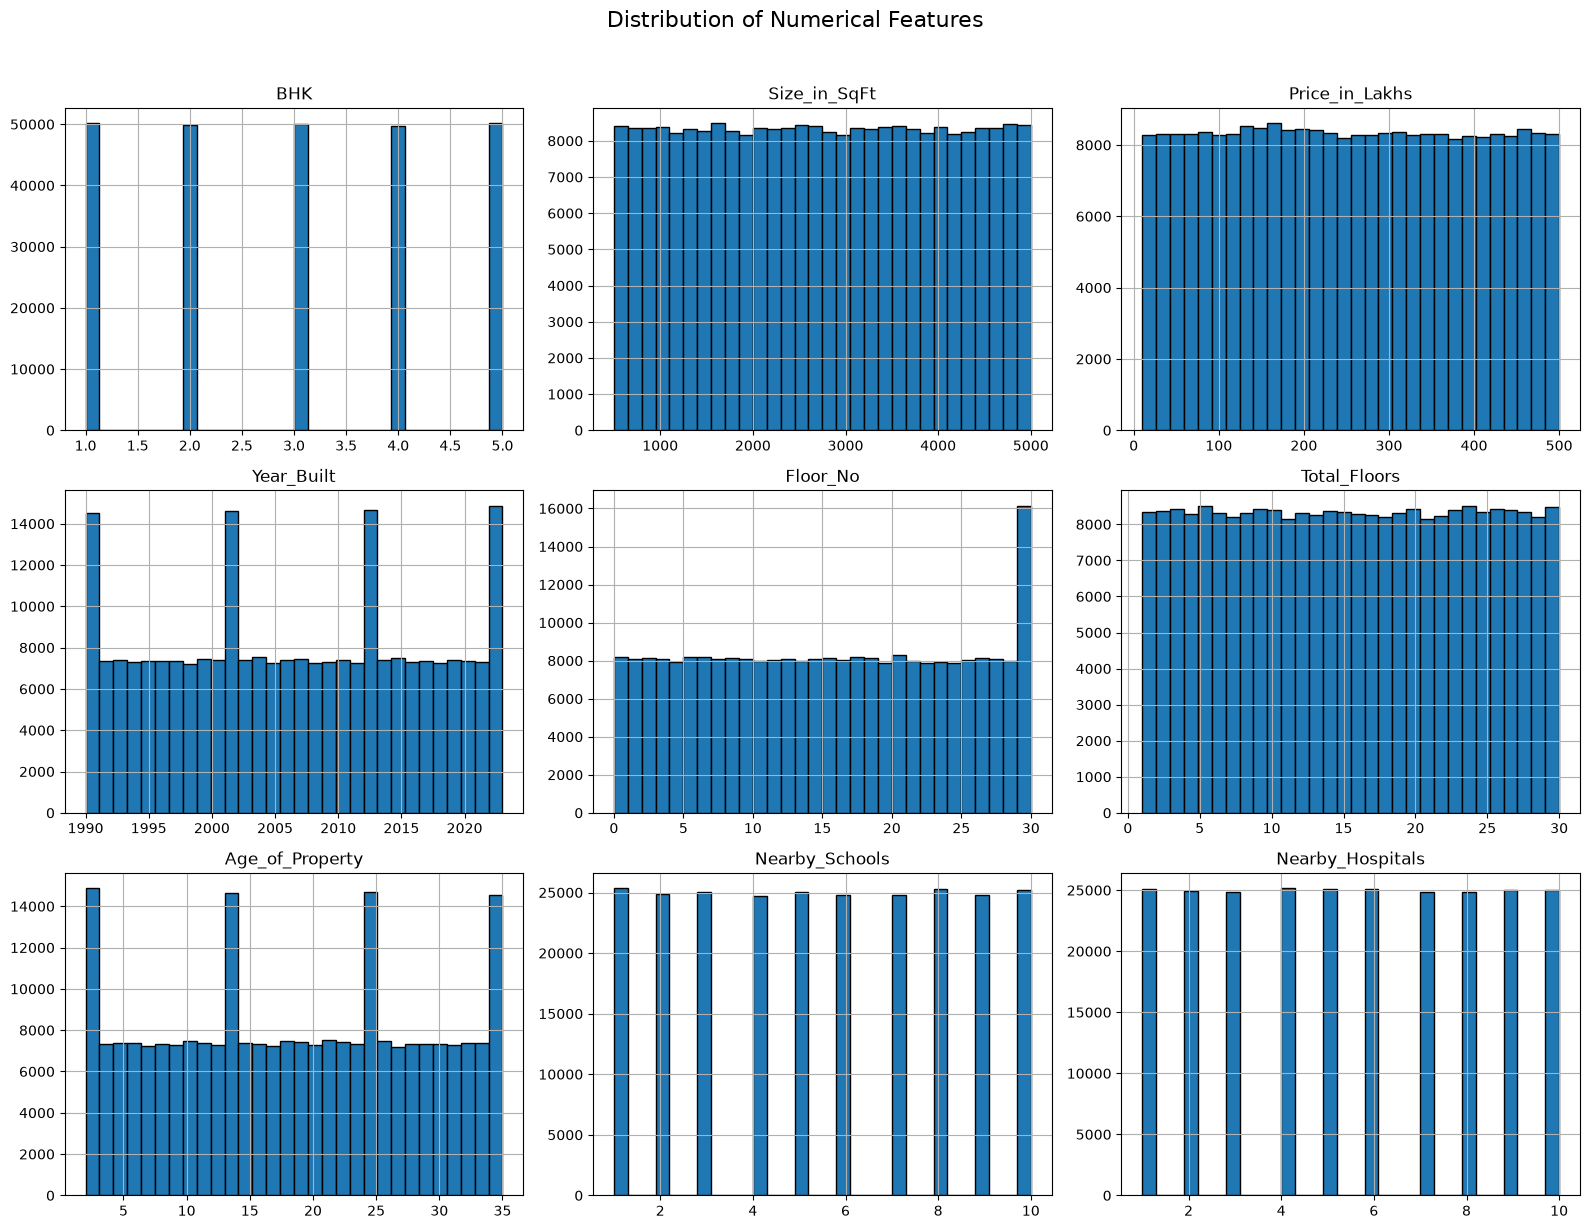

In [20]:
# ==========================================
# STEP 12: NUMERICAL FEATURE DISTRIBUTIONS
# ==========================================

numerical_columns = [
    "BHK",
    "Size_in_SqFt",
    "Price_in_Lakhs",
    "Year_Built",
    "Floor_No",
    "Total_Floors",
    "Age_of_Property",
    "Nearby_Schools",
    "Nearby_Hospitals"
]

df[numerical_columns].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

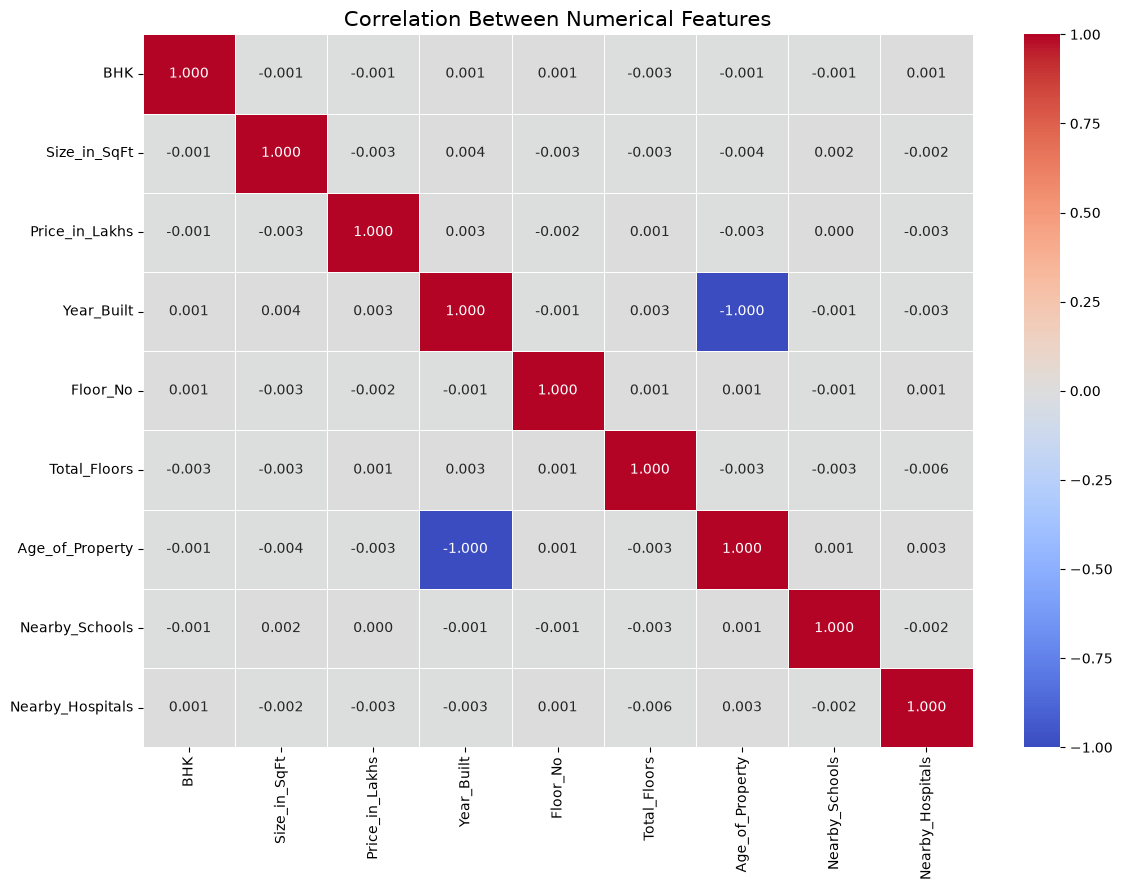

Correlation with Price_in_Lakhs:


,Correlation
Nearby_Hospitals,-0.00
Year_Built,0.00
Age_of_Property,-0.00
Size_in_SqFt,-0.00
Floor_No,-0.00
Total_Floors,0.00
BHK,-0.00
Nearby_Schools,0.00


In [21]:
# ==========================================
# STEP 13: NUMERICAL CORRELATION ANALYSIS
# ==========================================

correlation_columns = [
    "BHK",
    "Size_in_SqFt",
    "Price_in_Lakhs",
    "Year_Built",
    "Floor_No",
    "Total_Floors",
    "Age_of_Property",
    "Nearby_Schools",
    "Nearby_Hospitals"
]

correlation_matrix = df[correlation_columns].corr(
    method="pearson"
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    linewidths=0.5,
    center=0
)

plt.title(
    "Correlation Between Numerical Features",
    fontsize=15
)

plt.tight_layout()
plt.show()

# Show correlation with the target
target_correlation = (
    correlation_matrix["Price_in_Lakhs"]
    .drop("Price_in_Lakhs")
    .sort_values(key=abs, ascending=False)
)

print("Correlation with Price_in_Lakhs:")
display(target_correlation.to_frame("Correlation"))

In [22]:
# ==========================================
# STEP 14: CATEGORICAL FEATURE ASSOCIATION
# ==========================================

from scipy.stats import f_oneway

categorical_columns = [
    "State",
    "City",
    "Locality",
    "Property_Type",
    "Furnished_Status",
    "Public_Transport_Accessibility",
    "Parking_Space",
    "Security",
    "Amenities",
    "Facing",
    "Owner_Type",
    "Availability_Status"
]

target = "Price_in_Lakhs"

results = []

total_mean = df[target].mean()

total_ss = (
    (df[target] - total_mean) ** 2
).sum()

for column in categorical_columns:

    grouped = df.groupby(
        column,
        observed=True
    )[target]

    group_means = grouped.mean()
    group_counts = grouped.count()

    # Between-group sum of squares
    between_ss = (
        group_counts * (group_means - total_mean) ** 2
    ).sum()

    # Eta-squared
    eta_squared = between_ss / total_ss

    # One-way ANOVA
    groups = [
        group[target].values
        for _, group in df.groupby(
            column,
            observed=True
        )
    ]

    f_statistic, p_value = f_oneway(*groups)

    results.append({
        "Feature": column,
        "Unique_Values": df[column].nunique(),
        "Eta_Squared": eta_squared,
        "Variance_Explained_Percent": eta_squared * 100,
        "F_Statistic": f_statistic,
        "P_Value": p_value
    })

categorical_results = pd.DataFrame(results)

categorical_results = categorical_results.sort_values(
    by="Eta_Squared",
    ascending=False
)

display(
    categorical_results.style.format({
        "Eta_Squared": "{:.6f}",
        "Variance_Explained_Percent": "{:.4f}%",
        "F_Statistic": "{:.4f}",
        "P_Value": "{:.6e}"
    })
)

,Feature,Unique_Values,Eta_Squared,Variance_Explained_Percent,F_Statistic,P_Value
2,Locality,500,0.002041,0.2041%,1.0226,3.540598e-01
8,Amenities,325,0.001101,0.1101%,0.8493,9.770277e-01
1,City,42,0.000190,0.0190%,1.1599,2.232264e-01
0,State,20,0.000097,0.0097%,1.2711,1.904369e-01
3,Property_Type,3,0.000022,0.0022%,2.6972,6.739597e-02
7,Security,2,0.000015,0.0015%,3.6261,5.688279e-02
5,Public_Transport_Accessibility,3,0.000009,0.0009%,1.1742,3.090726e-01
11,Availability_Status,2,0.000008,0.0008%,1.9703,1.604131e-01
9,Facing,4,0.000006,0.0006%,0.5195,6.688275e-01
4,Furnished_Status,3,0.000004,0.0004%,0.4963,6.087714e-01


TARGET VARIABLE: PRICE_IN_LAKHS

1. Descriptive Statistics


,Value
count,250000.00
mean,254.59
std,141.35
min,10.00
1%,14.93
5%,34.55
10%,59.24
25%,132.55
50%,253.87
75%,376.88



2. Unique Values
Total records: 250000
Unique price values: 48700
Percentage of unique values: 19.48 %

3. Ten Most Frequent Prices


,Frequency
Price_in_Lakhs,
42.76,16
316.07,16
292.91,16
423.58,16
40.22,16
137.92,16
454.02,15
497.89,15
372.93,15



4. Distribution Shape
Skewness: 0.0082
Kurtosis: -1.1988


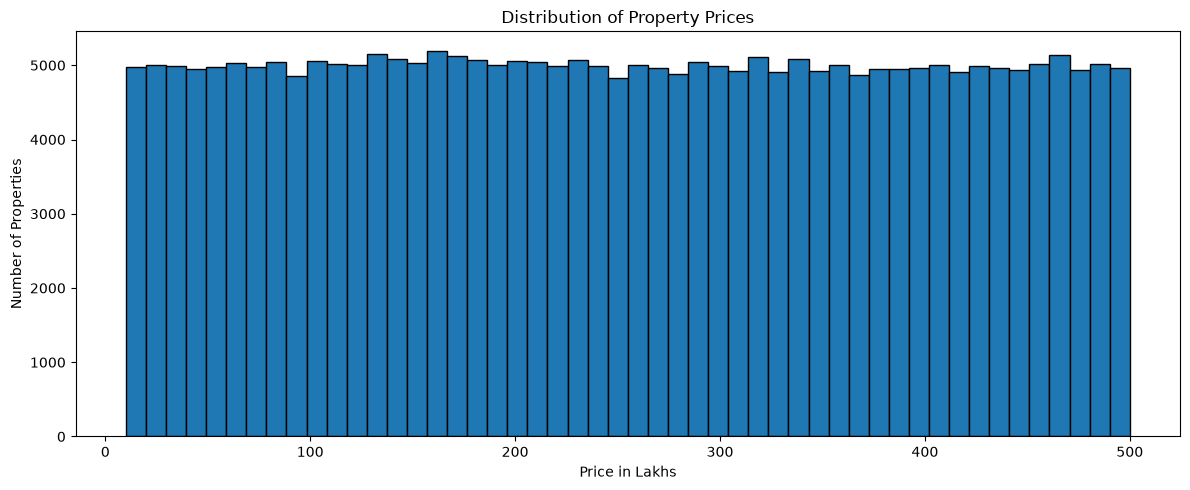

In [23]:
# ==========================================
# STEP 15: TARGET VARIABLE DISTRIBUTION AUDIT
# ==========================================

target = "Price_in_Lakhs"

print("=" * 60)
print("TARGET VARIABLE: PRICE_IN_LAKHS")
print("=" * 60)

# Descriptive statistics
print("\n1. Descriptive Statistics")

display(
    df[target].describe(
        percentiles=[
            0.01, 0.05, 0.10, 0.25,
            0.50, 0.75, 0.90, 0.95, 0.99
        ]
    ).to_frame("Value")
)

# Unique price values
print("\n2. Unique Values")

print("Total records:", len(df))
print("Unique price values:", df[target].nunique())
print(
    "Percentage of unique values:",
    round(df[target].nunique() / len(df) * 100, 2),
    "%"
)

# Most frequent price values
print("\n3. Ten Most Frequent Prices")

display(
    df[target]
    .value_counts()
    .head(10)
    .to_frame("Frequency")
)

# Skewness and kurtosis
print("\n4. Distribution Shape")

print("Skewness:", round(df[target].skew(), 4))
print("Kurtosis:", round(df[target].kurtosis(), 4))

# Price distribution with 50 equal-width bins
plt.figure(figsize=(12, 5))

plt.hist(
    df[target],
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Property Prices")
plt.xlabel("Price in Lakhs")
plt.ylabel("Number of Properties")
plt.tight_layout()
plt.show()

UNIFORM DISTRIBUTION VALIDATION

1. Bin Frequency Analysis
Number of bins: 50
Expected count per bin: 5000.0
Minimum observed count: 4834
Maximum observed count: 5197
Coefficient of variation: 0.0151

2. Chi-Square Goodness-of-Fit Test
Chi-square statistic: 56.758
P-value: 2.0830229752e-01

Result: Do not reject the uniform-distribution hypothesis at the 5% significance level.


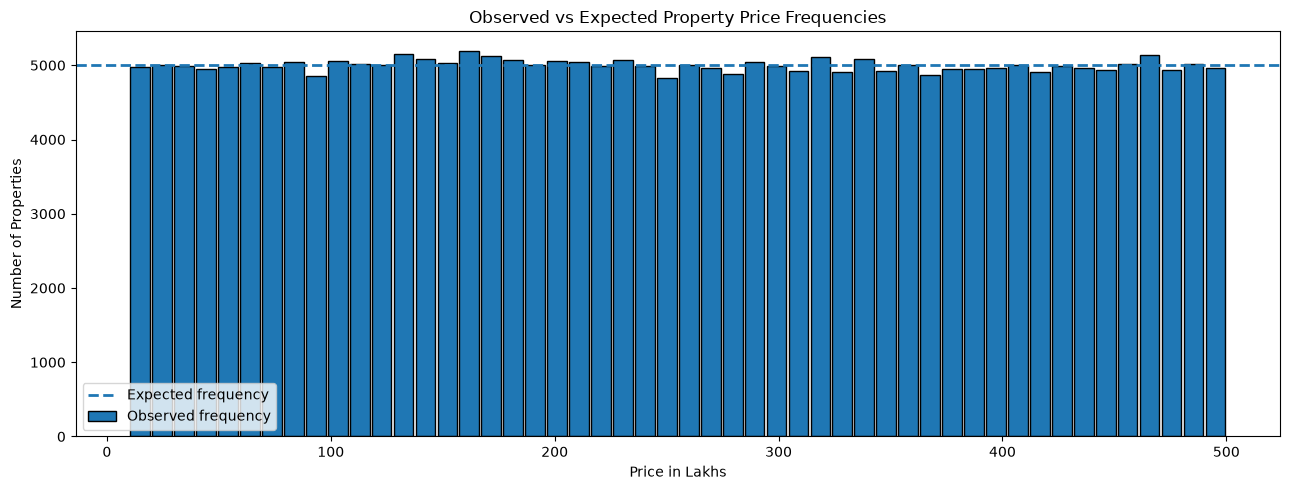

In [24]:
# ==========================================
# STEP 16: UNIFORM DISTRIBUTION VALIDATION
# ==========================================

from scipy.stats import chisquare

target = df["Price_in_Lakhs"]

# Define 50 equal-width bins across the observed range
number_of_bins = 50

observed_counts, bin_edges = np.histogram(
    target,
    bins=number_of_bins,
    range=(10, 500)
)

# Expected frequency for each bin
expected_counts = np.full(
    number_of_bins,
    len(target) / number_of_bins
)

# Chi-square goodness-of-fit test
chi_statistic, p_value = chisquare(
    f_obs=observed_counts,
    f_exp=expected_counts
)

# Frequency variation
count_cv = (
    observed_counts.std() / observed_counts.mean()
)

print("=" * 60)
print("UNIFORM DISTRIBUTION VALIDATION")
print("=" * 60)

print("\n1. Bin Frequency Analysis")

print("Number of bins:", number_of_bins)
print("Expected count per bin:", expected_counts[0])
print("Minimum observed count:", observed_counts.min())
print("Maximum observed count:", observed_counts.max())
print("Coefficient of variation:", round(count_cv, 4))

print("\n2. Chi-Square Goodness-of-Fit Test")

print("Chi-square statistic:", round(chi_statistic, 4))
print("P-value:", f"{p_value:.10e}")

if p_value < 0.05:
    print(
        "\nResult: Reject the exact uniform-distribution "
        "hypothesis at the 5% significance level."
    )
else:
    print(
        "\nResult: Do not reject the uniform-distribution "
        "hypothesis at the 5% significance level."
    )

# Visualize observed versus expected frequencies
plt.figure(figsize=(13, 5))

bin_centers = (
    bin_edges[:-1] + bin_edges[1:]
) / 2

plt.bar(
    bin_centers,
    observed_counts,
    width=(bin_edges[1] - bin_edges[0]) * 0.9,
    edgecolor="black",
    label="Observed frequency"
)

plt.axhline(
    expected_counts[0],
    linestyle="--",
    linewidth=2,
    label="Expected frequency"
)

plt.title("Observed vs Expected Property Price Frequencies")
plt.xlabel("Price in Lakhs")
plt.ylabel("Number of Properties")
plt.legend()
plt.tight_layout()
plt.show()

Mutual Information Scores:


,Feature,Mutual_Information
0,BHK,0.002430
3,Floor_No,0.001394
12,Public_Transport_Accessibility,0.001365
6,Nearby_Hospitals,0.001030
11,Furnished_Status,0.000896
9,Locality,0.000661
2,Year_Built,0.000597
1,Size_in_SqFt,0.000595
8,City,0.000560
5,Nearby_Schools,0.000495


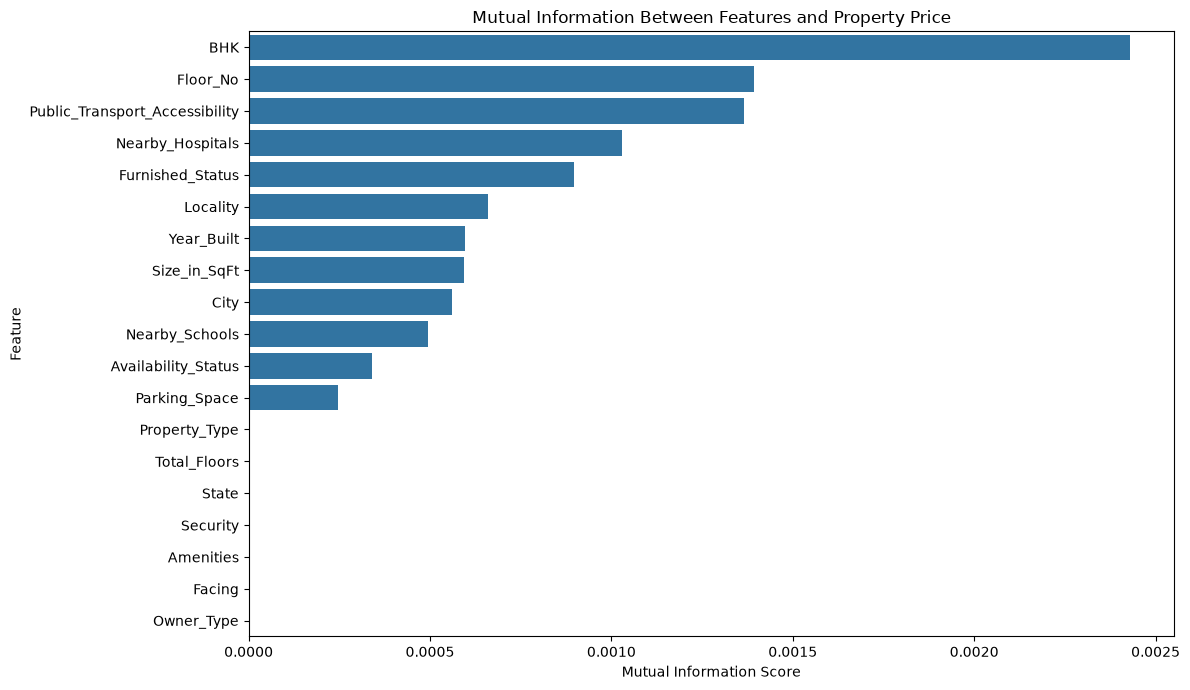

In [25]:
# ==========================================
# STEP 17: MUTUAL INFORMATION ANALYSIS
# ==========================================

from sklearn.feature_selection import mutual_info_regression
from sklearn.preprocessing import OrdinalEncoder

# Numerical features
numeric_features = [
    "BHK",
    "Size_in_SqFt",
    "Year_Built",
    "Floor_No",
    "Total_Floors",
    "Nearby_Schools",
    "Nearby_Hospitals"
]

# Categorical features
categorical_features = [
    "State",
    "City",
    "Locality",
    "Property_Type",
    "Furnished_Status",
    "Public_Transport_Accessibility",
    "Parking_Space",
    "Security",
    "Amenities",
    "Facing",
    "Owner_Type",
    "Availability_Status"
]

feature_columns = numeric_features + categorical_features

# Create a separate feature dataframe
X_mi = df[feature_columns].copy()
y_mi = df["Price_in_Lakhs"].copy()

# Encode categorical columns as integer category codes
encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

X_mi[categorical_features] = encoder.fit_transform(
    X_mi[categorical_features]
)

# Mark categorical columns as discrete
discrete_mask = [
    False
] * len(numeric_features) + [
    True
] * len(categorical_features)

# Calculate mutual information
mi_scores = mutual_info_regression(
    X_mi,
    y_mi,
    discrete_features=discrete_mask,
    random_state=42
)

# Create results table
mi_results = pd.DataFrame({
    "Feature": feature_columns,
    "Mutual_Information": mi_scores
})

mi_results = mi_results.sort_values(
    by="Mutual_Information",
    ascending=False
)

print("Mutual Information Scores:")

display(
    mi_results.style.format({
        "Mutual_Information": "{:.6f}"
    })
)

# Visualize results
plt.figure(figsize=(12, 7))

sns.barplot(
    data=mi_results,
    x="Mutual_Information",
    y="Feature"
)

plt.title(
    "Mutual Information Between Features and Property Price"
)

plt.xlabel("Mutual Information Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

,Feature,Mutual_Information
0,BHK,0.002621
1,Year_Built,0.001089
2,Floor_No,0.000709
5,Nearby_Hospitals,0.000697
13,Parking_Space,0.000695
9,Locality,0.000656
6,Size_in_SqFt,0.000617
11,Furnished_Status,0.000614
8,City,0.000539
12,Public_Transport_Accessibility,0.000532


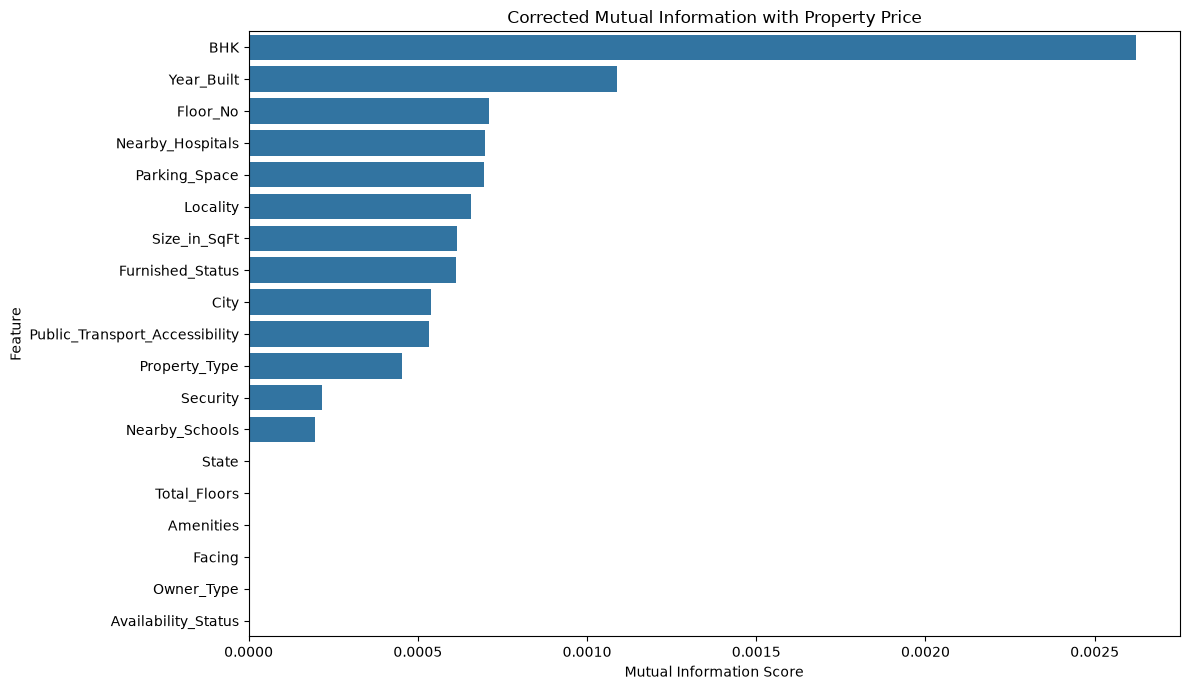

In [26]:
# ==========================================
# STEP 18: CORRECTED MUTUAL INFORMATION
# ==========================================

from sklearn.feature_selection import mutual_info_regression
from sklearn.preprocessing import OrdinalEncoder

# Discrete numerical features
discrete_numeric_features = [
    "BHK",
    "Year_Built",
    "Floor_No",
    "Total_Floors",
    "Nearby_Schools",
    "Nearby_Hospitals"
]

# Continuous numerical features
continuous_numeric_features = [
    "Size_in_SqFt"
]

# Categorical features
categorical_features = [
    "State",
    "City",
    "Locality",
    "Property_Type",
    "Furnished_Status",
    "Public_Transport_Accessibility",
    "Parking_Space",
    "Security",
    "Amenities",
    "Facing",
    "Owner_Type",
    "Availability_Status"
]

feature_columns = (
    discrete_numeric_features
    + continuous_numeric_features
    + categorical_features
)

X_mi = df[feature_columns].copy()
y_mi = df["Price_in_Lakhs"].copy()

# Encode categorical variables
encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

X_mi[categorical_features] = encoder.fit_transform(
    X_mi[categorical_features]
)

# Correctly identify discrete and continuous features
discrete_mask = (
    [True] * len(discrete_numeric_features)
    + [False] * len(continuous_numeric_features)
    + [True] * len(categorical_features)
)

# Calculate mutual information
mi_scores_corrected = mutual_info_regression(
    X_mi,
    y_mi,
    discrete_features=discrete_mask,
    random_state=42
)

# Results
mi_corrected_results = pd.DataFrame({
    "Feature": feature_columns,
    "Mutual_Information": mi_scores_corrected
})

mi_corrected_results = mi_corrected_results.sort_values(
    by="Mutual_Information",
    ascending=False
)

display(
    mi_corrected_results.style.format({
        "Mutual_Information": "{:.6f}"
    })
)

# Visualization
plt.figure(figsize=(12, 7))

sns.barplot(
    data=mi_corrected_results,
    x="Mutual_Information",
    y="Feature"
)

plt.title("Corrected Mutual Information with Property Price")
plt.xlabel("Mutual Information Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

PROPERTY PRICE ANALYSIS BY BHK


,Count,Mean,Median,Std_Dev,Minimum,Maximum
BHK,,,,,,
1,50196,254.88,254.06,141.36,10.00,499.97
2,49815,254.80,253.30,141.29,10.01,499.99
3,50067,254.09,253.13,141.29,10.00,499.99
4,49788,254.78,254.92,141.35,10.04,500.00
5,50134,254.39,253.87,141.46,10.03,499.99



ANOVA Results
F-statistic: 0.283221
P-value: 8.8901987850e-01
Eta-squared: 4.53e-06
Variance explained: 0.000453 %


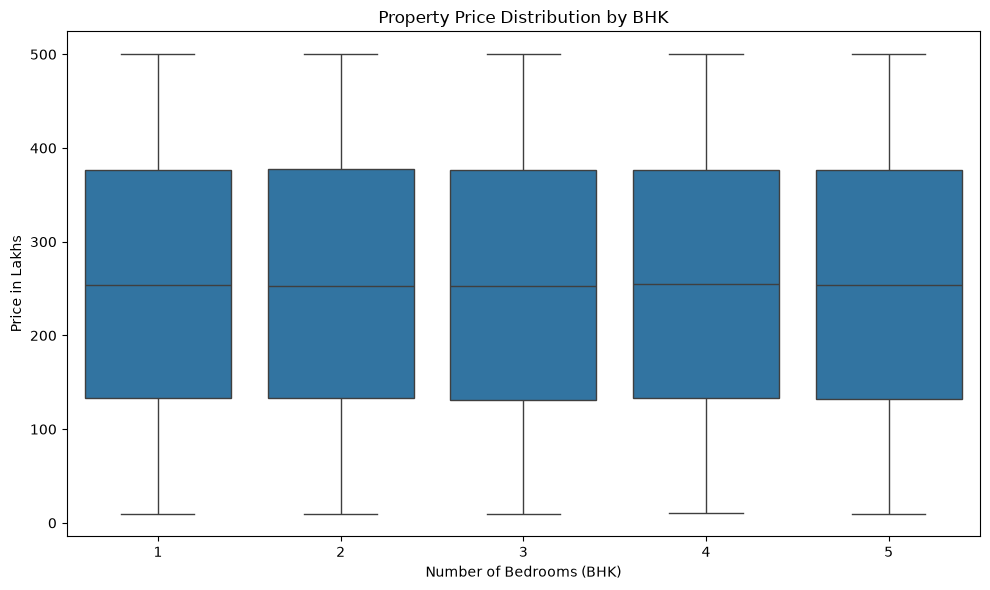

In [27]:
# ==========================================
# STEP 19: PRICE ANALYSIS BY BHK
# ==========================================

from scipy.stats import f_oneway

print("=" * 65)
print("PROPERTY PRICE ANALYSIS BY BHK")
print("=" * 65)

# Summary statistics by BHK
bhk_summary = (
    df.groupby("BHK")["Price_in_Lakhs"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Std_Dev="std",
        Minimum="min",
        Maximum="max"
    )
)

display(
    bhk_summary.style.format({
        "Mean": "{:.2f}",
        "Median": "{:.2f}",
        "Std_Dev": "{:.2f}",
        "Minimum": "{:.2f}",
        "Maximum": "{:.2f}"
    })
)

# One-way ANOVA
bhk_groups = [
    group["Price_in_Lakhs"].values
    for _, group in df.groupby("BHK")
]

f_statistic, p_value = f_oneway(*bhk_groups)

print("\nANOVA Results")
print("F-statistic:", round(f_statistic, 6))
print("P-value:", f"{p_value:.10e}")

# Eta-squared effect size
grand_mean = df["Price_in_Lakhs"].mean()

total_ss = (
    (df["Price_in_Lakhs"] - grand_mean) ** 2
).sum()

between_ss = sum(
    len(group) * (group.mean() - grand_mean) ** 2
    for _, group in df.groupby("BHK")["Price_in_Lakhs"]
)

eta_squared = between_ss / total_ss

print("Eta-squared:", round(eta_squared, 8))
print(
    "Variance explained:",
    round(eta_squared * 100, 6),
    "%"
)

# Visualize price distribution by BHK
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="BHK",
    y="Price_in_Lakhs"
)

plt.title("Property Price Distribution by BHK")
plt.xlabel("Number of Bedrooms (BHK)")
plt.ylabel("Price in Lakhs")

plt.tight_layout()
plt.show()

PROPERTY SIZE VS PROPERTY PRICE

1. Pearson Correlation
Correlation: -0.002529
P-value: 2.0613345797e-01

2. Spearman Correlation
Correlation: -0.002529
P-value: 2.0601343844e-01


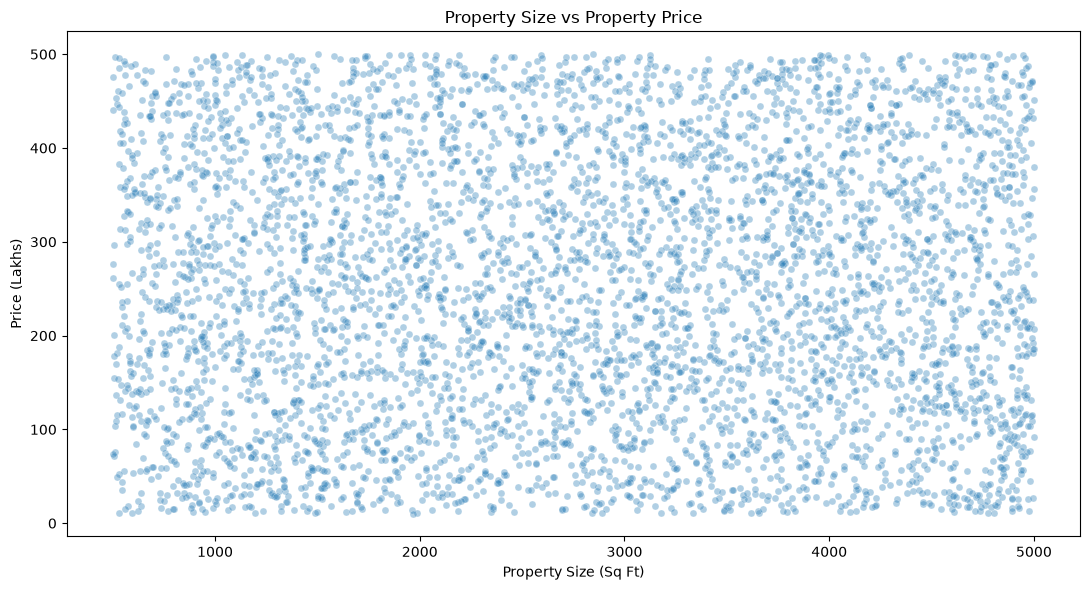

In [28]:
# ==========================================
# STEP 20: PROPERTY SIZE VS PRICE ANALYSIS
# ==========================================

from scipy.stats import pearsonr, spearmanr

x = df["Size_in_SqFt"]
y = df["Price_in_Lakhs"]

# Correlation tests
pearson_corr, pearson_p = pearsonr(x, y)

spearman_corr, spearman_p = spearmanr(x, y)

print("=" * 65)
print("PROPERTY SIZE VS PROPERTY PRICE")
print("=" * 65)

print("\n1. Pearson Correlation")
print("Correlation:", round(pearson_corr, 6))
print("P-value:", f"{pearson_p:.10e}")

print("\n2. Spearman Correlation")
print("Correlation:", round(spearman_corr, 6))
print("P-value:", f"{spearman_p:.10e}")

# Sample 5,000 records for visualization
sample_df = df.sample(
    n=5000,
    random_state=42
)

plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=sample_df,
    x="Size_in_SqFt",
    y="Price_in_Lakhs",
    alpha=0.35,
    s=25
)

plt.title("Property Size vs Property Price")
plt.xlabel("Property Size (Sq Ft)")
plt.ylabel("Price (Lakhs)")

plt.tight_layout()
plt.show()

In [29]:
# ==========================================
# STEP 21: MULTIPLE-FEATURE REGRESSION
# DIAGNOSTIC
# ==========================================

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Select features
numeric_features = [
    "BHK",
    "Size_in_SqFt",
    "Year_Built",
    "Nearby_Schools",
    "Nearby_Hospitals"
]

categorical_features = [
    "State",
    "City",
    "Locality",
    "Property_Type",
    "Furnished_Status",
    "Public_Transport_Accessibility",
    "Parking_Space",
    "Security",
    "Amenities",
    "Facing",
    "Owner_Type",
    "Availability_Status"
]

features = numeric_features + categorical_features

X = df[features].copy()
y = df["Price_in_Lakhs"].copy()

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Models
models = {
    "Dummy Baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ])
}

results = []

for model_name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)

display(
    results_df.style.format({
        "MAE": "{:.4f}",
        "RMSE": "{:.4f}",
        "R2": "{:.6f}"
    })
)

,Model,MAE,RMSE,R2
0,Dummy Baseline,122.3178,141.1932,-0.000001
1,Linear Regression,122.4387,141.4652,-0.003857


In [30]:
# ==========================================
# STEP 22: SAVE DATA AUDIT REPORT
# ==========================================

from pathlib import Path

report = """
REAL ESTATE INVESTMENT ADVISOR
DATASET AUDIT REPORT
==========================================

Dataset:
india_housing_prices.csv

Records:
250,000

Columns:
23

DATA QUALITY:
- Missing values: 0
- Complete duplicate rows: 0
- Duplicate IDs: 0

FEATURE VALIDATION:
- Year_Built + Age_of_Property = 2025
  for all records.
- Price_per_SqFt is derived from
  Price_in_Lakhs / Size_in_SqFt.
- Floor_No exceeds Total_Floors in
  116,304 records (46.52%).
- 2,534 zero Price_per_SqFt values
  are explained by rounding.
- 21 Price_per_SqFt formula mismatches.

TARGET ANALYSIS:
- Target: Price_in_Lakhs
- Mean: 254.59
- Standard deviation: 141.35
- Minimum: 10.00
- Maximum: 500.00
- Skewness: 0.0082
- Excess kurtosis: -1.1988
- Chi-square uniformity test p-value: 0.2083

PREDICTIVE SIGNAL:
- Numerical correlations are approximately zero.
- Categorical eta-squared values are negligible.
- Mutual information scores are extremely low.
- BHK explains approximately 0.000453%
  of target variance.
- Property size has almost zero correlation
  with property price.

REGRESSION DIAGNOSTIC:
Dummy Baseline:
MAE  = 122.3178
RMSE = 141.1932
R2   = -0.000001

Linear Regression:
MAE  = 122.4387
RMSE = 141.4652
R2   = -0.003857

CONCLUSION:
The available dataset shows insufficient
evidence of meaningful relationships between
property characteristics and current prices.

Complex model tuning is not justified until
additional predictive signal is established.

IMPORTANT:
The original raw dataset must remain unchanged.
Price_per_SqFt must not be used as a predictor
for Price_in_Lakhs because it is target-derived.
"""

report_path = (
    Path.cwd().parent
    / "data"
    / "processed"
    / "dataset_audit_report.txt"
)

report_path.parent.mkdir(parents=True, exist_ok=True)

report_path.write_text(
    report,
    encoding="utf-8"
)

print("Audit report saved successfully:")
print(report_path)

Audit report saved successfully:
C:\Users\rahul\Real-Estate-Investment-Advisor\data\processed\dataset_audit_report.txt


In [31]:
# ==========================================
# STEP 23: CREATE MARKET ANALYSIS DATAFRAME
# ==========================================

market_df = df.copy()

print("Original dataset shape:", df.shape)
print("Market analysis dataset shape:", market_df.shape)

print("\nDataset preview:")
display(market_df.head())

print("\nDataset information:")
market_df.info()

Original dataset shape: (250000, 23)
Market analysis dataset shape: (250000, 23)

Dataset preview:


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Furnished_Status,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,Furnished,22,1,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,Unfurnished,21,20,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,Semi-furnished,19,27,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,Furnished,21,26,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,Semi-furnished,3,2,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 23 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   ID                              250000 non-null  int64  
 1   State                           250000 non-null  str    
 2   City                            250000 non-null  str    
 3   Locality                        250000 non-null  str    
 4   Property_Type                   250000 non-null  str    
 5   BHK                             250000 non-null  int64  
 6   Size_in_SqFt                    250000 non-null  int64  
 7   Price_in_Lakhs                  250000 non-null  float64
 8   Price_per_SqFt                  250000 non-null  float64
 9   Year_Built                      250000 non-null  int64  
 10  Furnished_Status                250000 non-null  str    
 11  Floor_No                        250000 non-null  int64  
 12  Total

PROPERTY DISTRIBUTION BY STATE


,Total_Properties,Average_Price,Median_Price,Average_Size,Property_Share_Percent
State,,,,,
Odisha,12681,252.84,250.99,2757.44,5.07%
Tamil Nadu,12629,256.66,256.32,2761.16,5.05%
West Bengal,12622,254.01,250.93,2758.13,5.05%
Gujarat,12578,255.79,256.63,2753.51,5.03%
Delhi,12552,252.53,250.41,2749.71,5.02%
Telangana,12539,255.54,254.75,2751.07,5.02%
Maharashtra,12533,254.71,254.54,2739.82,5.01%
Punjab,12516,252.80,250.51,2747.48,5.01%
Uttar Pradesh,12508,256.25,257.41,2740.49,5.00%


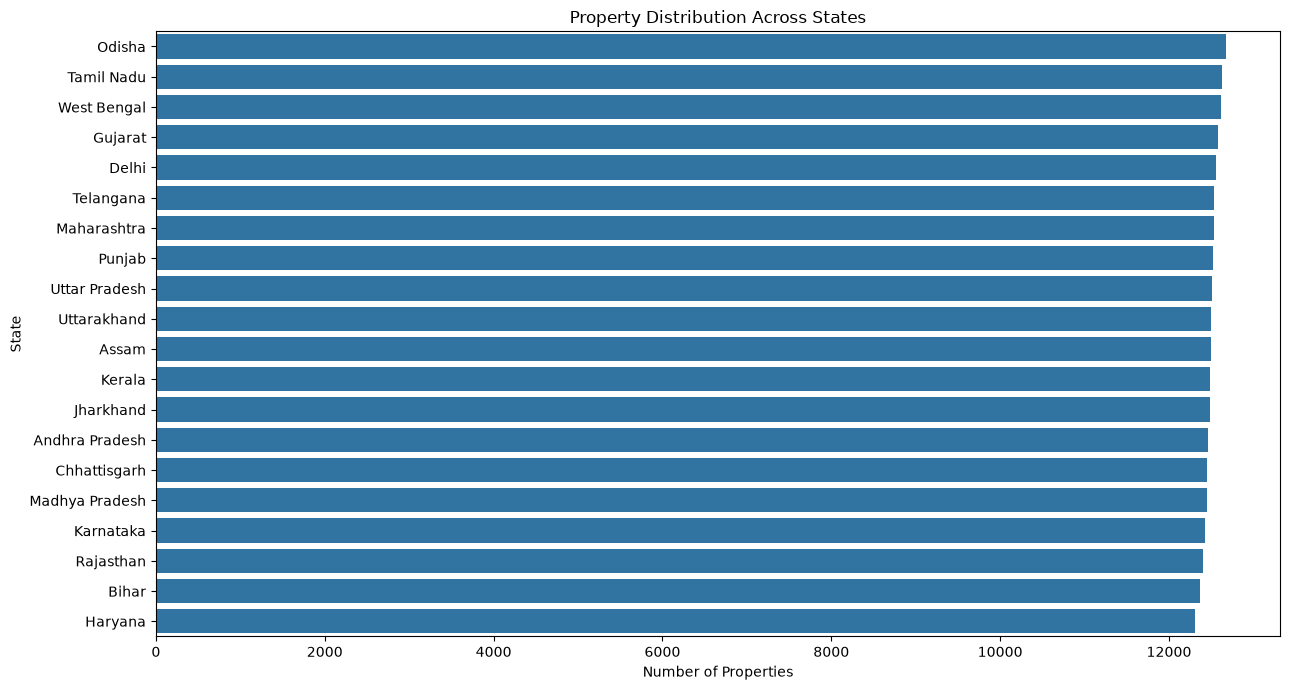

In [32]:
# ==========================================
# STEP 24: PROPERTY DISTRIBUTION BY STATE
# ==========================================

state_summary = (
    market_df.groupby("State")
    .agg(
        Total_Properties=("ID", "count"),
        Average_Price=("Price_in_Lakhs", "mean"),
        Median_Price=("Price_in_Lakhs", "median"),
        Average_Size=("Size_in_SqFt", "mean")
    )
    .sort_values(
        by="Total_Properties",
        ascending=False
    )
)

# Calculate percentage of total properties
state_summary["Property_Share_Percent"] = (
    state_summary["Total_Properties"]
    / len(market_df) * 100
)

print("PROPERTY DISTRIBUTION BY STATE")

display(
    state_summary.style.format({
        "Average_Price": "{:.2f}",
        "Median_Price": "{:.2f}",
        "Average_Size": "{:.2f}",
        "Property_Share_Percent": "{:.2f}%"
    })
)

# Visualize property counts
plt.figure(figsize=(13, 7))

sns.barplot(
    data=state_summary.reset_index(),
    x="Total_Properties",
    y="State"
)

plt.title("Property Distribution Across States")
plt.xlabel("Number of Properties")
plt.ylabel("State")
plt.tight_layout()
plt.show()

PROPERTY DISTRIBUTION BY CITY


,,Total_Properties,Average_Price,Median_Price,Average_Size,Average_BHK,Property_Share_Percent
State,City,,,,,,
Tamil Nadu,Coimbatore,6461,256.50,255.68,2754.50,3.01,2.58%
Gujarat,Ahmedabad,6411,253.59,255.56,2771.54,3.03,2.56%
Assam,Silchar,6404,252.58,251.44,2723.69,3.03,2.56%
West Bengal,Durgapur,6387,254.10,251.51,2756.66,2.99,2.55%
Odisha,Cuttack,6358,250.79,248.21,2743.28,2.96,2.54%
Andhra Pradesh,Vijayawada,6344,254.64,255.58,2734.91,3.01,2.54%
Jharkhand,Jamshedpur,6335,252.63,251.48,2777.08,3.00,2.53%
Odisha,Bhubaneswar,6323,254.90,252.96,2771.68,3.00,2.53%
Delhi,New Delhi,6306,251.61,249.68,2751.80,3.00,2.52%


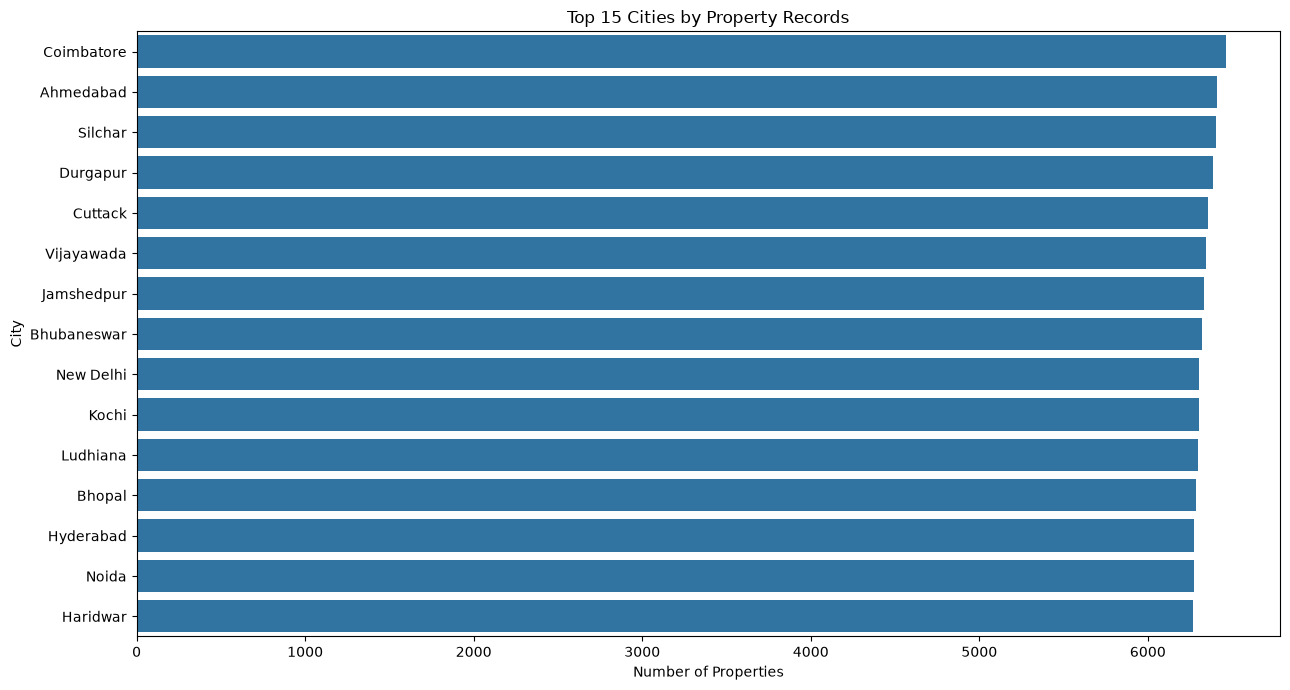

In [33]:
# ==========================================
# STEP 25: PROPERTY DISTRIBUTION BY CITY
# ==========================================

city_summary = (
    market_df.groupby(["State", "City"])
    .agg(
        Total_Properties=("ID", "count"),
        Average_Price=("Price_in_Lakhs", "mean"),
        Median_Price=("Price_in_Lakhs", "median"),
        Average_Size=("Size_in_SqFt", "mean"),
        Average_BHK=("BHK", "mean")
    )
    .sort_values(
        by="Total_Properties",
        ascending=False
    )
)

# Calculate city share
city_summary["Property_Share_Percent"] = (
    city_summary["Total_Properties"]
    / len(market_df) * 100
)

print("PROPERTY DISTRIBUTION BY CITY")

display(
    city_summary.style.format({
        "Average_Price": "{:.2f}",
        "Median_Price": "{:.2f}",
        "Average_Size": "{:.2f}",
        "Average_BHK": "{:.2f}",
        "Property_Share_Percent": "{:.2f}%"
    })
)

# Top 15 cities by property count
top_cities = (
    city_summary
    .reset_index()
    .head(15)
)

plt.figure(figsize=(13, 7))

sns.barplot(
    data=top_cities,
    x="Total_Properties",
    y="City"
)

plt.title("Top 15 Cities by Property Records")
plt.xlabel("Number of Properties")
plt.ylabel("City")

plt.tight_layout()
plt.show()

LOCALITY ANALYSIS

Total unique geographic locality combinations: 20999
Total distinct locality labels: 500


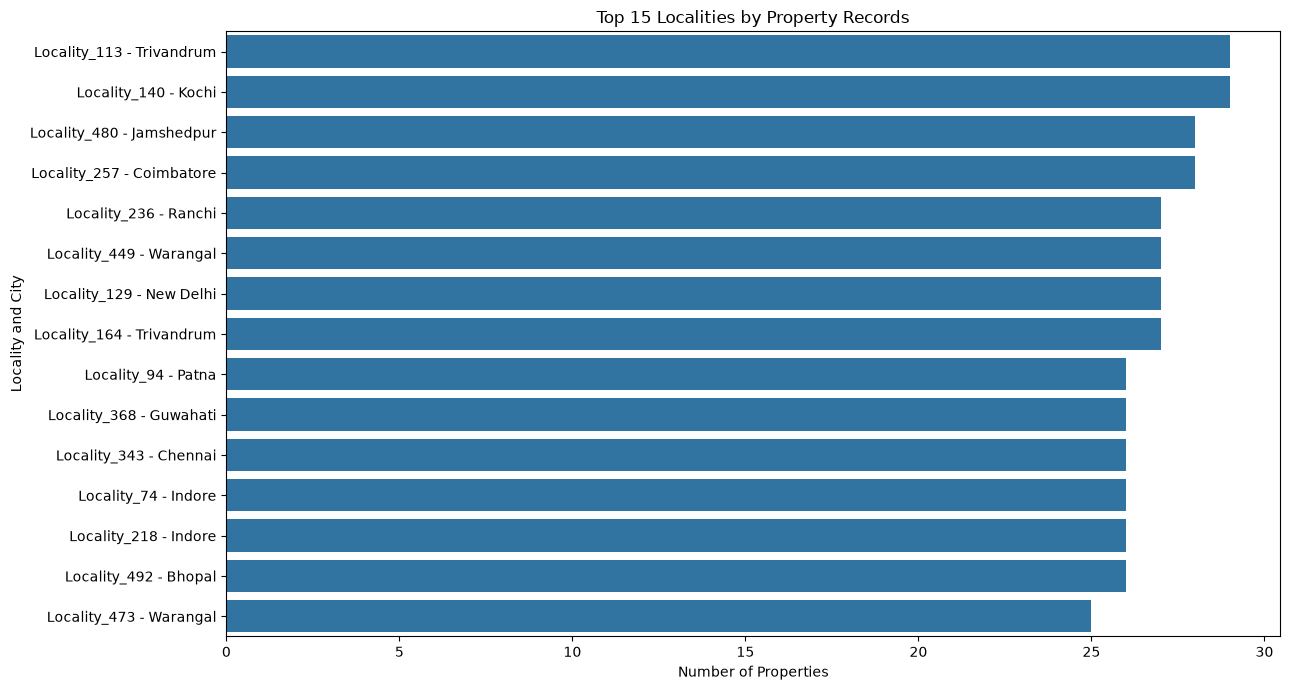

In [34]:
# ==========================================
# STEP 26: PROPERTY DISTRIBUTION BY LOCALITY
# ==========================================

locality_summary = (
    market_df.groupby(
        ["State", "City", "Locality"]
    )
    .agg(
        Total_Properties=("ID", "count"),
        Average_Price=("Price_in_Lakhs", "mean"),
        Median_Price=("Price_in_Lakhs", "median"),
        Average_Size=("Size_in_SqFt", "mean"),
        Average_BHK=("BHK", "mean")
    )
    .sort_values(
        by="Total_Properties",
        ascending=False
    )
)

locality_summary["Property_Share_Percent"] = (
    locality_summary["Total_Properties"]
    / len(market_df) * 100
)

print("LOCALITY ANALYSIS")

print(
    "\nTotal unique geographic locality combinations:",
    len(locality_summary)
)

print(
    "Total distinct locality labels:",
    market_df["Locality"].nunique()
)

# Display top 20 localities
top_localities = locality_summary.head(20)

display(
    top_localities.style.format({
        "Average_Price": "{:.2f}",
        "Median_Price": "{:.2f}",
        "Average_Size": "{:.2f}",
        "Average_BHK": "{:.2f}",
        "Property_Share_Percent": "{:.3f}%"
    })
)

# Visualize top 15 localities
locality_plot = (
    locality_summary
    .reset_index()
    .head(15)
    .copy()
)

locality_plot["Location"] = (
    locality_plot["Locality"]
    + " - "
    + locality_plot["City"]
)

plt.figure(figsize=(13, 7))

sns.barplot(
    data=locality_plot,
    x="Total_Properties",
    y="Location"
)

plt.title("Top 15 Localities by Property Records")
plt.xlabel("Number of Properties")
plt.ylabel("Locality and City")

plt.tight_layout()
plt.show()

PROPERTY TYPE ANALYSIS


,Total_Properties,Average_Price,Median_Price,Average_Size,Average_BHK,Average_Year_Built,Property_Share_Percent
Property_Type,,,,,,,
Villa,83744,253.77,252.53,2755.63,2.99,2006.50,33.50%
Independent House,83300,255.37,255.04,2742.61,3.00,2006.50,33.32%
Apartment,82956,254.62,254.02,2751.17,3.00,2006.55,33.18%


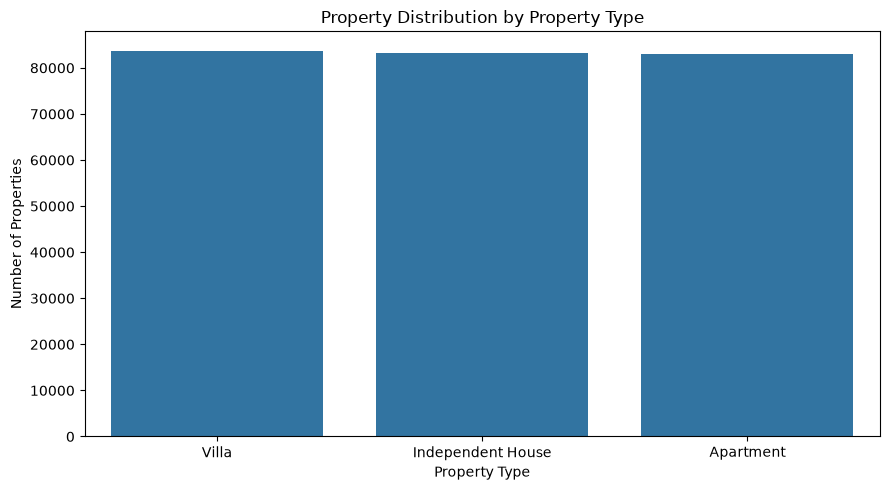

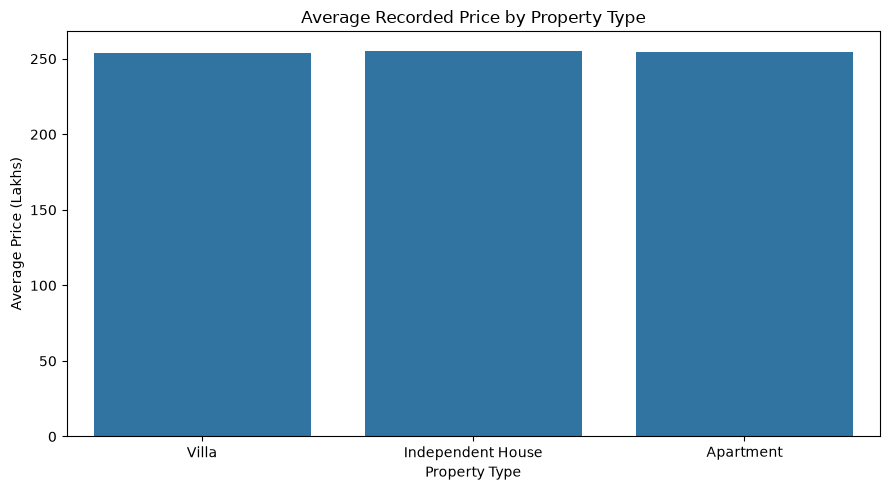

In [35]:
# ==========================================
# STEP 27: PROPERTY TYPE ANALYSIS
# ==========================================

property_type_summary = (
    market_df.groupby("Property_Type")
    .agg(
        Total_Properties=("ID", "count"),
        Average_Price=("Price_in_Lakhs", "mean"),
        Median_Price=("Price_in_Lakhs", "median"),
        Average_Size=("Size_in_SqFt", "mean"),
        Average_BHK=("BHK", "mean"),
        Average_Year_Built=("Year_Built", "mean")
    )
    .sort_values(
        by="Total_Properties",
        ascending=False
    )
)

property_type_summary["Property_Share_Percent"] = (
    property_type_summary["Total_Properties"]
    / len(market_df) * 100
)

print("PROPERTY TYPE ANALYSIS")

display(
    property_type_summary.style.format({
        "Average_Price": "{:.2f}",
        "Median_Price": "{:.2f}",
        "Average_Size": "{:.2f}",
        "Average_BHK": "{:.2f}",
        "Average_Year_Built": "{:.2f}",
        "Property_Share_Percent": "{:.2f}%"
    })
)

# Property count visualization
plt.figure(figsize=(9, 5))

sns.barplot(
    data=property_type_summary.reset_index(),
    x="Property_Type",
    y="Total_Properties"
)

plt.title("Property Distribution by Property Type")
plt.xlabel("Property Type")
plt.ylabel("Number of Properties")

plt.tight_layout()
plt.show()

# Average price visualization
plt.figure(figsize=(9, 5))

sns.barplot(
    data=property_type_summary.reset_index(),
    x="Property_Type",
    y="Average_Price"
)

plt.title("Average Recorded Price by Property Type")
plt.xlabel("Property Type")
plt.ylabel("Average Price (Lakhs)")

plt.tight_layout()
plt.show()

FURNISHED STATUS ANALYSIS


,Total_Properties,Average_Price,Median_Price,Average_Size,Average_BHK,Property_Share_Percent
Furnished_Status,,,,,,
Unfurnished,83408,254.98,254.19,2752.49,3.00,33.36%
Semi-furnished,83374,254.33,253.81,2749.09,2.99,33.35%
Furnished,83218,254.45,253.56,2747.85,3.00,33.29%


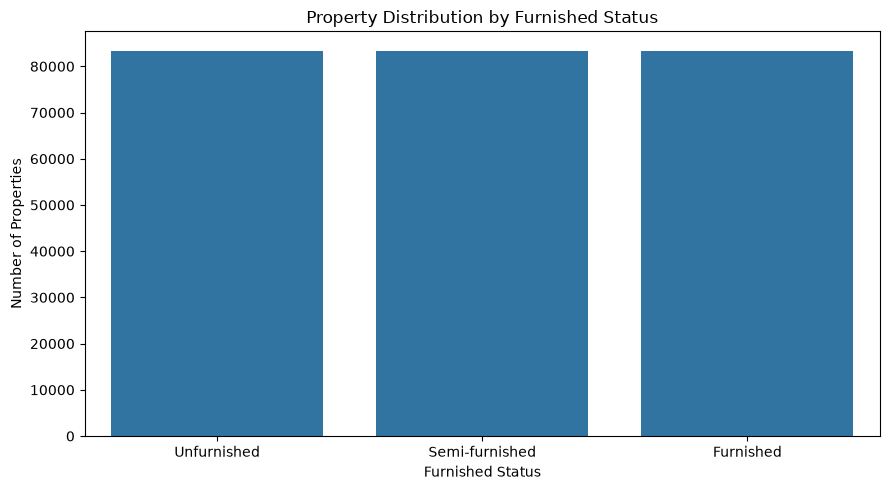

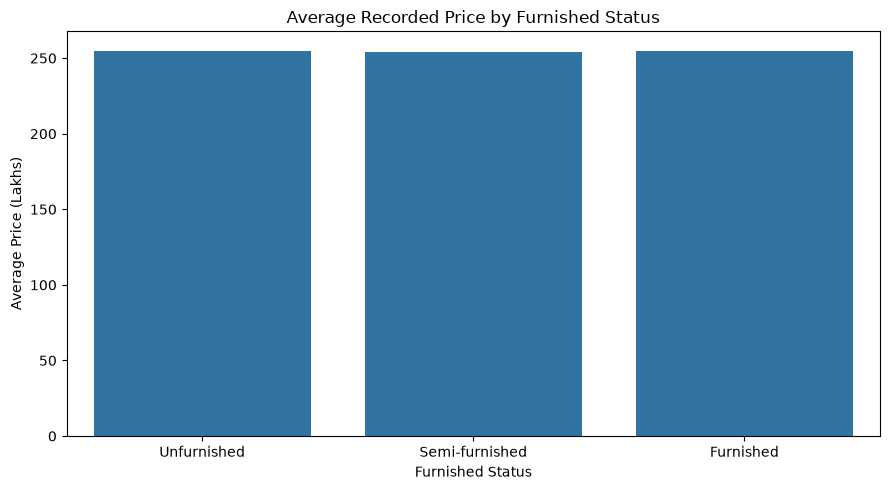

In [36]:
# ==========================================
# STEP 28: FURNISHED STATUS ANALYSIS
# ==========================================

furnished_summary = (
    market_df.groupby("Furnished_Status")
    .agg(
        Total_Properties=("ID", "count"),
        Average_Price=("Price_in_Lakhs", "mean"),
        Median_Price=("Price_in_Lakhs", "median"),
        Average_Size=("Size_in_SqFt", "mean"),
        Average_BHK=("BHK", "mean")
    )
    .sort_values(
        by="Total_Properties",
        ascending=False
    )
)

furnished_summary["Property_Share_Percent"] = (
    furnished_summary["Total_Properties"]
    / len(market_df) * 100
)

print("FURNISHED STATUS ANALYSIS")

display(
    furnished_summary.style.format({
        "Average_Price": "{:.2f}",
        "Median_Price": "{:.2f}",
        "Average_Size": "{:.2f}",
        "Average_BHK": "{:.2f}",
        "Property_Share_Percent": "{:.2f}%"
    })
)

# Property count chart
plt.figure(figsize=(9, 5))

sns.barplot(
    data=furnished_summary.reset_index(),
    x="Furnished_Status",
    y="Total_Properties"
)

plt.title("Property Distribution by Furnished Status")
plt.xlabel("Furnished Status")
plt.ylabel("Number of Properties")

plt.tight_layout()
plt.show()

# Average price chart
plt.figure(figsize=(9, 5))

sns.barplot(
    data=furnished_summary.reset_index(),
    x="Furnished_Status",
    y="Average_Price"
)

plt.title("Average Recorded Price by Furnished Status")
plt.xlabel("Furnished Status")
plt.ylabel("Average Price (Lakhs)")

plt.tight_layout()
plt.show()

PROPERTY AVAILABILITY ANALYSIS


,Total_Properties,Average_Price,Median_Price,Average_Size,Average_BHK,Average_Year_Built,Property_Share_Percent
Availability_Status,,,,,,,
Under_Construction,125035,254.19,253.48,2748.50,3.00,2006.52,50.01%
Ready_to_Move,124965,254.98,254.31,2751.13,3.00,2006.52,49.99%


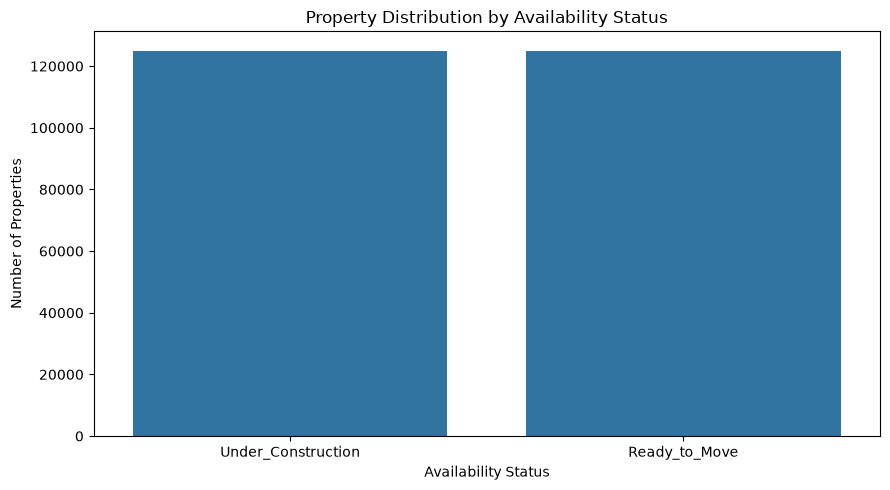

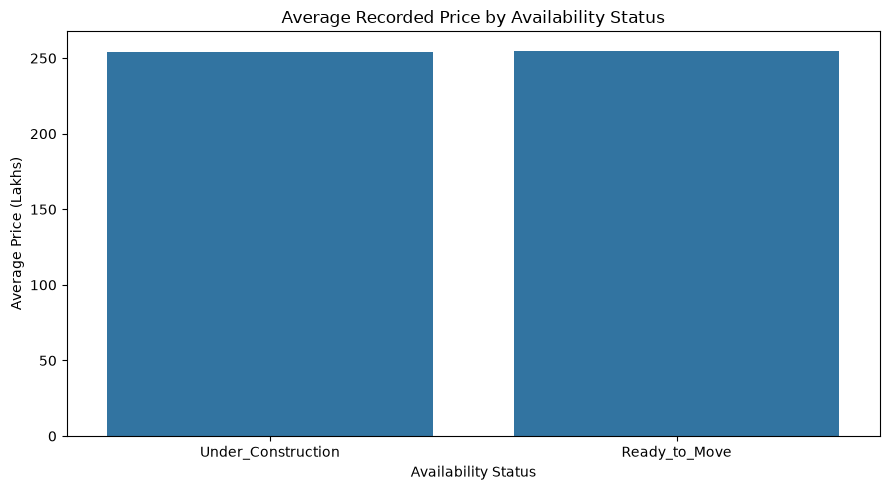

In [37]:
# ==========================================
# STEP 29: PROPERTY AVAILABILITY ANALYSIS
# ==========================================

availability_summary = (
    market_df.groupby("Availability_Status")
    .agg(
        Total_Properties=("ID", "count"),
        Average_Price=("Price_in_Lakhs", "mean"),
        Median_Price=("Price_in_Lakhs", "median"),
        Average_Size=("Size_in_SqFt", "mean"),
        Average_BHK=("BHK", "mean"),
        Average_Year_Built=("Year_Built", "mean")
    )
    .sort_values(
        by="Total_Properties",
        ascending=False
    )
)

availability_summary["Property_Share_Percent"] = (
    availability_summary["Total_Properties"]
    / len(market_df) * 100
)

print("PROPERTY AVAILABILITY ANALYSIS")

display(
    availability_summary.style.format({
        "Average_Price": "{:.2f}",
        "Median_Price": "{:.2f}",
        "Average_Size": "{:.2f}",
        "Average_BHK": "{:.2f}",
        "Average_Year_Built": "{:.2f}",
        "Property_Share_Percent": "{:.2f}%"
    })
)

# Property count chart
plt.figure(figsize=(9, 5))

sns.barplot(
    data=availability_summary.reset_index(),
    x="Availability_Status",
    y="Total_Properties"
)

plt.title("Property Distribution by Availability Status")
plt.xlabel("Availability Status")
plt.ylabel("Number of Properties")

plt.tight_layout()
plt.show()

# Average price chart
plt.figure(figsize=(9, 5))

sns.barplot(
    data=availability_summary.reset_index(),
    x="Availability_Status",
    y="Average_Price"
)

plt.title("Average Recorded Price by Availability Status")
plt.xlabel("Availability Status")
plt.ylabel("Average Price (Lakhs)")

plt.tight_layout()
plt.show()

AMENITIES DISTRIBUTION


,Amenity,Property_Count,Property_Percentage
2,Garden,150177,60.07%
0,Pool,150096,60.04%
1,Clubhouse,150059,60.02%
3,Gym,149960,59.98%
4,Playground,149780,59.91%


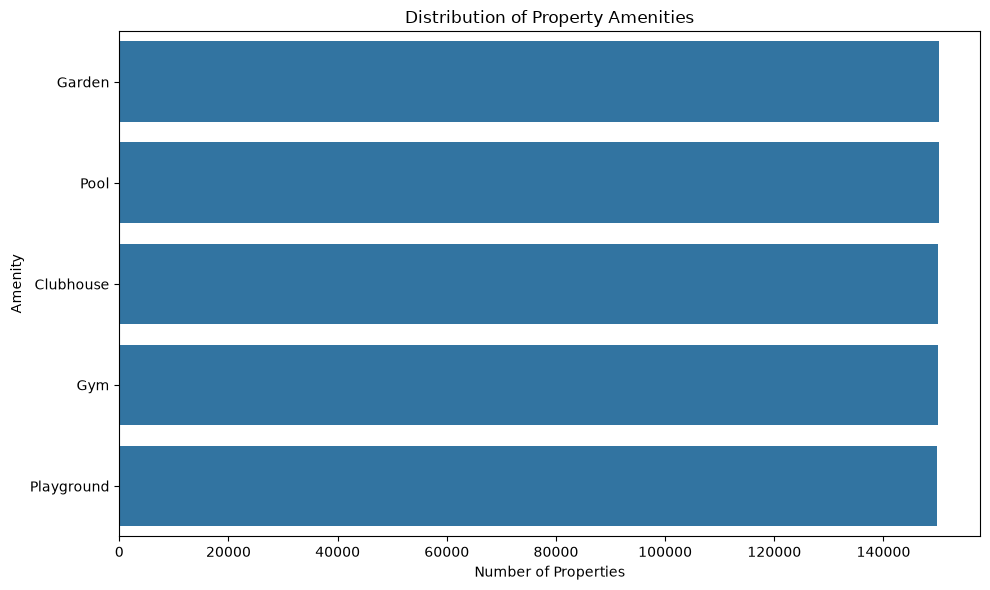

In [38]:
# ==========================================
# STEP 30: AMENITIES ANALYSIS
# ==========================================

amenity_list = [
    "Pool",
    "Clubhouse",
    "Garden",
    "Gym",
    "Playground"
]

# Create a separate amenity analysis dataframe
amenity_df = market_df.copy()

# Convert amenity combinations into binary columns
for amenity in amenity_list:
    amenity_df[f"Has_{amenity}"] = (
        amenity_df["Amenities"]
        .str.split(",")
        .apply(
            lambda items: amenity in [
                item.strip() for item in items
            ]
        )
    )

# Calculate amenity frequency
amenity_results = []

for amenity in amenity_list:

    column = f"Has_{amenity}"

    count = amenity_df[column].sum()

    percentage = (
        count / len(amenity_df) * 100
    )

    amenity_results.append({
        "Amenity": amenity,
        "Property_Count": count,
        "Property_Percentage": percentage
    })

amenity_summary = pd.DataFrame(
    amenity_results
).sort_values(
    by="Property_Count",
    ascending=False
)

print("AMENITIES DISTRIBUTION")

display(
    amenity_summary.style.format({
        "Property_Percentage": "{:.2f}%"
    })
)

# Visualize amenity distribution
plt.figure(figsize=(10, 6))

sns.barplot(
    data=amenity_summary,
    x="Property_Count",
    y="Amenity"
)

plt.title("Distribution of Property Amenities")
plt.xlabel("Number of Properties")
plt.ylabel("Amenity")

plt.tight_layout()
plt.show()

NUMBER OF AMENITIES PER PROPERTY


,Property_Count,Percentage
Total_Amenities,,
1,50106,20.04%
2,49806,19.92%
3,49862,19.94%
4,50362,20.14%
5,49864,19.95%



Summary Statistics
Average amenities: 3.0
Minimum amenities: 1
Maximum amenities: 5


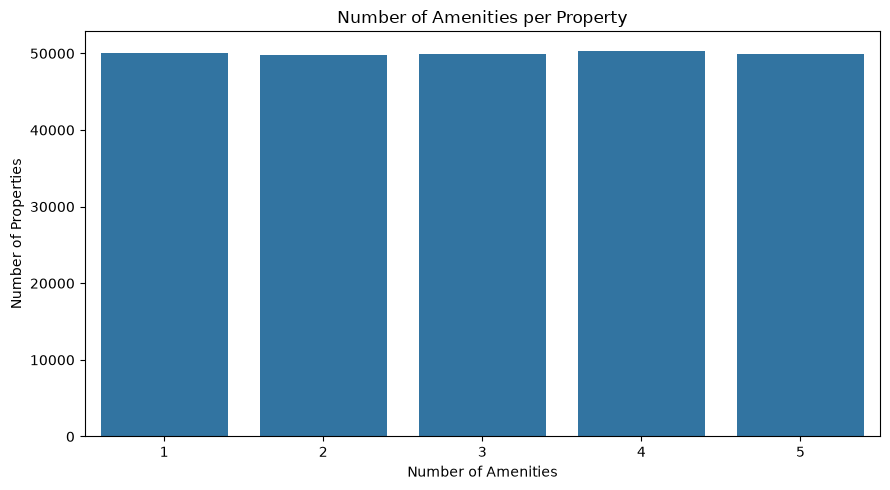

In [39]:
# ==========================================
# STEP 31: NUMBER OF AMENITIES PER PROPERTY
# ==========================================

# Count amenities present in each property
amenity_columns = [
    f"Has_{amenity}" for amenity in amenity_list
]

amenity_df["Total_Amenities"] = (
    amenity_df[amenity_columns].sum(axis=1)
)

# Frequency distribution
amenity_count_summary = (
    amenity_df["Total_Amenities"]
    .value_counts()
    .sort_index()
    .to_frame("Property_Count")
)

amenity_count_summary["Percentage"] = (
    amenity_count_summary["Property_Count"]
    / len(amenity_df) * 100
)

print("NUMBER OF AMENITIES PER PROPERTY")

display(
    amenity_count_summary.style.format({
        "Percentage": "{:.2f}%"
    })
)

# Summary statistics
print("\nSummary Statistics")

print(
    "Average amenities:",
    round(amenity_df["Total_Amenities"].mean(), 2)
)

print(
    "Minimum amenities:",
    amenity_df["Total_Amenities"].min()
)

print(
    "Maximum amenities:",
    amenity_df["Total_Amenities"].max()
)

# Visualization
plt.figure(figsize=(9, 5))

sns.barplot(
    x=amenity_count_summary.index,
    y=amenity_count_summary["Property_Count"]
)

plt.title("Number of Amenities per Property")
plt.xlabel("Number of Amenities")
plt.ylabel("Number of Properties")

plt.tight_layout()
plt.show()

AMENITY COMBINATION ANALYSIS
Original unique amenity strings: 325
Normalized unique combinations: 31


,Amenity_Combination,Property_Count,Percentage
0,"('Clubhouse', 'Garden', 'Gym', 'Playground', 'Pool')",49864,19.946%
1,"('Clubhouse', 'Garden', 'Gym', 'Pool')",10349,4.140%
2,"('Pool',)",10218,4.087%
3,"('Garden', 'Gym', 'Playground', 'Pool')",10083,4.033%
4,"('Clubhouse', 'Garden', 'Gym', 'Playground')",10016,4.006%
5,"('Clubhouse',)",10010,4.004%
6,"('Garden',)",10006,4.002%
7,"('Clubhouse', 'Garden', 'Playground', 'Pool')",9996,3.998%
8,"('Gym',)",9938,3.975%
9,"('Playground',)",9934,3.974%


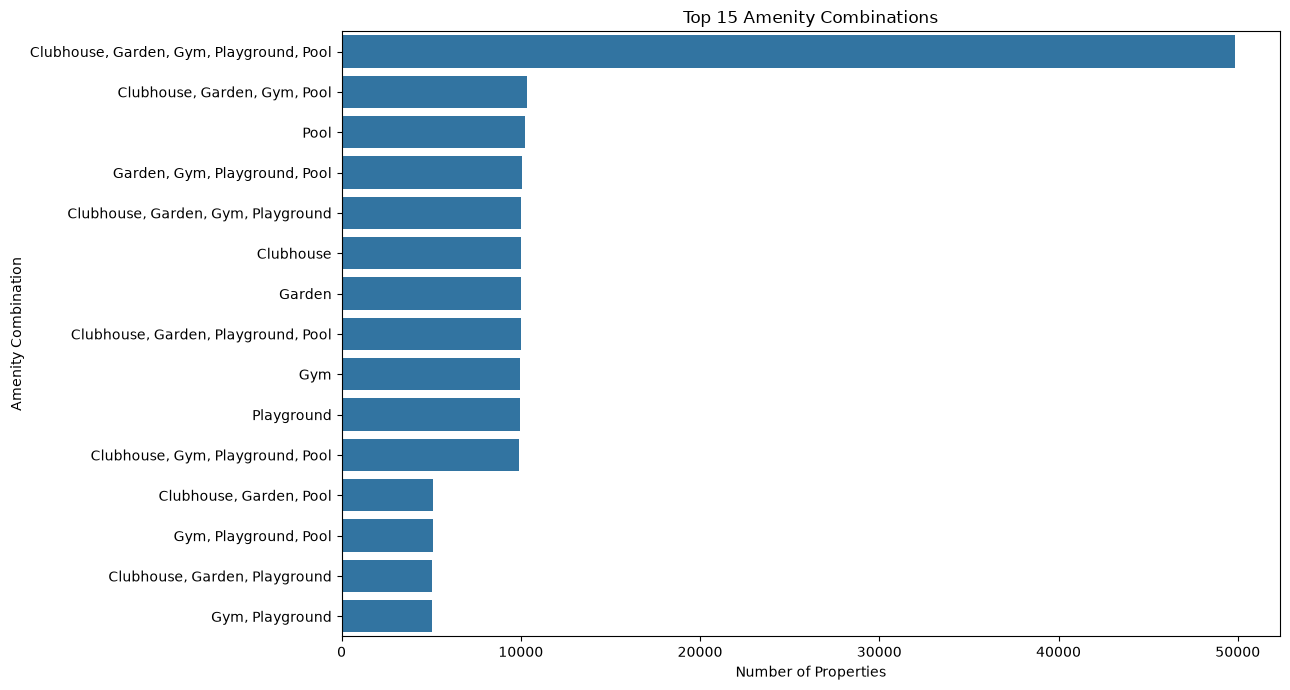

In [40]:
# ==========================================
# STEP 32: AMENITY COMBINATION ANALYSIS
# ==========================================

# Normalize amenity combinations:
# Sort amenity names so different orders become identical.

amenity_df["Normalized_Amenities"] = (
    amenity_df["Amenities"]
    .str.split(",")
    .apply(
        lambda items: tuple(
            sorted(item.strip() for item in items)
        )
    )
)

# Count normalized combinations
combination_summary = (
    amenity_df["Normalized_Amenities"]
    .value_counts()
    .rename_axis("Amenity_Combination")
    .reset_index(name="Property_Count")
)

combination_summary["Percentage"] = (
    combination_summary["Property_Count"]
    / len(amenity_df) * 100
)

print("AMENITY COMBINATION ANALYSIS")

print(
    "Original unique amenity strings:",
    market_df["Amenities"].nunique()
)

print(
    "Normalized unique combinations:",
    amenity_df["Normalized_Amenities"].nunique()
)

# Display top 20 combinations
display(
    combination_summary.head(20).style.format({
        "Percentage": "{:.3f}%"
    })
)

# Visualize top 15 combinations
top_combinations = combination_summary.head(15).copy()

top_combinations["Combination"] = (
    top_combinations["Amenity_Combination"]
    .apply(lambda items: ", ".join(items))
)

plt.figure(figsize=(13, 7))

sns.barplot(
    data=top_combinations,
    x="Property_Count",
    y="Combination"
)

plt.title("Top 15 Amenity Combinations")
plt.xlabel("Number of Properties")
plt.ylabel("Amenity Combination")

plt.tight_layout()
plt.show()

In [41]:
# ==========================================
# STEP 33: AMENITY COMBINATION VALIDATION
# ==========================================

# Number of amenities in each normalized combination
combination_summary["Number_of_Amenities"] = (
    combination_summary["Amenity_Combination"]
    .apply(len)
)

# Group by number of amenities
combination_validation = (
    combination_summary.groupby("Number_of_Amenities")
    .agg(
        Number_of_Combinations=("Amenity_Combination", "count"),
        Total_Properties=("Property_Count", "sum"),
        Average_Properties_Per_Combination=("Property_Count", "mean"),
        Minimum_Properties=("Property_Count", "min"),
        Maximum_Properties=("Property_Count", "max")
    )
)

combination_validation["Property_Percentage"] = (
    combination_validation["Total_Properties"]
    / len(amenity_df) * 100
)

print("AMENITY COMBINATION VALIDATION")

display(
    combination_validation.style.format({
        "Average_Properties_Per_Combination": "{:,.2f}",
        "Property_Percentage": "{:.2f}%"
    })
)

# Verify total records
print("\nTotal properties represented:",
      combination_validation["Total_Properties"].sum())

print("Original property records:", len(amenity_df))

print("\nTotal normalized combinations:",
      combination_summary.shape[0])

AMENITY COMBINATION VALIDATION


,Number_of_Combinations,Total_Properties,Average_Properties_Per_Combination,Minimum_Properties,Maximum_Properties,Property_Percentage
Number_of_Amenities,,,,,,
1,5,50106,"10,021.20",9934,10218,20.04%
2,10,49806,"4,980.60",4906,5043,19.92%
3,10,49862,"4,986.20",4898,5099,19.94%
4,5,50362,"10,072.40",9918,10349,20.14%
5,1,49864,"49,864.00",49864,49864,19.95%



Total properties represented: 250000
Original property records: 250000

Total normalized combinations: 31


PUBLIC TRANSPORT ACCESSIBILITY ANALYSIS


,Total_Properties,Average_Price,Median_Price,Average_Size,Average_BHK,Property_Share_Percent
Public_Transport_Accessibility,,,,,,
High,83705,254.92,254.71,2755.27,3.00,33.48%
Low,83287,254.86,254.27,2750.04,3.00,33.31%
Medium,83008,253.97,252.73,2744.08,3.00,33.20%


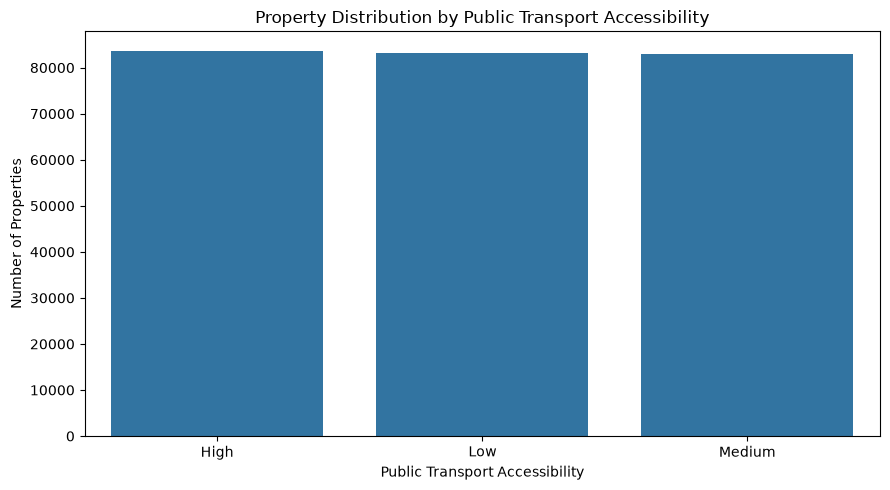

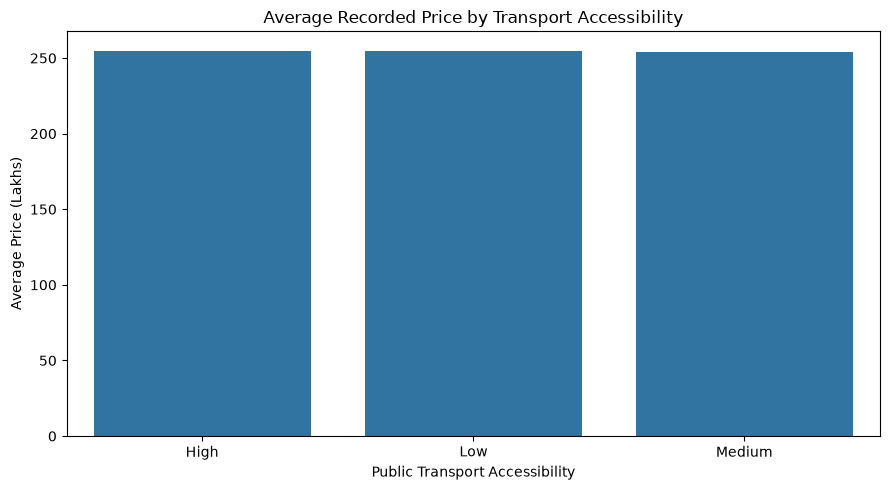

In [42]:
# ==========================================
# STEP 34: PUBLIC TRANSPORT ACCESSIBILITY
# ==========================================

transport_summary = (
    market_df.groupby("Public_Transport_Accessibility")
    .agg(
        Total_Properties=("ID", "count"),
        Average_Price=("Price_in_Lakhs", "mean"),
        Median_Price=("Price_in_Lakhs", "median"),
        Average_Size=("Size_in_SqFt", "mean"),
        Average_BHK=("BHK", "mean")
    )
    .sort_values(
        by="Total_Properties",
        ascending=False
    )
)

transport_summary["Property_Share_Percent"] = (
    transport_summary["Total_Properties"]
    / len(market_df) * 100
)

print("PUBLIC TRANSPORT ACCESSIBILITY ANALYSIS")

display(
    transport_summary.style.format({
        "Average_Price": "{:.2f}",
        "Median_Price": "{:.2f}",
        "Average_Size": "{:.2f}",
        "Average_BHK": "{:.2f}",
        "Property_Share_Percent": "{:.2f}%"
    })
)

# Property distribution
plt.figure(figsize=(9, 5))

sns.barplot(
    data=transport_summary.reset_index(),
    x="Public_Transport_Accessibility",
    y="Total_Properties"
)

plt.title("Property Distribution by Public Transport Accessibility")
plt.xlabel("Public Transport Accessibility")
plt.ylabel("Number of Properties")

plt.tight_layout()
plt.show()

# Average recorded price
plt.figure(figsize=(9, 5))

sns.barplot(
    data=transport_summary.reset_index(),
    x="Public_Transport_Accessibility",
    y="Average_Price"
)

plt.title("Average Recorded Price by Transport Accessibility")
plt.xlabel("Public Transport Accessibility")
plt.ylabel("Average Price (Lakhs)")

plt.tight_layout()
plt.show()

PARKING SPACE ANALYSIS


,Total_Properties,Average_Price,Median_Price,Average_Size,Average_BHK,Property_Share_Percent
Parking_Space,,,,,,
No,125456,254.43,253.37,2748.68,3.00,50.18%
Yes,124544,254.75,254.36,2750.95,3.00,49.82%


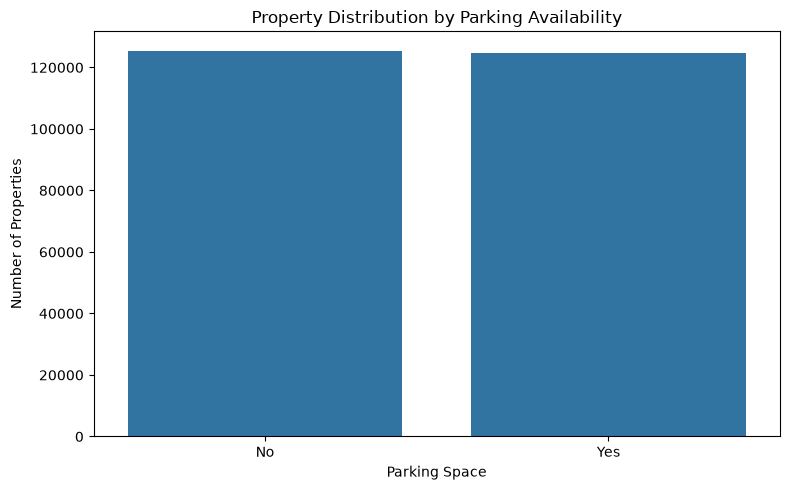

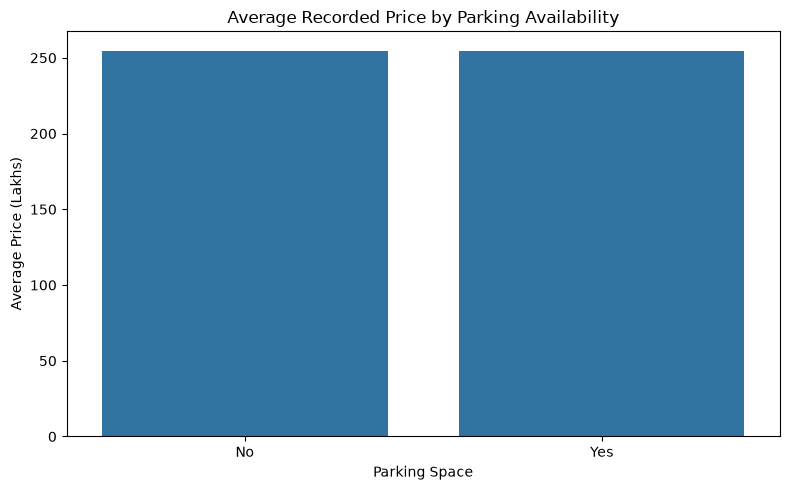

In [43]:
# ==========================================
# STEP 35: PARKING SPACE ANALYSIS
# ==========================================

parking_summary = (
    market_df.groupby("Parking_Space")
    .agg(
        Total_Properties=("ID", "count"),
        Average_Price=("Price_in_Lakhs", "mean"),
        Median_Price=("Price_in_Lakhs", "median"),
        Average_Size=("Size_in_SqFt", "mean"),
        Average_BHK=("BHK", "mean")
    )
    .sort_values(
        by="Total_Properties",
        ascending=False
    )
)

parking_summary["Property_Share_Percent"] = (
    parking_summary["Total_Properties"]
    / len(market_df) * 100
)

print("PARKING SPACE ANALYSIS")

display(
    parking_summary.style.format({
        "Average_Price": "{:.2f}",
        "Median_Price": "{:.2f}",
        "Average_Size": "{:.2f}",
        "Average_BHK": "{:.2f}",
        "Property_Share_Percent": "{:.2f}%"
    })
)

# Property count visualization
plt.figure(figsize=(8, 5))

sns.barplot(
    data=parking_summary.reset_index(),
    x="Parking_Space",
    y="Total_Properties"
)

plt.title("Property Distribution by Parking Availability")
plt.xlabel("Parking Space")
plt.ylabel("Number of Properties")

plt.tight_layout()
plt.show()

# Average price visualization
plt.figure(figsize=(8, 5))

sns.barplot(
    data=parking_summary.reset_index(),
    x="Parking_Space",
    y="Average_Price"
)

plt.title("Average Recorded Price by Parking Availability")
plt.xlabel("Parking Space")
plt.ylabel("Average Price (Lakhs)")

plt.tight_layout()
plt.show()

SECURITY AVAILABILITY ANALYSIS


,Total_Properties,Average_Price,Median_Price,Average_Size,Average_BHK,Property_Share_Percent
Security,,,,,,
Yes,125233,255.12,254.52,2750.87,3.00,50.09%
No,124767,254.05,253.27,2748.75,3.00,49.91%


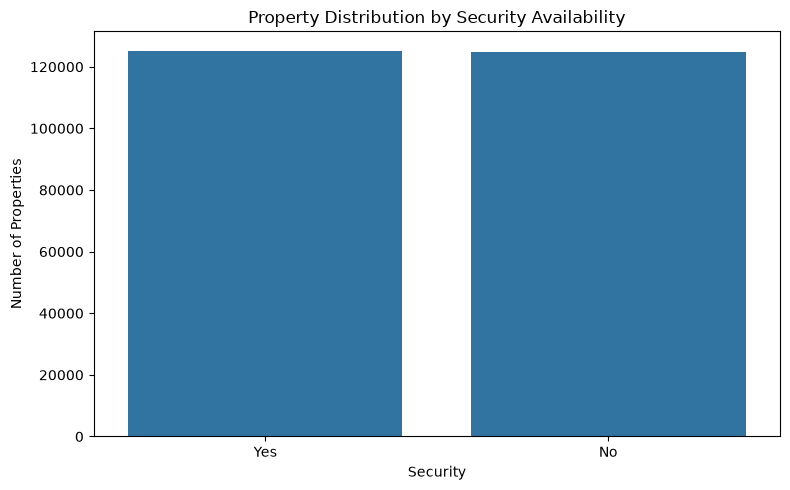

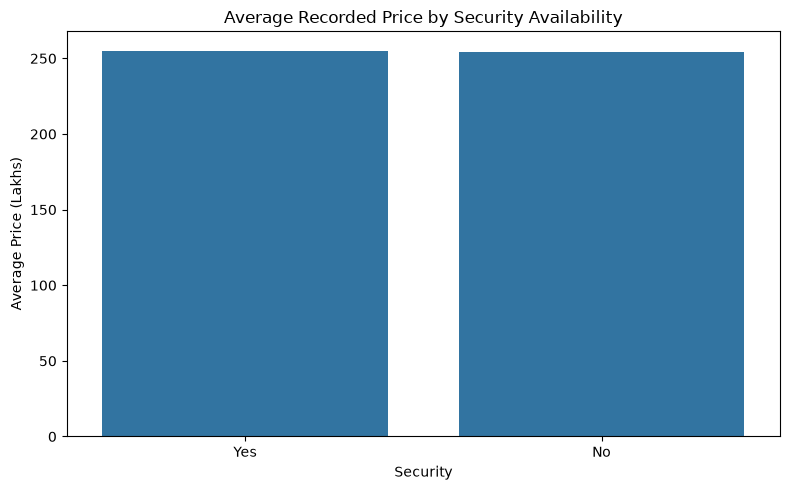

In [44]:
# ==========================================
# STEP 36: SECURITY AVAILABILITY ANALYSIS
# ==========================================

security_summary = (
    market_df.groupby("Security")
    .agg(
        Total_Properties=("ID", "count"),
        Average_Price=("Price_in_Lakhs", "mean"),
        Median_Price=("Price_in_Lakhs", "median"),
        Average_Size=("Size_in_SqFt", "mean"),
        Average_BHK=("BHK", "mean")
    )
    .sort_values(
        by="Total_Properties",
        ascending=False
    )
)

security_summary["Property_Share_Percent"] = (
    security_summary["Total_Properties"]
    / len(market_df) * 100
)

print("SECURITY AVAILABILITY ANALYSIS")

display(
    security_summary.style.format({
        "Average_Price": "{:.2f}",
        "Median_Price": "{:.2f}",
        "Average_Size": "{:.2f}",
        "Average_BHK": "{:.2f}",
        "Property_Share_Percent": "{:.2f}%"
    })
)

# Property count visualization
plt.figure(figsize=(8, 5))

sns.barplot(
    data=security_summary.reset_index(),
    x="Security",
    y="Total_Properties"
)

plt.title("Property Distribution by Security Availability")
plt.xlabel("Security")
plt.ylabel("Number of Properties")

plt.tight_layout()
plt.show()

# Average price visualization
plt.figure(figsize=(8, 5))

sns.barplot(
    data=security_summary.reset_index(),
    x="Security",
    y="Average_Price"
)

plt.title("Average Recorded Price by Security Availability")
plt.xlabel("Security")
plt.ylabel("Average Price (Lakhs)")

plt.tight_layout()
plt.show()

PROPERTY FACING ANALYSIS


,Total_Properties,Average_Price,Median_Price,Average_Size,Average_BHK,Property_Share_Percent
Facing,,,,,,
West,62757,255.04,255.03,2742.80,3.00,25.10%
North,62637,254.73,253.86,2753.88,3.00,25.05%
South,62337,254.08,253.18,2750.56,3.00,24.93%
East,62269,254.49,253.50,2752.04,3.00,24.91%


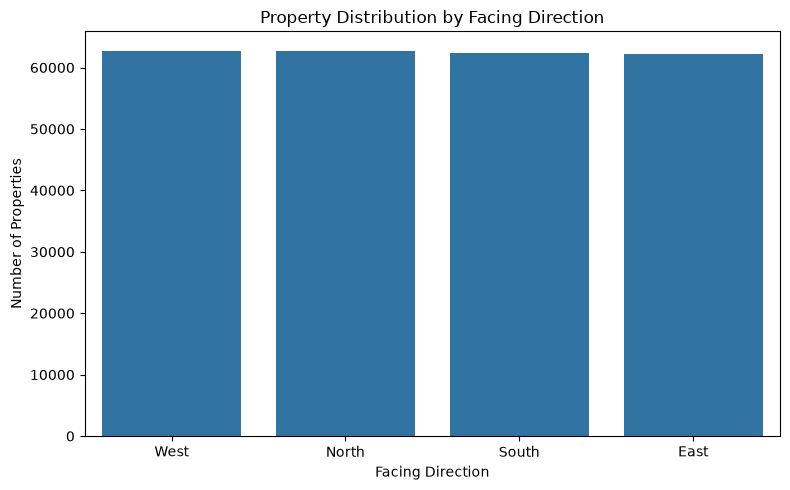

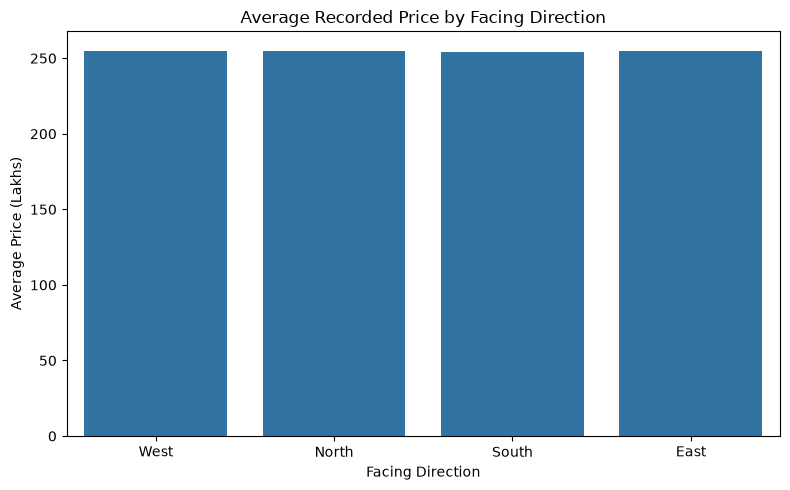

In [45]:
# ==========================================
# STEP 37: PROPERTY FACING ANALYSIS
# ==========================================

facing_summary = (
    market_df.groupby("Facing")
    .agg(
        Total_Properties=("ID", "count"),
        Average_Price=("Price_in_Lakhs", "mean"),
        Median_Price=("Price_in_Lakhs", "median"),
        Average_Size=("Size_in_SqFt", "mean"),
        Average_BHK=("BHK", "mean")
    )
    .sort_values(
        by="Total_Properties",
        ascending=False
    )
)

facing_summary["Property_Share_Percent"] = (
    facing_summary["Total_Properties"]
    / len(market_df) * 100
)

print("PROPERTY FACING ANALYSIS")

display(
    facing_summary.style.format({
        "Average_Price": "{:.2f}",
        "Median_Price": "{:.2f}",
        "Average_Size": "{:.2f}",
        "Average_BHK": "{:.2f}",
        "Property_Share_Percent": "{:.2f}%"
    })
)

# Property count visualization
plt.figure(figsize=(8, 5))

sns.barplot(
    data=facing_summary.reset_index(),
    x="Facing",
    y="Total_Properties"
)

plt.title("Property Distribution by Facing Direction")
plt.xlabel("Facing Direction")
plt.ylabel("Number of Properties")

plt.tight_layout()
plt.show()

# Average price visualization
plt.figure(figsize=(8, 5))

sns.barplot(
    data=facing_summary.reset_index(),
    x="Facing",
    y="Average_Price"
)

plt.title("Average Recorded Price by Facing Direction")
plt.xlabel("Facing Direction")
plt.ylabel("Average Price (Lakhs)")

plt.tight_layout()
plt.show()

PROPERTY OWNER TYPE ANALYSIS


,Total_Properties,Average_Price,Median_Price,Average_Size,Average_BHK,Property_Share_Percent
Owner_Type,,,,,,
Broker,83479,254.91,254.90,2749.88,2.99,33.39%
Owner,83268,254.25,253.00,2745.00,3.00,33.31%
Builder,83253,254.59,253.67,2754.56,3.00,33.30%


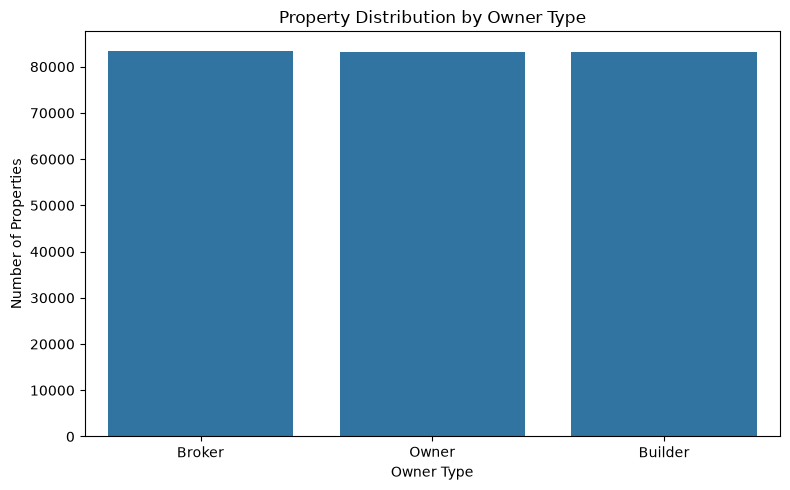

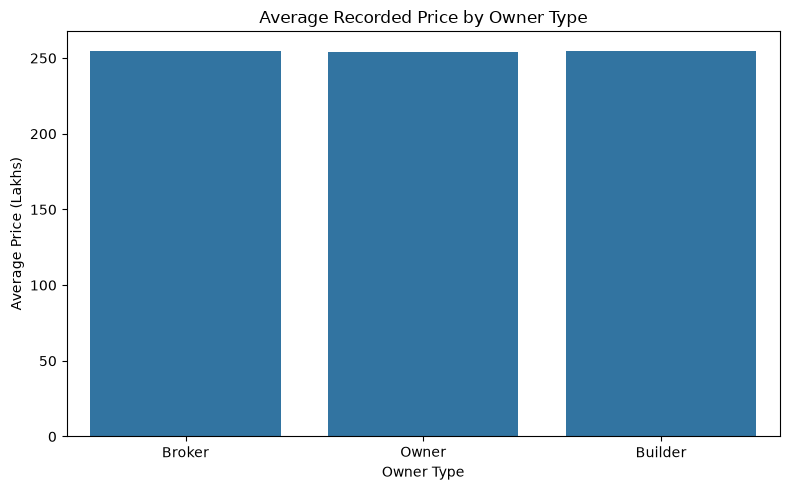

In [46]:
# ==========================================
# STEP 38: OWNER TYPE ANALYSIS
# ==========================================

owner_summary = (
    market_df.groupby("Owner_Type")
    .agg(
        Total_Properties=("ID", "count"),
        Average_Price=("Price_in_Lakhs", "mean"),
        Median_Price=("Price_in_Lakhs", "median"),
        Average_Size=("Size_in_SqFt", "mean"),
        Average_BHK=("BHK", "mean")
    )
    .sort_values(
        by="Total_Properties",
        ascending=False
    )
)

owner_summary["Property_Share_Percent"] = (
    owner_summary["Total_Properties"]
    / len(market_df) * 100
)

print("PROPERTY OWNER TYPE ANALYSIS")

display(
    owner_summary.style.format({
        "Average_Price": "{:.2f}",
        "Median_Price": "{:.2f}",
        "Average_Size": "{:.2f}",
        "Average_BHK": "{:.2f}",
        "Property_Share_Percent": "{:.2f}%"
    })
)

# Property count visualization
plt.figure(figsize=(8, 5))

sns.barplot(
    data=owner_summary.reset_index(),
    x="Owner_Type",
    y="Total_Properties"
)

plt.title("Property Distribution by Owner Type")
plt.xlabel("Owner Type")
plt.ylabel("Number of Properties")

plt.tight_layout()
plt.show()

# Average price visualization
plt.figure(figsize=(8, 5))

sns.barplot(
    data=owner_summary.reset_index(),
    x="Owner_Type",
    y="Average_Price"
)

plt.title("Average Recorded Price by Owner Type")
plt.xlabel("Owner Type")
plt.ylabel("Average Price (Lakhs)")

plt.tight_layout()
plt.show()

PROPERTY CONSTRUCTION PERIOD ANALYSIS


,Total_Properties,Average_Price,Median_Price,Average_Size,Average_BHK,Property_Share_Percent
Construction_Period,,,,,,
1990–1994,36580,253.87,251.74,2737.47,2.99,14.63%
1995–1999,36698,254.26,254.57,2742.07,3.00,14.68%
2000–2004,36958,254.51,254.18,2754.20,3.00,14.78%
2005–2009,36726,254.33,253.62,2752.90,3.00,14.69%
2010–2014,36700,254.91,253.63,2754.27,3.00,14.68%
2015–2019,36772,254.71,253.22,2750.87,3.00,14.71%
2020–2024,29566,255.73,256.22,2758.54,3.00,11.83%


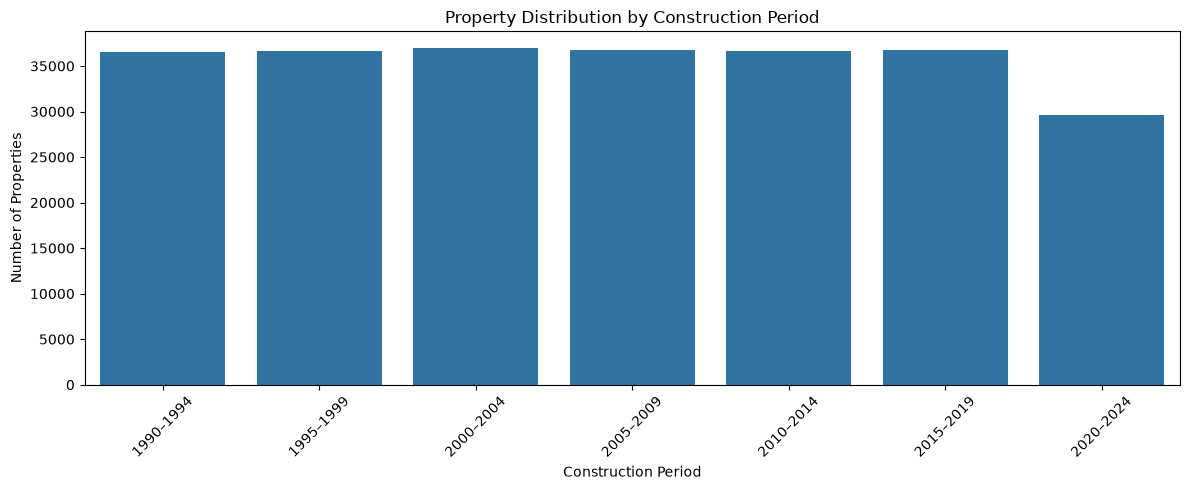

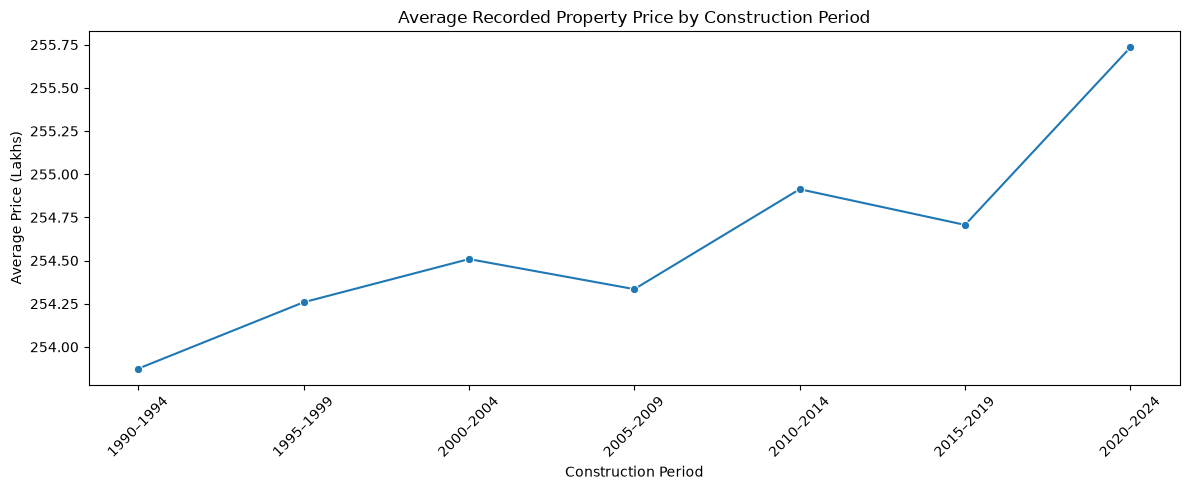

In [47]:
# ==========================================
# STEP 39: PROPERTY CONSTRUCTION YEAR ANALYSIS
# ==========================================

year_df = market_df.copy()

year_df["Construction_Period"] = (
    (year_df["Year_Built"] // 5) * 5
).astype(str) + "–" + (
    (year_df["Year_Built"] // 5) * 5 + 4
).astype(str)

year_summary = (
    year_df.groupby("Construction_Period", observed=True)
    .agg(
        Total_Properties=("ID", "count"),
        Average_Price=("Price_in_Lakhs", "mean"),
        Median_Price=("Price_in_Lakhs", "median"),
        Average_Size=("Size_in_SqFt", "mean"),
        Average_BHK=("BHK", "mean")
    )
)

year_summary["Property_Share_Percent"] = (
    year_summary["Total_Properties"] / len(year_df) * 100
)

print("PROPERTY CONSTRUCTION PERIOD ANALYSIS")

display(
    year_summary.style.format({
        "Average_Price": "{:.2f}",
        "Median_Price": "{:.2f}",
        "Average_Size": "{:.2f}",
        "Average_BHK": "{:.2f}",
        "Property_Share_Percent": "{:.2f}%"
    })
)

# Property count by construction period
plt.figure(figsize=(12, 5))

sns.barplot(
    data=year_summary.reset_index(),
    x="Construction_Period",
    y="Total_Properties"
)

plt.title("Property Distribution by Construction Period")
plt.xlabel("Construction Period")
plt.ylabel("Number of Properties")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Average price by construction period
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=year_summary.reset_index(),
    x="Construction_Period",
    y="Average_Price",
    marker="o"
)

plt.title("Average Recorded Property Price by Construction Period")
plt.xlabel("Construction Period")
plt.ylabel("Average Price (Lakhs)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [48]:
# ==========================================
# STEP 40: NUMERICAL FEATURE ASSOCIATION
# ==========================================

from scipy.stats import pearsonr, spearmanr

numerical_features = [
    "BHK",
    "Size_in_SqFt",
    "Year_Built",
    "Floor_No",
    "Total_Floors",
    "Age_of_Property",
    "Nearby_Schools",
    "Nearby_Hospitals"
]

target = "Price_in_Lakhs"

association_results = []

for feature in numerical_features:

    pearson_corr, pearson_p = pearsonr(
        market_df[feature],
        market_df[target]
    )

    spearman_corr, spearman_p = spearmanr(
        market_df[feature],
        market_df[target]
    )

    association_results.append({
        "Feature": feature,
        "Pearson_Correlation": pearson_corr,
        "Pearson_P_Value": pearson_p,
        "Spearman_Correlation": spearman_corr,
        "Spearman_P_Value": spearman_p
    })

association_df = pd.DataFrame(association_results)

association_df["Absolute_Pearson"] = (
    association_df["Pearson_Correlation"].abs()
)

association_df = association_df.sort_values(
    by="Absolute_Pearson",
    ascending=False
).drop(columns="Absolute_Pearson")

print("NUMERICAL FEATURE ASSOCIATION WITH PROPERTY PRICE")

display(
    association_df.style.format({
        "Pearson_Correlation": "{:.6f}",
        "Pearson_P_Value": "{:.6e}",
        "Spearman_Correlation": "{:.6f}",
        "Spearman_P_Value": "{:.6e}"
    })
)

NUMERICAL FEATURE ASSOCIATION WITH PROPERTY PRICE


,Feature,Pearson_Correlation,Pearson_P_Value,Spearman_Correlation,Spearman_P_Value
7,Nearby_Hospitals,-0.002769,1.661841e-01,-0.002771,1.658777e-01
5,Age_of_Property,-0.002714,1.748233e-01,-0.002723,1.732807e-01
2,Year_Built,0.002714,1.748233e-01,0.002723,1.732807e-01
1,Size_in_SqFt,-0.002529,2.061335e-01,-0.002529,2.060134e-01
3,Floor_No,-0.001719,3.901972e-01,-0.001732,3.863783e-01
4,Total_Floors,0.001283,5.210576e-01,0.001290,5.190631e-01
0,BHK,-0.000980,6.241374e-01,-0.000988,6.214043e-01
6,Nearby_Schools,0.000155,9.382637e-01,0.000149,9.404963e-01


In [49]:
# ==========================================
# STEP 41: FINAL FEATURE ELIGIBILITY AUDIT
# ==========================================

feature_audit = pd.DataFrame([
    {
        "Feature": "ID",
        "Decision": "Exclude",
        "Reason": "Unique record identifier; not a property characteristic."
    },
    {
        "Feature": "Price_in_Lakhs",
        "Decision": "Target",
        "Reason": "Target variable for current property price prediction."
    },
    {
        "Feature": "Price_per_SqFt",
        "Decision": "Exclude",
        "Reason": "Derived from the target price and property size; target leakage."
    },
    {
        "Feature": "Age_of_Property",
        "Decision": "Exclude",
        "Reason": "Redundant with Year_Built; both sum to 2025."
    },
    {
        "Feature": "Floor_No",
        "Decision": "Review / Exclude",
        "Reason": "46.52% of records have Floor_No greater than Total_Floors."
    },
    {
        "Feature": "Total_Floors",
        "Decision": "Review / Exclude",
        "Reason": "Floor information has substantial consistency concerns."
    },
    {
        "Feature": "Year_Built",
        "Decision": "Candidate",
        "Reason": "Valid construction-year field, but observed price association is negligible."
    },
    {
        "Feature": "BHK",
        "Decision": "Candidate",
        "Reason": "Property characteristic, but observed price association is negligible."
    },
    {
        "Feature": "Size_in_SqFt",
        "Decision": "Candidate",
        "Reason": "Property characteristic, but observed price association is negligible."
    }
])

display(feature_audit)

,Feature,Decision,Reason
0,ID,Exclude,Unique record identifier; not a property chara...
1,Price_in_Lakhs,Target,Target variable for current property price pre...
2,Price_per_SqFt,Exclude,Derived from the target price and property siz...
3,Age_of_Property,Exclude,Redundant with Year_Built; both sum to 2025.
4,Floor_No,Review / Exclude,46.52% of records have Floor_No greater than T...
5,Total_Floors,Review / Exclude,Floor information has substantial consistency ...
6,Year_Built,Candidate,"Valid construction-year field, but observed pr..."
7,BHK,Candidate,"Property characteristic, but observed price as..."
8,Size_in_SqFt,Candidate,"Property characteristic, but observed price as..."


In [50]:
# ==========================================
# STEP 42: COMPLETE FEATURE CLASSIFICATION
# ==========================================

complete_feature_audit = pd.DataFrame([
    ("ID", "Exclude", "Unique record identifier"),
    ("State", "Candidate", "Geographic categorical feature"),
    ("City", "Candidate", "Geographic categorical feature"),
    ("Locality", "Candidate", "Location identifier; synthetic-looking labels"),
    ("Property_Type", "Candidate", "Property category"),
    ("BHK", "Candidate", "Number of bedrooms"),
    ("Size_in_SqFt", "Candidate", "Property size"),
    ("Price_in_Lakhs", "Target", "Current recorded property price"),
    ("Price_per_SqFt", "Exclude", "Derived using target price; leakage"),
    ("Year_Built", "Candidate", "Construction year"),
    ("Furnished_Status", "Candidate", "Furnishing category"),
    ("Floor_No", "Exclude initially", "46.52% floor consistency violations"),
    ("Total_Floors", "Exclude initially", "Floor data reliability concerns"),
    ("Age_of_Property", "Exclude", "Redundant with Year_Built"),
    ("Nearby_Schools", "Candidate", "Nearby school count"),
    ("Nearby_Hospitals", "Candidate", "Nearby hospital count"),
    ("Public_Transport_Accessibility", "Candidate", "Accessibility category"),
    ("Parking_Space", "Candidate", "Parking availability"),
    ("Security", "Candidate", "Security availability"),
    ("Amenities", "Candidate", "Amenity combinations; requires encoding"),
    ("Facing", "Candidate", "Property facing direction"),
    ("Owner_Type", "Candidate", "Listing owner category"),
    ("Availability_Status", "Candidate", "Property availability category")
], columns=["Feature", "Decision", "Reason"])

print("COMPLETE FEATURE CLASSIFICATION")
print("Total dataset columns:", len(market_df.columns))
print("Audited features:", len(complete_feature_audit))

display(complete_feature_audit)

COMPLETE FEATURE CLASSIFICATION
Total dataset columns: 23
Audited features: 23


,Feature,Decision,Reason
0,ID,Exclude,Unique record identifier
1,State,Candidate,Geographic categorical feature
2,City,Candidate,Geographic categorical feature
3,Locality,Candidate,Location identifier; synthetic-looking labels
4,Property_Type,Candidate,Property category
5,BHK,Candidate,Number of bedrooms
6,Size_in_SqFt,Candidate,Property size
7,Price_in_Lakhs,Target,Current recorded property price
8,Price_per_SqFt,Exclude,Derived using target price; leakage
9,Year_Built,Candidate,Construction year


In [51]:
# ==========================================
# STEP 43: CREATE INITIAL MODELING DATASET
# ==========================================

# Candidate features from the complete audit
candidate_features = complete_feature_audit.loc[
    complete_feature_audit["Decision"] == "Candidate",
    "Feature"
].tolist()

target_column = "Price_in_Lakhs"

# Create separate feature and target datasets
X = market_df[candidate_features].copy()
y = market_df[target_column].copy()

# Identify numerical and categorical features
numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("=" * 55)
print("INITIAL MODELING DATASET")
print("=" * 55)

print("\nFeature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nNumerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

print("\nTotal candidate features:", len(candidate_features))

print("\nMissing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())

print("\nTarget statistics:")
display(y.describe().to_frame("Price_in_Lakhs"))

print("\nFeature preview:")
display(X.head())

# Confirm original dataset is unchanged
print("\nOriginal dataset shape:", df.shape)
print("Market dataset shape:", market_df.shape)

INITIAL MODELING DATASET

Feature matrix shape: (250000, 17)
Target vector shape: (250000,)

Numerical features:
['BHK', 'Size_in_SqFt', 'Year_Built', 'Nearby_Schools', 'Nearby_Hospitals']

Categorical features:
['State', 'City', 'Locality', 'Property_Type', 'Furnished_Status', 'Public_Transport_Accessibility', 'Parking_Space', 'Security', 'Amenities', 'Facing', 'Owner_Type', 'Availability_Status']

Total candidate features: 17

Missing values in X: 0
Missing values in y: 0

Target statistics:


,Price_in_Lakhs
count,250000.00
mean,254.59
std,141.35
min,10.00
25%,132.55
50%,253.87
75%,376.88
max,500.00



Feature preview:


,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Year_Built,Furnished_Status,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,1990,Furnished,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,Maharashtra,Pune,Locality_490,Independent House,3,2364,2008,Unfurnished,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,Punjab,Ludhiana,Locality_167,Apartment,2,3642,1997,Semi-furnished,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,1991,Furnished,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,Rajasthan,Jaipur,Locality_466,Villa,4,4823,2002,Semi-furnished,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move



Original dataset shape: (250000, 23)
Market dataset shape: (250000, 23)


In [52]:
# ==========================================
# STEP 44: TRAIN-TEST SPLIT
# ==========================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

print("=" * 55)
print("TRAIN-TEST SPLIT SUMMARY")
print("=" * 55)

print("\nOriginal feature dataset:", X.shape)
print("Training feature dataset:", X_train.shape)
print("Testing feature dataset:", X_test.shape)

print("\nOriginal target dataset:", y.shape)
print("Training target dataset:", y_train.shape)
print("Testing target dataset:", y_test.shape)

print("\nTraining target statistics:")
display(y_train.describe().to_frame("Training_Price"))

print("\nTesting target statistics:")
display(y_test.describe().to_frame("Testing_Price"))

# Verify there are no missing values
print("\nMissing values in training features:",
      X_train.isnull().sum().sum())

print("Missing values in testing features:",
      X_test.isnull().sum().sum())

# Verify record counts
print("\nTotal records after split:",
      len(X_train) + len(X_test))

TRAIN-TEST SPLIT SUMMARY

Original feature dataset: (250000, 17)
Training feature dataset: (200000, 17)
Testing feature dataset: (50000, 17)

Original target dataset: (250000,)
Training target dataset: (200000,)
Testing target dataset: (50000,)

Training target statistics:


,Training_Price
count,200000.00
mean,254.55
std,141.39
min,10.00
25%,132.46
50%,254.14
75%,376.76
max,500.00



Testing target statistics:


,Testing_Price
count,50000.00
mean,254.71
std,141.19
min,10.02
25%,132.92
50%,252.82
75%,377.40
max,499.96



Missing values in training features: 0
Missing values in testing features: 0

Total records after split: 250000


In [53]:
# ==========================================
# STEP 45: BUILD PREPROCESSING PIPELINE
# ==========================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Numerical preprocessing
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using training-fitted preprocessing
X_test_processed = preprocessor.transform(X_test)

print("=" * 55)
print("PREPROCESSING PIPELINE SUMMARY")
print("=" * 55)

print("\nOriginal training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOriginal testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

print("\nTraining matrix type:", type(X_train_processed))
print("Testing matrix type:", type(X_test_processed))

print("\nTraining matrix contains NaN:",
      np.isnan(X_train_processed.data).any()
      if hasattr(X_train_processed, "data")
      else np.isnan(X_train_processed).any())

print("Testing matrix contains NaN:",
      np.isnan(X_test_processed.data).any()
      if hasattr(X_test_processed, "data")
      else np.isnan(X_test_processed).any())

PREPROCESSING PIPELINE SUMMARY

Original training shape: (200000, 17)
Processed training shape: (200000, 914)

Original testing shape: (50000, 17)
Processed testing shape: (50000, 914)

Training matrix type: <class 'scipy.sparse._csr.csr_matrix'>
Testing matrix type: <class 'scipy.sparse._csr.csr_matrix'>

Training matrix contains NaN: False
Testing matrix contains NaN: False


In [54]:
# ==========================================
# STEP 46: BASELINE AND RIDGE REGRESSION
# ==========================================

import time

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []

models = {
    "Dummy Baseline": DummyRegressor(strategy="mean"),
    "Ridge Regression": Ridge(
        alpha=10.0,
        solver="lsqr"
    )
}

for model_name, model in models.items():

    start_time = time.time()

    # Train model
    model.fit(X_train_processed, y_train)

    # Predict test data
    predictions = model.predict(X_test_processed)

    # Evaluate
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    training_time = time.time() - start_time

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Time_Seconds": training_time
    })

results_df = pd.DataFrame(results)

print("=" * 65)
print("BASELINE VS RIDGE REGRESSION")
print("=" * 65)

display(
    results_df.style.format({
        "MAE": "{:.4f}",
        "RMSE": "{:.4f}",
        "R2": "{:.6f}",
        "Time_Seconds": "{:.2f}"
    })
)

BASELINE VS RIDGE REGRESSION


,Model,MAE,RMSE,R2,Time_Seconds
0,Dummy Baseline,122.3178,141.1932,-0.000001,0.02
1,Ridge Regression,122.4317,141.4522,-0.003672,0.62


In [55]:
# ==========================================
# STEP 47: CATEGORICAL FEATURE ASSOCIATION
# ==========================================

categorical_associations = []

for feature in categorical_features:

    grouped = market_df.groupby(feature)["Price_in_Lakhs"]

    overall_mean = market_df["Price_in_Lakhs"].mean()

    # Between-group sum of squares
    ss_between = sum(
        len(group) * (group.mean() - overall_mean) ** 2
        for _, group in grouped
    )

    # Total sum of squares
    ss_total = (
        (market_df["Price_in_Lakhs"] - overall_mean) ** 2
    ).sum()

    eta_squared = ss_between / ss_total

    categorical_associations.append({
        "Feature": feature,
        "Unique_Categories": market_df[feature].nunique(),
        "Eta_Squared": eta_squared,
        "Explained_Variance_Percent": eta_squared * 100
    })

categorical_association_df = (
    pd.DataFrame(categorical_associations)
    .sort_values(
        by="Eta_Squared",
        ascending=False
    )
)

print("=" * 65)
print("CATEGORICAL FEATURE ASSOCIATION WITH PROPERTY PRICE")
print("=" * 65)

display(
    categorical_association_df.style.format({
        "Eta_Squared": "{:.6f}",
        "Explained_Variance_Percent": "{:.4f}%"
    })
)

CATEGORICAL FEATURE ASSOCIATION WITH PROPERTY PRICE


,Feature,Unique_Categories,Eta_Squared,Explained_Variance_Percent
2,Locality,500,0.002041,0.2041%
8,Amenities,325,0.001101,0.1101%
1,City,42,0.000190,0.0190%
0,State,20,0.000097,0.0097%
3,Property_Type,3,0.000022,0.0022%
7,Security,2,0.000015,0.0015%
5,Public_Transport_Accessibility,3,0.000009,0.0009%
11,Availability_Status,2,0.000008,0.0008%
9,Facing,4,0.000006,0.0006%
4,Furnished_Status,3,0.000004,0.0004%


In [56]:
# ==========================================
# STEP 48: REGRESSION FEASIBILITY ASSESSMENT
# ==========================================

regression_assessment = {
    "Dataset_Records": len(market_df),
    "Candidate_Features": len(candidate_features),
    "Encoded_Features": X_train_processed.shape[1],
    "Baseline_MAE": results_df.loc[
        results_df["Model"] == "Dummy Baseline", "MAE"
    ].iloc[0],
    "Ridge_MAE": results_df.loc[
        results_df["Model"] == "Ridge Regression", "MAE"
    ].iloc[0],
    "Baseline_RMSE": results_df.loc[
        results_df["Model"] == "Dummy Baseline", "RMSE"
    ].iloc[0],
    "Ridge_RMSE": results_df.loc[
        results_df["Model"] == "Ridge Regression", "RMSE"
    ].iloc[0],
    "Ridge_R2": results_df.loc[
        results_df["Model"] == "Ridge Regression", "R2"
    ].iloc[0],
    "Strongest_Categorical_Feature": (
        categorical_association_df.iloc[0]["Feature"]
    ),
    "Strongest_Categorical_Explained_Variance_Percent": (
        categorical_association_df.iloc[0][
            "Explained_Variance_Percent"
        ]
    )
}

print("=" * 60)
print("REGRESSION FEASIBILITY ASSESSMENT")
print("=" * 60)

for key, value in regression_assessment.items():
    print(f"{key}: {value}")

print("\nCONCLUSION:")
print(
    "Current-price regression is not sufficiently supported "
    "by the available dataset features."
)

REGRESSION FEASIBILITY ASSESSMENT
Dataset_Records: 250000
Candidate_Features: 17
Encoded_Features: 914
Baseline_MAE: 122.31777643721
Ridge_MAE: 122.4316918616389
Baseline_RMSE: 141.19324006155858
Ridge_RMSE: 141.45216015954662
Ridge_R2: -0.0036722457798621377
Strongest_Categorical_Feature: Locality
Strongest_Categorical_Explained_Variance_Percent: 0.20409506510366063

CONCLUSION:
Current-price regression is not sufficiently supported by the available dataset features.


In [57]:
# ==========================================
# STEP 49: INVESTMENT CLASSIFICATION FEASIBILITY
# ==========================================

investment_requirements = {
    "Current property price": "Price_in_Lakhs",
    "Rental income": "Rental_Income",
    "Monthly rent": "Monthly_Rent",
    "Property maintenance expenses": "Maintenance_Cost",
    "Property taxes": "Property_Tax",
    "Other investment expenses": "Other_Expenses",
    "Historical property price": "Historical_Price",
    "Future property value": "Future_Price",
    "Investment holding period": "Holding_Period",
    "Actual investment return": "Investment_Return"
}

available_columns = set(market_df.columns)

investment_audit = []

for requirement, column in investment_requirements.items():

    available = column in available_columns

    investment_audit.append({
        "Investment_Requirement": requirement,
        "Expected_Column": column,
        "Available": available
    })

investment_audit_df = pd.DataFrame(investment_audit)

print("=" * 65)
print("INVESTMENT CLASSIFICATION FEASIBILITY AUDIT")
print("=" * 65)

display(investment_audit_df)

available_count = investment_audit_df["Available"].sum()
missing_count = len(investment_audit_df) - available_count

print("\nAvailable investment variables:", available_count)
print("Missing investment variables:", missing_count)

print("\nDataset columns:")
print(market_df.columns.tolist())

INVESTMENT CLASSIFICATION FEASIBILITY AUDIT


,Investment_Requirement,Expected_Column,Available
0,Current property price,Price_in_Lakhs,True
1,Rental income,Rental_Income,False
2,Monthly rent,Monthly_Rent,False
3,Property maintenance expenses,Maintenance_Cost,False
4,Property taxes,Property_Tax,False
5,Other investment expenses,Other_Expenses,False
6,Historical property price,Historical_Price,False
7,Future property value,Future_Price,False
8,Investment holding period,Holding_Period,False
9,Actual investment return,Investment_Return,False



Available investment variables: 1
Missing investment variables: 9

Dataset columns:
['ID', 'State', 'City', 'Locality', 'Property_Type', 'BHK', 'Size_in_SqFt', 'Price_in_Lakhs', 'Price_per_SqFt', 'Year_Built', 'Furnished_Status', 'Floor_No', 'Total_Floors', 'Age_of_Property', 'Nearby_Schools', 'Nearby_Hospitals', 'Public_Transport_Accessibility', 'Parking_Space', 'Security', 'Amenities', 'Facing', 'Owner_Type', 'Availability_Status']


In [58]:
# ==========================================
# STEP 50: CLASSIFICATION FEASIBILITY DECISION
# ==========================================

classification_assessment = {
    "Dataset_Records": len(market_df),
    "Available_Investment_Variables": int(available_count),
    "Missing_Investment_Variables": int(missing_count),
    "Investment_Target_Available": False,
    "Supervised_Classification_Feasible": False,
    "Decision": "Do not train a Good Investment classifier",
    "Reason": (
        "The original dataset does not contain rental income, "
        "investment expenses, historical returns, or actual "
        "investment performance labels."
    ),
    "Recommended_Alternative": (
        "User-input-based investment calculator and transparent "
        "rule-based screening."
    )
}

print("=" * 65)
print("INVESTMENT CLASSIFICATION FEASIBILITY DECISION")
print("=" * 65)

for key, value in classification_assessment.items():
    print(f"{key}: {value}")

INVESTMENT CLASSIFICATION FEASIBILITY DECISION
Dataset_Records: 250000
Available_Investment_Variables: 1
Missing_Investment_Variables: 9
Investment_Target_Available: False
Supervised_Classification_Feasible: False
Decision: Do not train a Good Investment classifier
Reason: The original dataset does not contain rental income, investment expenses, historical returns, or actual investment performance labels.
Recommended_Alternative: User-input-based investment calculator and transparent rule-based screening.


In [59]:
# ==========================================
# STEP 51: FIVE-YEAR PRICE PREDICTION FEASIBILITY
# ==========================================

future_prediction_requirements = {
    "Current property price": "Price_in_Lakhs",
    "Property construction year": "Year_Built",
    "Price observation date": "Price_Date",
    "Historical property prices": "Historical_Price",
    "Historical price dates": "Historical_Date",
    "Previous year property price": "Previous_Year_Price",
    "Annual property appreciation": "Annual_Appreciation",
    "Market growth rate": "Market_Growth_Rate",
    "Five-year future price": "Future_Price"
}

available_columns = set(market_df.columns)

future_prediction_audit = []

for requirement, column in future_prediction_requirements.items():

    available = column in available_columns

    future_prediction_audit.append({
        "Requirement": requirement,
        "Expected_Column": column,
        "Available": available
    })

future_prediction_audit_df = pd.DataFrame(
    future_prediction_audit
)

print("=" * 65)
print("FIVE-YEAR PRICE PREDICTION FEASIBILITY AUDIT")
print("=" * 65)

display(future_prediction_audit_df)

available_count_future = (
    future_prediction_audit_df["Available"].sum()
)

missing_count_future = (
    len(future_prediction_audit_df) - available_count_future
)

print("\nAvailable variables:", available_count_future)
print("Missing variables:", missing_count_future)

print("\nConstruction year range:")
print(
    market_df["Year_Built"].min(),
    "to",
    market_df["Year_Built"].max()
)

print("\nDoes the dataset contain a price observation date?")
print("Price_Date" in market_df.columns)

FIVE-YEAR PRICE PREDICTION FEASIBILITY AUDIT


,Requirement,Expected_Column,Available
0,Current property price,Price_in_Lakhs,True
1,Property construction year,Year_Built,True
2,Price observation date,Price_Date,False
3,Historical property prices,Historical_Price,False
4,Historical price dates,Historical_Date,False
5,Previous year property price,Previous_Year_Price,False
6,Annual property appreciation,Annual_Appreciation,False
7,Market growth rate,Market_Growth_Rate,False
8,Five-year future price,Future_Price,False



Available variables: 2
Missing variables: 7

Construction year range:
1990 to 2023

Does the dataset contain a price observation date?
False


In [60]:
# ==========================================
# STEP 52: FIVE-YEAR PREDICTION FEASIBILITY DECISION
# ==========================================

future_prediction_assessment = {
    "Dataset_Records": len(market_df),
    "Current_Price_Available": True,
    "Construction_Year_Available": True,
    "Historical_Price_Data_Available": False,
    "Price_Observation_Date_Available": False,
    "Annual_Appreciation_Data_Available": False,
    "Supervised_Future_Price_Model_Feasible": False,
    "Decision": "Do not train a five-year price prediction model",
    "Reason": (
        "The original dataset has no dated historical prices "
        "or observed appreciation rates."
    ),
    "Recommended_Alternative": (
        "Build a five-year scenario calculator using "
        "user-defined annual appreciation assumptions."
    )
}

print("=" * 65)
print("FIVE-YEAR PRICE PREDICTION FEASIBILITY DECISION")
print("=" * 65)

for key, value in future_prediction_assessment.items():
    print(f"{key}: {value}")

FIVE-YEAR PRICE PREDICTION FEASIBILITY DECISION
Dataset_Records: 250000
Current_Price_Available: True
Construction_Year_Available: True
Historical_Price_Data_Available: False
Price_Observation_Date_Available: False
Annual_Appreciation_Data_Available: False
Supervised_Future_Price_Model_Feasible: False
Decision: Do not train a five-year price prediction model
Reason: The original dataset has no dated historical prices or observed appreciation rates.
Recommended_Alternative: Build a five-year scenario calculator using user-defined annual appreciation assumptions.


In [61]:
def calculate_investment_metrics(
    purchase_price_lakhs,
    monthly_rent_rupees,
    annual_expenses_rupees=0,
    one_time_costs_rupees=0,
    vacancy_rate_pct=0,
    appreciation_rate_pct=None
):
    """
    Calculate rental yield, net cash flow, and an optional
    five-year property value scenario.

    Purchase price is entered in lakhs.
    All rent and expense inputs are entered in rupees.
    """

    # Validate inputs
    if purchase_price_lakhs <= 0:
        raise ValueError("Purchase price must be greater than zero.")

    if monthly_rent_rupees < 0:
        raise ValueError("Monthly rent cannot be negative.")

    if annual_expenses_rupees < 0 or one_time_costs_rupees < 0:
        raise ValueError("Expenses and one-time costs cannot be negative.")

    if not 0 <= vacancy_rate_pct <= 100:
        raise ValueError("Vacancy rate must be between 0 and 100.")

    if appreciation_rate_pct is not None and appreciation_rate_pct <= -100:
        raise ValueError("Appreciation rate must be greater than -100%.")

    # Convert lakhs into rupees
    purchase_price_rupees = purchase_price_lakhs * 100000

    # Total initial acquisition cost
    total_acquisition_cost = (
        purchase_price_rupees + one_time_costs_rupees
    )

    # Rental income calculations
    gross_annual_rent = monthly_rent_rupees * 12

    effective_annual_rent = (
        gross_annual_rent * (1 - vacancy_rate_pct / 100)
    )

    net_annual_rent = (
        effective_annual_rent - annual_expenses_rupees
    )

    # Yield calculations
    gross_rental_yield = (
        gross_annual_rent / purchase_price_rupees
    ) * 100

    net_rental_yield = (
        net_annual_rent / total_acquisition_cost
    ) * 100

    # Monthly net cash flow
    monthly_net_cash_flow = net_annual_rent / 12

    # Five-year scenario (not an ML prediction)
    five_year_value = None

    if appreciation_rate_pct is not None:
        five_year_value = (
            purchase_price_rupees
            * (1 + appreciation_rate_pct / 100) ** 5
        )

    return {
        "purchase_price_rupees": round(purchase_price_rupees, 2),
        "total_acquisition_cost": round(total_acquisition_cost, 2),
        "gross_annual_rent": round(gross_annual_rent, 2),
        "effective_annual_rent": round(effective_annual_rent, 2),
        "net_annual_rent": round(net_annual_rent, 2),
        "gross_rental_yield_pct": round(gross_rental_yield, 2),
        "net_rental_yield_pct": round(net_rental_yield, 2),
        "monthly_net_cash_flow": round(monthly_net_cash_flow, 2),
        "five_year_scenario_value": (
            round(five_year_value, 2)
            if five_year_value is not None else None
        )
    }


print("Investment calculator functions defined successfully.")

Investment calculator functions defined successfully.


In [62]:
test_result = calculate_investment_metrics(
    purchase_price_lakhs=50,
    monthly_rent_rupees=25000,
    annual_expenses_rupees=30000,
    one_time_costs_rupees=300000,
    vacancy_rate_pct=5,
    appreciation_rate_pct=5
)

for metric, value in test_result.items():
    print(f"{metric}: {value}")

purchase_price_rupees: 5000000
total_acquisition_cost: 5300000
gross_annual_rent: 300000
effective_annual_rent: 285000.0
net_annual_rent: 255000.0
gross_rental_yield_pct: 6.0
net_rental_yield_pct: 4.81
monthly_net_cash_flow: 21250.0
five_year_scenario_value: 6381407.81


In [63]:
import math

# Test 1: Expected calculation results
assert test_result["purchase_price_rupees"] == 5_000_000
assert test_result["total_acquisition_cost"] == 5_300_000
assert test_result["gross_annual_rent"] == 300_000
assert test_result["effective_annual_rent"] == 285_000
assert test_result["net_annual_rent"] == 255_000
assert test_result["gross_rental_yield_pct"] == 6.00
assert test_result["net_rental_yield_pct"] == 4.81
assert test_result["monthly_net_cash_flow"] == 21_250

# Test 2: Five-year appreciation scenario
expected_future_value = 5_000_000 * (1.05 ** 5)

assert math.isclose(
    test_result["five_year_scenario_value"],
    expected_future_value,
    rel_tol=1e-9
)

# Test 3: Zero appreciation
zero_growth = calculate_investment_metrics(
    purchase_price_lakhs=50,
    monthly_rent_rupees=25000,
    appreciation_rate_pct=0
)

assert zero_growth["five_year_scenario_value"] == 5_000_000

# Test 4: Invalid purchase price
try:
    calculate_investment_metrics(
        purchase_price_lakhs=0,
        monthly_rent_rupees=25000
    )
    raise AssertionError("Invalid purchase price was not rejected.")
except ValueError:
    pass

print("All investment calculator tests passed.")

All investment calculator tests passed.


In [64]:
# Test 1: Negative cash flow
negative_cash_flow = calculate_investment_metrics(
    purchase_price_lakhs=50,
    monthly_rent_rupees=10000,
    annual_expenses_rupees=150000
)

assert negative_cash_flow["net_annual_rent"] < 0
assert negative_cash_flow["monthly_net_cash_flow"] < 0


# Test 2: 100% vacancy
full_vacancy = calculate_investment_metrics(
    purchase_price_lakhs=50,
    monthly_rent_rupees=25000,
    vacancy_rate_pct=100
)

assert full_vacancy["effective_annual_rent"] == 0
assert full_vacancy["net_annual_rent"] == 0


# Test 3: Missing appreciation assumption
no_appreciation_assumption = calculate_investment_metrics(
    purchase_price_lakhs=50,
    monthly_rent_rupees=25000
)

assert no_appreciation_assumption["five_year_scenario_value"] is None


# Test 4: Negative rent must be rejected
try:
    calculate_investment_metrics(
        purchase_price_lakhs=50,
        monthly_rent_rupees=-1000
    )
    raise AssertionError("Negative rent was not rejected.")
except ValueError:
    pass


print("All edge-case tests passed.")

All edge-case tests passed.


In [66]:
import math

def calculate_investment_metrics(
    purchase_price_lakhs,
    monthly_rent_rupees,
    annual_expenses_rupees=0,
    one_time_costs_rupees=0,
    vacancy_rate_pct=0,
    appreciation_rate_pct=None
):
    inputs = {
        "purchase_price_lakhs": purchase_price_lakhs,
        "monthly_rent_rupees": monthly_rent_rupees,
        "annual_expenses_rupees": annual_expenses_rupees,
        "one_time_costs_rupees": one_time_costs_rupees,
        "vacancy_rate_pct": vacancy_rate_pct
    }

    if appreciation_rate_pct is not None:
        inputs["appreciation_rate_pct"] = appreciation_rate_pct

    for name, value in inputs.items():
        if isinstance(value, bool) or not isinstance(value, (int, float)):
            raise ValueError(f"{name} must be a valid number.")

        if not math.isfinite(value):
            raise ValueError(f"{name} must be finite.")

    if purchase_price_lakhs <= 0:
        raise ValueError("Purchase price must be greater than zero.")

    if monthly_rent_rupees < 0:
        raise ValueError("Monthly rent cannot be negative.")

    if annual_expenses_rupees < 0 or one_time_costs_rupees < 0:
        raise ValueError("Expenses cannot be negative.")

    if not 0 <= vacancy_rate_pct <= 100:
        raise ValueError("Vacancy rate must be between 0 and 100.")

    if appreciation_rate_pct is not None and appreciation_rate_pct <= -100:
        raise ValueError("Appreciation rate must be greater than -100%.")

    purchase_price_rupees = purchase_price_lakhs * 100000
    total_acquisition_cost = purchase_price_rupees + one_time_costs_rupees

    gross_annual_rent = monthly_rent_rupees * 12
    effective_annual_rent = gross_annual_rent * (1 - vacancy_rate_pct / 100)
    net_annual_rent = effective_annual_rent - annual_expenses_rupees

    gross_rental_yield = (gross_annual_rent / purchase_price_rupees) * 100
    net_rental_yield = (net_annual_rent / total_acquisition_cost) * 100
    monthly_net_cash_flow = net_annual_rent / 12

    five_year_value = None

    if appreciation_rate_pct is not None:
        five_year_value = (
            purchase_price_rupees * (1 + appreciation_rate_pct / 100) ** 5
        )

    return {
        "purchase_price_rupees": round(purchase_price_rupees, 2),
        "total_acquisition_cost": round(total_acquisition_cost, 2),
        "gross_annual_rent": round(gross_annual_rent, 2),
        "effective_annual_rent": round(effective_annual_rent, 2),
        "net_annual_rent": round(net_annual_rent, 2),
        "gross_rental_yield_pct": round(gross_rental_yield, 2),
        "net_rental_yield_pct": round(net_rental_yield, 2),
        "monthly_net_cash_flow": round(monthly_net_cash_flow, 2),
        "five_year_scenario_value": (
            round(five_year_value, 2)
            if five_year_value is not None else None
        )
    }


print("Improved investment calculator defined successfully.")

Improved investment calculator defined successfully.


In [67]:
import math

# Test 1: Previous calculation remains correct
result = calculate_investment_metrics(
    purchase_price_lakhs=50,
    monthly_rent_rupees=25000,
    annual_expenses_rupees=30000,
    one_time_costs_rupees=300000,
    vacancy_rate_pct=5,
    appreciation_rate_pct=5
)

assert result["gross_rental_yield_pct"] == 6.00
assert result["net_rental_yield_pct"] == 4.81
assert result["monthly_net_cash_flow"] == 21250.0

# Test 2: Reject NaN
try:
    calculate_investment_metrics(50, math.nan)
    raise AssertionError("NaN was not rejected.")
except ValueError:
    pass

# Test 3: Reject infinity
try:
    calculate_investment_metrics(50, 25000, annual_expenses_rupees=math.inf)
    raise AssertionError("Infinity was not rejected.")
except ValueError:
    pass

# Test 4: Reject Boolean input
try:
    calculate_investment_metrics(50, True)
    raise AssertionError("Boolean input was not rejected.")
except ValueError:
    pass

# Test 5: Reject invalid text input
try:
    calculate_investment_metrics("fifty", 25000)
    raise AssertionError("Text input was not rejected.")
except ValueError:
    pass

print("All regression and input-validation tests passed.")

All regression and input-validation tests passed.


In [68]:
from pathlib import Path

project_root = Path.cwd().parent

print("Project root:", project_root)
print("\nExisting project structure:\n")

for path in sorted(project_root.iterdir()):
    print(
        f"{'[DIR] ' if path.is_dir() else '[FILE]'} {path.name}"
    )

Project root: C:\Users\rahul\Real-Estate-Investment-Advisor

Existing project structure:

[DIR]  .venv
[DIR]  data
[DIR]  models
[DIR]  notebooks
[DIR]  reports
[FILE] requirements.txt
[DIR]  src
[DIR]  tests


In [69]:
from pathlib import Path

for folder_name in ["src", "tests"]:
    folder_path = project_root / folder_name

    print(f"\n{folder_name.upper()} DIRECTORY")

    for path in sorted(folder_path.rglob("*")):
        relative_path = path.relative_to(project_root)

        if path.is_dir():
            print(f"[DIR]  {relative_path}")
        else:
            print(f"[FILE] {relative_path}")


SRC DIRECTORY

TESTS DIRECTORY


In [70]:
from pathlib import Path

module_path = project_root / "src" / "investment_calculator.py"

module_code = '''import math


def calculate_investment_metrics(
    purchase_price_lakhs,
    monthly_rent_rupees,
    annual_expenses_rupees=0,
    one_time_costs_rupees=0,
    vacancy_rate_pct=0,
    appreciation_rate_pct=None
):
    """Calculate rental yields, cash flow, and a five-year scenario."""

    inputs = {
        "purchase_price_lakhs": purchase_price_lakhs,
        "monthly_rent_rupees": monthly_rent_rupees,
        "annual_expenses_rupees": annual_expenses_rupees,
        "one_time_costs_rupees": one_time_costs_rupees,
        "vacancy_rate_pct": vacancy_rate_pct
    }

    if appreciation_rate_pct is not None:
        inputs["appreciation_rate_pct"] = appreciation_rate_pct

    for name, value in inputs.items():
        if isinstance(value, bool) or not isinstance(value, (int, float)):
            raise ValueError(f"{name} must be a valid number.")

        if not math.isfinite(value):
            raise ValueError(f"{name} must be finite.")

    if purchase_price_lakhs <= 0:
        raise ValueError("Purchase price must be greater than zero.")

    if monthly_rent_rupees < 0:
        raise ValueError("Monthly rent cannot be negative.")

    if annual_expenses_rupees < 0 or one_time_costs_rupees < 0:
        raise ValueError("Expenses cannot be negative.")

    if not 0 <= vacancy_rate_pct <= 100:
        raise ValueError("Vacancy rate must be between 0 and 100.")

    if appreciation_rate_pct is not None and appreciation_rate_pct <= -100:
        raise ValueError("Appreciation rate must be greater than -100%.")

    purchase_price_rupees = purchase_price_lakhs * 100000
    total_acquisition_cost = purchase_price_rupees + one_time_costs_rupees

    gross_annual_rent = monthly_rent_rupees * 12
    effective_annual_rent = gross_annual_rent * (1 - vacancy_rate_pct / 100)
    net_annual_rent = effective_annual_rent - annual_expenses_rupees

    gross_rental_yield = (gross_annual_rent / purchase_price_rupees) * 100
    net_rental_yield = (net_annual_rent / total_acquisition_cost) * 100
    monthly_net_cash_flow = net_annual_rent / 12

    five_year_value = None

    if appreciation_rate_pct is not None:
        five_year_value = (
            purchase_price_rupees * (1 + appreciation_rate_pct / 100) ** 5
        )

    return {
        "purchase_price_rupees": round(purchase_price_rupees, 2),
        "total_acquisition_cost": round(total_acquisition_cost, 2),
        "gross_annual_rent": round(gross_annual_rent, 2),
        "effective_annual_rent": round(effective_annual_rent, 2),
        "net_annual_rent": round(net_annual_rent, 2),
        "gross_rental_yield_pct": round(gross_rental_yield, 2),
        "net_rental_yield_pct": round(net_rental_yield, 2),
        "monthly_net_cash_flow": round(monthly_net_cash_flow, 2),
        "five_year_scenario_value": (
            round(five_year_value, 2)
            if five_year_value is not None else None
        )
    }
'''

if module_path.exists():
    raise FileExistsError(
        f"{module_path} already exists. It will not be overwritten."
    )

module_path.write_text(module_code, encoding="utf-8")

print("Module created:", module_path)
print("File size:", module_path.stat().st_size, "bytes")

Module created: C:\Users\rahul\Real-Estate-Investment-Advisor\src\investment_calculator.py
File size: 2987 bytes


In [71]:
import sys

# Add project root to Python import path
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.investment_calculator import calculate_investment_metrics as calculate_from_module

# Test the imported module
module_result = calculate_from_module(
    purchase_price_lakhs=50,
    monthly_rent_rupees=25000,
    annual_expenses_rupees=30000,
    one_time_costs_rupees=300000,
    vacancy_rate_pct=5,
    appreciation_rate_pct=5
)

print("Imported module successfully.")
print("\nNet rental yield:", module_result["net_rental_yield_pct"], "%")
print("Monthly net cash flow: ₹", module_result["monthly_net_cash_flow"])
print("Five-year scenario value: ₹", module_result["five_year_scenario_value"])

Imported module successfully.

Net rental yield: 4.81 %
Monthly net cash flow: ₹ 21250.0
Five-year scenario value: ₹ 6381407.81


In [72]:
test_file_path = project_root / "tests" / "test_investment_calculator.py"

test_code = '''import math
import pytest

from src.investment_calculator import calculate_investment_metrics


def test_standard_investment_calculation():
    result = calculate_investment_metrics(
        purchase_price_lakhs=50,
        monthly_rent_rupees=25000,
        annual_expenses_rupees=30000,
        one_time_costs_rupees=300000,
        vacancy_rate_pct=5,
        appreciation_rate_pct=5
    )

    assert result["gross_rental_yield_pct"] == 6.00
    assert result["net_rental_yield_pct"] == 4.81
    assert result["monthly_net_cash_flow"] == 21250.0


def test_negative_cash_flow():
    result = calculate_investment_metrics(
        purchase_price_lakhs=50,
        monthly_rent_rupees=10000,
        annual_expenses_rupees=150000
    )

    assert result["net_annual_rent"] < 0
    assert result["monthly_net_cash_flow"] < 0


def test_full_vacancy():
    result = calculate_investment_metrics(
        purchase_price_lakhs=50,
        monthly_rent_rupees=25000,
        vacancy_rate_pct=100
    )

    assert result["effective_annual_rent"] == 0
    assert result["net_annual_rent"] == 0


def test_missing_appreciation_assumption():
    result = calculate_investment_metrics(50, 25000)

    assert result["five_year_scenario_value"] is None


def test_zero_appreciation():
    result = calculate_investment_metrics(
        50, 25000, appreciation_rate_pct=0
    )

    assert result["five_year_scenario_value"] == 5000000


@pytest.mark.parametrize(
    "purchase_price, monthly_rent",
    [
        (0, 25000),
        (-10, 25000),
        (50, -1000),
        (50, math.nan),
        (50, math.inf),
        (50, True),
        ("fifty", 25000)
    ]
)
def test_invalid_inputs(purchase_price, monthly_rent):
    with pytest.raises(ValueError):
        calculate_investment_metrics(
            purchase_price,
            monthly_rent
        )


def test_invalid_vacancy_rate():
    with pytest.raises(ValueError):
        calculate_investment_metrics(
            50, 25000, vacancy_rate_pct=101
        )


def test_invalid_appreciation_rate():
    with pytest.raises(ValueError):
        calculate_investment_metrics(
            50, 25000, appreciation_rate_pct=-100
        )
'''

if test_file_path.exists():
    raise FileExistsError(
        f"{test_file_path} already exists. It will not be overwritten."
    )

test_file_path.write_text(test_code, encoding="utf-8")

print("Test file created:", test_file_path)
print("File size:", test_file_path.stat().st_size, "bytes")

Test file created: C:\Users\rahul\Real-Estate-Investment-Advisor\tests\test_investment_calculator.py
File size: 2279 bytes


In [73]:
import subprocess
import sys

test_command = [
    sys.executable,
    "-m",
    "pytest",
    str(test_file_path),
    "-v"
]

test_run = subprocess.run(
    test_command,
    cwd=project_root,
    capture_output=True,
    text=True
)

print(test_run.stdout)

if test_run.stderr:
    print("ERROR OUTPUT:")
    print(test_run.stderr)

print("\nPytest exit code:", test_run.returncode)

============================= test session starts =============================
platform win32 -- Python 3.12.10, pytest-9.2.0, pluggy-1.7.0 -- C:\Users\rahul\Real-Estate-Investment-Advisor\.venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\rahul\Real-Estate-Investment-Advisor
plugins: anyio-4.15.1, platformdirs-4.14.0
collecting ... collected 14 items

tests/test_investment_calculator.py::test_standard_investment_calculation PASSED [  7%]
tests/test_investment_calculator.py::test_negative_cash_flow PASSED      [ 14%]
tests/test_investment_calculator.py::test_full_vacancy PASSED            [ 21%]
tests/test_investment_calculator.py::test_missing_appreciation_assumption PASSED [ 28%]
tests/test_investment_calculator.py::test_zero_appreciation PASSED       [ 35%]
tests/test_investment_calculator.py::test_invalid_inputs[0-25000] PASSED [ 42%]
tests/test_investment_calculator.py::test_invalid_inputs[-10-25000] PASSED [ 50%]
tests/test_investment_calculator.py::test_invalid_

In [74]:
def compare_appreciation_scenarios(
    purchase_price_lakhs,
    appreciation_rates=None
):
    if appreciation_rates is None:
        appreciation_rates = {
            "Conservative": 3,
            "Moderate": 5,
            "Optimistic": 8
        }

    if purchase_price_lakhs <= 0:
        raise ValueError("Purchase price must be greater than zero.")

    purchase_price_rupees = purchase_price_lakhs * 100000

    scenarios = []

    for scenario_name, rate in appreciation_rates.items():

        if isinstance(rate, bool) or not isinstance(rate, (int, float)):
            raise ValueError("Appreciation rates must be numeric.")

        if not math.isfinite(rate) or rate <= -100:
            raise ValueError("Invalid appreciation rate.")

        future_value = (
            purchase_price_rupees * (1 + rate / 100) ** 5
        )

        scenarios.append({
            "Scenario": scenario_name,
            "Annual Appreciation (%)": rate,
            "Current Value (₹)": round(purchase_price_rupees, 2),
            "Five-Year Scenario Value (₹)": round(future_value, 2),
            "Estimated Change (₹)": round(
                future_value - purchase_price_rupees, 2
            )
        })

    return pd.DataFrame(scenarios)


print("Scenario comparison function defined successfully.")

Scenario comparison function defined successfully.


In [75]:
scenario_results = compare_appreciation_scenarios(
    purchase_price_lakhs=50
)

display(scenario_results)

,Scenario,Annual Appreciation (%),Current Value (₹),Five-Year Scenario Value (₹),Estimated Change (₹)
0,Conservative,3,5000000,5796370.37,796370.37
1,Moderate,5,5000000,6381407.81,1381407.81
2,Optimistic,8,5000000,7346640.38,2346640.38


In [76]:
module_path = project_root / "src" / "investment_calculator.py"

existing_code = module_path.read_text(encoding="utf-8")

if "def compare_appreciation_scenarios(" in existing_code:
    raise RuntimeError("Scenario comparison function already exists.")

scenario_function_code = '''


def compare_appreciation_scenarios(
    purchase_price_lakhs,
    appreciation_rates=None
):
    """Compare hypothetical five-year property appreciation scenarios."""

    if (
        isinstance(purchase_price_lakhs, bool)
        or not isinstance(purchase_price_lakhs, (int, float))
        or not math.isfinite(purchase_price_lakhs)
        or purchase_price_lakhs <= 0
    ):
        raise ValueError("Purchase price must be a finite positive number.")

    if appreciation_rates is None:
        appreciation_rates = {
            "Conservative": 3,
            "Moderate": 5,
            "Optimistic": 8
        }

    if not isinstance(appreciation_rates, dict) or not appreciation_rates:
        raise ValueError("Appreciation rates must be a non-empty dictionary.")

    purchase_price_rupees = purchase_price_lakhs * 100000
    scenarios = []

    for scenario_name, rate in appreciation_rates.items():
        if not isinstance(scenario_name, str) or not scenario_name.strip():
            raise ValueError("Scenario names must be non-empty strings.")

        if (
            isinstance(rate, bool)
            or not isinstance(rate, (int, float))
            or not math.isfinite(rate)
            or rate <= -100
        ):
            raise ValueError("Appreciation rates must be finite numbers greater than -100.")

        future_value = purchase_price_rupees * (1 + rate / 100) ** 5

        scenarios.append({
            "Scenario": scenario_name,
            "Annual Appreciation (%)": rate,
            "Current Value (₹)": round(purchase_price_rupees, 2),
            "Five-Year Scenario Value (₹)": round(future_value, 2),
            "Estimated Change (₹)": round(
                future_value - purchase_price_rupees, 2
            )
        })

    return pd.DataFrame(scenarios)
'''

# Keep the module independent of pandas.
scenario_function_code = scenario_function_code.replace(
    'return pd.DataFrame(scenarios)',
    'return scenarios'
)

module_path.write_text(
    existing_code + scenario_function_code,
    encoding="utf-8"
)

print("Scenario comparison function added to module.")

Scenario comparison function added to module.


In [77]:
import importlib
import src.investment_calculator as investment_module

# Reload the updated module
importlib.reload(investment_module)

# Import both functions
calculate_from_module = investment_module.calculate_investment_metrics
compare_from_module = investment_module.compare_appreciation_scenarios

# Generate scenarios
module_scenarios = compare_from_module(
    purchase_price_lakhs=50
)

print("Scenario comparison from Python module:\n")

for scenario in module_scenarios:
    print(scenario)

print("\nNumber of scenarios:", len(module_scenarios))
print("Returned data type:", type(module_scenarios).__name__)

Scenario comparison from Python module:

{'Scenario': 'Conservative', 'Annual Appreciation (%)': 3, 'Current Value (₹)': 5000000, 'Five-Year Scenario Value (₹)': 5796370.37, 'Estimated Change (₹)': 796370.37}
{'Scenario': 'Moderate', 'Annual Appreciation (%)': 5, 'Current Value (₹)': 5000000, 'Five-Year Scenario Value (₹)': 6381407.81, 'Estimated Change (₹)': 1381407.81}
{'Scenario': 'Optimistic', 'Annual Appreciation (%)': 8, 'Current Value (₹)': 5000000, 'Five-Year Scenario Value (₹)': 7346640.38, 'Estimated Change (₹)': 2346640.38}

Number of scenarios: 3
Returned data type: list


In [78]:
test_file_path = project_root / "tests" / "test_investment_calculator.py"

existing_tests = test_file_path.read_text(encoding="utf-8")

if "test_appreciation_scenario_comparison" in existing_tests:
    raise RuntimeError("Scenario tests already exist.")

additional_tests = '''

from src.investment_calculator import compare_appreciation_scenarios


def test_appreciation_scenario_comparison():
    results = compare_appreciation_scenarios(50)

    assert len(results) == 3
    assert results[0]["Scenario"] == "Conservative"
    assert results[1]["Scenario"] == "Moderate"
    assert results[2]["Scenario"] == "Optimistic"

    assert results[0]["Five-Year Scenario Value (₹)"] == 5796370.37
    assert results[1]["Five-Year Scenario Value (₹)"] == 6381407.81
    assert results[2]["Five-Year Scenario Value (₹)"] == 7346640.38


def test_custom_appreciation_scenario():
    results = compare_appreciation_scenarios(
        50,
        {"Custom": 6}
    )

    assert len(results) == 1
    assert results[0]["Scenario"] == "Custom"
    assert results[0]["Annual Appreciation (%)"] == 6


def test_invalid_scenario_purchase_price():
    for price in [0, -10, math.nan, math.inf, True, "fifty"]:
        with pytest.raises(ValueError):
            compare_appreciation_scenarios(price)


def test_invalid_appreciation_scenario_rate():
    for rate in [-100, math.nan, math.inf, True, "five"]:
        with pytest.raises(ValueError):
            compare_appreciation_scenarios(50, {"Invalid": rate})


def test_empty_appreciation_scenarios():
    with pytest.raises(ValueError):
        compare_appreciation_scenarios(50, {})
'''

test_file_path.write_text(
    existing_tests + additional_tests,
    encoding="utf-8"
)

print("Scenario comparison tests added successfully.")

Scenario comparison tests added successfully.


In [79]:
import subprocess
import sys

test_command = [
    sys.executable,
    "-m",
    "pytest",
    str(test_file_path),
    "-v"
]

test_run = subprocess.run(
    test_command,
    cwd=project_root,
    capture_output=True,
    text=True
)

print(test_run.stdout)

if test_run.stderr:
    print("ERROR OUTPUT:")
    print(test_run.stderr)

print("\nPytest exit code:", test_run.returncode)

============================= test session starts =============================
platform win32 -- Python 3.12.10, pytest-9.2.0, pluggy-1.7.0 -- C:\Users\rahul\Real-Estate-Investment-Advisor\.venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\rahul\Real-Estate-Investment-Advisor
plugins: anyio-4.15.1, platformdirs-4.14.0
collecting ... collected 19 items

tests/test_investment_calculator.py::test_standard_investment_calculation PASSED [  5%]
tests/test_investment_calculator.py::test_negative_cash_flow PASSED      [ 10%]
tests/test_investment_calculator.py::test_full_vacancy PASSED            [ 15%]
tests/test_investment_calculator.py::test_missing_appreciation_assumption PASSED [ 21%]
tests/test_investment_calculator.py::test_zero_appreciation PASSED       [ 26%]
tests/test_investment_calculator.py::test_invalid_inputs[0-25000] PASSED [ 31%]
tests/test_investment_calculator.py::test_invalid_inputs[-10-25000] PASSED [ 36%]
tests/test_investment_calculator.py::test_invalid_

In [80]:
# Inspect property comparison columns
comparison_columns = [
    "ID",
    "State",
    "City",
    "Locality",
    "Property_Type",
    "BHK",
    "Size_in_SqFt",
    "Price_in_Lakhs",
    "Price_per_SqFt",
    "Year_Built",
    "Furnished_Status",
    "Nearby_Schools",
    "Nearby_Hospitals",
    "Public_Transport_Accessibility",
    "Parking_Space",
    "Security",
    "Amenities",
    "Facing",
    "Owner_Type",
    "Availability_Status"
]

available_columns = [
    column for column in comparison_columns
    if column in market_df.columns
]

missing_columns = [
    column for column in comparison_columns
    if column not in market_df.columns
]

print("Available comparison columns:", len(available_columns))
print("Missing comparison columns:", missing_columns)

display(market_df[available_columns].head(5))

Available comparison columns: 20
Missing comparison columns: []


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Furnished_Status,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,Furnished,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,Unfurnished,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,Semi-furnished,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,Furnished,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,Semi-furnished,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move


In [81]:
def compare_properties(property_ids, data=market_df):
    """
    Retrieve selected properties for side-by-side comparison.
    Property IDs must be unique and present in the dataset.
    """

    if not isinstance(property_ids, (list, tuple)):
        raise ValueError("Provide property IDs as a list or tuple.")

    if not 2 <= len(property_ids) <= 4:
        raise ValueError("Select between 2 and 4 properties.")

    if len(set(property_ids)) != len(property_ids):
        raise ValueError("Duplicate property IDs are not allowed.")

    if "ID" not in data.columns:
        raise ValueError("Dataset does not contain an ID column.")

    selected = data[data["ID"].isin(property_ids)].copy()

    if len(selected) != len(property_ids):
        raise ValueError("One or more property IDs were not found.")

    return selected[available_columns].set_index("ID").T


print("Property comparison function defined successfully.")

Property comparison function defined successfully.


In [82]:
# Select four actual property IDs from the dataset
sample_property_ids = market_df["ID"].head(4).tolist()

print("Selected property IDs:", sample_property_ids)

# Compare selected properties
comparison_result = compare_properties(sample_property_ids)

display(comparison_result)

Selected property IDs: [1, 2, 3, 4]


ID,1,2,3,4
State,Tamil Nadu,Maharashtra,Punjab,Rajasthan
City,Chennai,Pune,Ludhiana,Jodhpur
Locality,Locality_84,Locality_490,Locality_167,Locality_393
Property_Type,Apartment,Independent House,Apartment,Independent House
BHK,1,3,2,2
Size_in_SqFt,4740,2364,3642,2741
Price_in_Lakhs,489.76,195.52,183.79,300.29
Price_per_SqFt,0.10,0.08,0.05,0.11
Year_Built,1990,2008,1997,1991
Furnished_Status,Furnished,Unfurnished,Semi-furnished,Furnished


In [84]:
# Test 1: Duplicate IDs
try:
    compare_properties([1, 1])
    raise AssertionError("Duplicate IDs were not rejected.")
except ValueError:
    pass

# Test 2: Only one property
try:
    compare_properties([1])
    raise AssertionError("Single property selection was not rejected.")
except ValueError:
    pass

# Test 3: More than four properties
try:
    compare_properties([1, 2, 3, 4, 5])
    raise AssertionError("More than four properties were not rejected.")
except ValueError:
    pass

# Test 4: Non-existent property ID
try:
    compare_properties([1, 2, 999999])
    raise AssertionError("Non-existent property ID was not rejected.")
except ValueError:
    pass

# Test 5: Invalid input type
try:
    compare_properties("1,2")
    raise AssertionError("Invalid input type was not rejected.")
except ValueError:
    pass

print("All property comparison validation tests passed.")

All property comparison validation tests passed.


In [85]:
from pathlib import Path

comparison_module_path = project_root / "src" / "property_comparison.py"

comparison_module_code = '''


COMPARISON_COLUMNS = [
    "ID",
    "State",
    "City",
    "Locality",
    "Property_Type",
    "BHK",
    "Size_in_SqFt",
    "Price_in_Lakhs",
    "Price_per_SqFt",
    "Year_Built",
    "Furnished_Status",
    "Nearby_Schools",
    "Nearby_Hospitals",
    "Public_Transport_Accessibility",
    "Parking_Space",
    "Security",
    "Amenities",
    "Facing",
    "Owner_Type",
    "Availability_Status"
]


def compare_properties(property_ids, data):
    """
    Compare between 2 and 4 properties using their dataset IDs.

    Returns a transposed DataFrame with properties as columns.
    Original dataset is not modified.
    """

    if not isinstance(property_ids, (list, tuple)):
        raise ValueError("Provide property IDs as a list or tuple.")

    if not 2 <= len(property_ids) <= 4:
        raise ValueError("Select between 2 and 4 properties.")

    try:
        if len(set(property_ids)) != len(property_ids):
            raise ValueError("Duplicate property IDs are not allowed.")
    except TypeError as exc:
        raise ValueError("Property IDs must be hashable values.") from exc

    missing_columns = [
        column for column in COMPARISON_COLUMNS
        if column not in data.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Dataset is missing comparison columns: {missing_columns}"
        )

    selected = data[data["ID"].isin(property_ids)].copy()

    if len(selected) != len(property_ids):
        raise ValueError("One or more property IDs were not found.")

    return selected[COMPARISON_COLUMNS].set_index("ID").T
'''

if comparison_module_path.exists():
    raise FileExistsError(
        f"{comparison_module_path} already exists. It will not be overwritten."
    )

comparison_module_path.write_text(
    comparison_module_code,
    encoding="utf-8"
)

print("Property comparison module created:", comparison_module_path)
print("File size:", comparison_module_path.stat().st_size, "bytes")

Property comparison module created: C:\Users\rahul\Real-Estate-Investment-Advisor\src\property_comparison.py
File size: 1653 bytes


In [86]:
import importlib
import src.property_comparison as comparison_module

# Reload the newly created module
importlib.reload(comparison_module)

# Import the comparison function
compare_from_module = comparison_module.compare_properties

# Compare four actual dataset records
module_comparison = compare_from_module(
    property_ids=[1, 2, 3, 4],
    data=market_df
)

print("Property comparison module imported successfully.")
print("Comparison shape:", module_comparison.shape)

display(module_comparison)

Property comparison module imported successfully.
Comparison shape: (19, 4)


ID,1,2,3,4
State,Tamil Nadu,Maharashtra,Punjab,Rajasthan
City,Chennai,Pune,Ludhiana,Jodhpur
Locality,Locality_84,Locality_490,Locality_167,Locality_393
Property_Type,Apartment,Independent House,Apartment,Independent House
BHK,1,3,2,2
Size_in_SqFt,4740,2364,3642,2741
Price_in_Lakhs,489.76,195.52,183.79,300.29
Price_per_SqFt,0.10,0.08,0.05,0.11
Year_Built,1990,2008,1997,1991
Furnished_Status,Furnished,Unfurnished,Semi-furnished,Furnished


In [87]:
property_test_path = project_root / "tests" / "test_property_comparison.py"

property_test_code = '''import pandas as pd
import pytest

from src.property_comparison import (
    compare_properties,
    COMPARISON_COLUMNS
)


@pytest.fixture
def sample_properties():
    return pd.DataFrame({
        "ID": [1, 2, 3, 4],
        "State": ["Punjab", "Haryana", "Delhi", "Rajasthan"],
        "City": ["Ludhiana", "Gurugram", "Delhi", "Jaipur"],
        "Locality": ["Locality_1", "Locality_2", "Locality_3", "Locality_4"],
        "Property_Type": ["Apartment", "Villa", "Apartment", "Villa"],
        "BHK": [2, 3, 2, 4],
        "Size_in_SqFt": [1200, 2000, 1500, 2500],
        "Price_in_Lakhs": [80, 150, 110, 200],
        "Price_per_SqFt": [0.067, 0.075, 0.073, 0.080],
        "Year_Built": [2010, 2015, 2012, 2020],
        "Furnished_Status": ["Furnished", "Unfurnished", "Semi-furnished", "Furnished"],
        "Nearby_Schools": [3, 5, 4, 6],
        "Nearby_Hospitals": [2, 3, 1, 4],
        "Public_Transport_Accessibility": ["High", "Medium", "Low", "High"],
        "Parking_Space": ["Yes", "No", "Yes", "Yes"],
        "Security": ["Yes", "Yes", "No", "Yes"],
        "Amenities": ["Gym, Pool", "Garden", "Gym", "Pool, Garden"],
        "Facing": ["North", "South", "East", "West"],
        "Owner_Type": ["Owner", "Builder", "Broker", "Owner"],
        "Availability_Status": [
            "Ready_to_Move",
            "Under_Construction",
            "Ready_to_Move",
            "Ready_to_Move"
        ]
    })


def test_compare_two_properties(sample_properties):
    result = compare_properties([1, 2], sample_properties)

    assert result.shape == (19, 2)
    assert list(result.columns) == [1, 2]


def test_compare_four_properties(sample_properties):
    result = compare_properties([1, 2, 3, 4], sample_properties)

    assert result.shape == (19, 4)


def test_comparison_preserves_source_data(sample_properties):
    original = sample_properties.copy(deep=True)

    compare_properties([1, 2], sample_properties)

    pd.testing.assert_frame_equal(sample_properties, original)


def test_duplicate_ids_rejected(sample_properties):
    with pytest.raises(ValueError):
        compare_properties([1, 1], sample_properties)


@pytest.mark.parametrize(
    "property_ids",
    [
        [1],
        [1, 2, 3, 4, 5],
        [],
        "1,2"
    ]
)
def test_invalid_selection_count_or_type(sample_properties, property_ids):
    with pytest.raises(ValueError):
        compare_properties(property_ids, sample_properties)


def test_nonexistent_id_rejected(sample_properties):
    with pytest.raises(ValueError):
        compare_properties([1, 999], sample_properties)


def test_missing_columns_rejected(sample_properties):
    incomplete_data = sample_properties.drop(columns=["Amenities"])

    with pytest.raises(ValueError):
        compare_properties([1, 2], incomplete_data)


def test_missing_values_are_preserved(sample_properties):
    sample_properties.loc[0, "Nearby_Hospitals"] = None

    result = compare_properties([1, 2], sample_properties)

    assert pd.isna(result.loc["Nearby_Hospitals", 1])
'''

if property_test_path.exists():
    raise FileExistsError(
        f"{property_test_path} already exists. It will not be overwritten."
    )

property_test_path.write_text(
    property_test_code,
    encoding="utf-8"
)

print("Property comparison test file created:", property_test_path)
print("File size:", property_test_path.stat().st_size, "bytes")

Property comparison test file created: C:\Users\rahul\Real-Estate-Investment-Advisor\tests\test_property_comparison.py
File size: 3133 bytes


In [88]:
import subprocess
import sys

test_command = [
    sys.executable,
    "-m",
    "pytest",
    str(property_test_path),
    "-v"
]

test_run = subprocess.run(
    test_command,
    cwd=project_root,
    capture_output=True,
    text=True
)

print(test_run.stdout)

if test_run.stderr:
    print("ERROR OUTPUT:")
    print(test_run.stderr)

print("\nPytest exit code:", test_run.returncode)

============================= test session starts =============================
platform win32 -- Python 3.12.10, pytest-9.2.0, pluggy-1.7.0 -- C:\Users\rahul\Real-Estate-Investment-Advisor\.venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\rahul\Real-Estate-Investment-Advisor
plugins: anyio-4.15.1, platformdirs-4.14.0
collecting ... collected 11 items

tests/test_property_comparison.py::test_compare_two_properties PASSED    [  9%]
tests/test_property_comparison.py::test_compare_four_properties PASSED   [ 18%]
tests/test_property_comparison.py::test_comparison_preserves_source_data PASSED [ 27%]
tests/test_property_comparison.py::test_duplicate_ids_rejected PASSED    [ 36%]
tests/test_property_comparison.py::test_invalid_selection_count_or_type[property_ids0] PASSED [ 45%]
tests/test_property_comparison.py::test_invalid_selection_count_or_type[property_ids1] PASSED [ 54%]
tests/test_property_comparison.py::test_invalid_selection_count_or_type[property_ids2] PASSED [ 63%

In [89]:
import subprocess
import sys

test_command = [
    sys.executable,
    "-m",
    "pytest",
    str(project_root / "tests"),
    "-v"
]

test_run = subprocess.run(
    test_command,
    cwd=project_root,
    capture_output=True,
    text=True
)

print(test_run.stdout)

if test_run.stderr:
    print("ERROR OUTPUT:")
    print(test_run.stderr)

print("\nPytest exit code:", test_run.returncode)

============================= test session starts =============================
platform win32 -- Python 3.12.10, pytest-9.2.0, pluggy-1.7.0 -- C:\Users\rahul\Real-Estate-Investment-Advisor\.venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\rahul\Real-Estate-Investment-Advisor
plugins: anyio-4.15.1, platformdirs-4.14.0
collecting ... collected 30 items

tests/test_investment_calculator.py::test_standard_investment_calculation PASSED [  3%]
tests/test_investment_calculator.py::test_negative_cash_flow PASSED      [  6%]
tests/test_investment_calculator.py::test_full_vacancy PASSED            [ 10%]
tests/test_investment_calculator.py::test_missing_appreciation_assumption PASSED [ 13%]
tests/test_investment_calculator.py::test_zero_appreciation PASSED       [ 16%]
tests/test_investment_calculator.py::test_invalid_inputs[0-25000] PASSED [ 20%]
tests/test_investment_calculator.py::test_invalid_inputs[-10-25000] PASSED [ 23%]
tests/test_investment_calculator.py::test_invalid_

In [90]:
import subprocess
import sys

streamlit_check = subprocess.run(
    [sys.executable, "-m", "streamlit", "--version"],
    capture_output=True,
    text=True
)

print(streamlit_check.stdout)

if streamlit_check.returncode != 0:
    print(streamlit_check.stderr)
else:
    print("Streamlit is ready.")

Streamlit, version 1.66.1

Streamlit is ready.


In [91]:
app_path = project_root / "app.py"

app_code = '''from pathlib import Path

import pandas as pd
import streamlit as st


# --------------------------------------------------
# PAGE CONFIGURATION
# --------------------------------------------------

st.set_page_config(
    page_title="Real Estate Investment Advisor",
    page_icon="🏠",
    layout="wide",
    initial_sidebar_state="expanded"
)


# --------------------------------------------------
# PROJECT PATHS
# --------------------------------------------------

PROJECT_ROOT = Path(__file__).resolve().parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "india_housing_prices.csv"
)


# --------------------------------------------------
# DATA LOADING
# --------------------------------------------------

@st.cache_data
def load_property_data(file_path):
    data = pd.read_csv(file_path)

    required_columns = [
        "ID",
        "State",
        "City",
        "Property_Type",
        "BHK",
        "Size_in_SqFt",
        "Price_in_Lakhs"
    ]

    missing_columns = [
        column for column in required_columns
        if column not in data.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Dataset is missing required columns: {missing_columns}"
        )

    if data["ID"].isna().any() or data["ID"].duplicated().any():
        raise ValueError("Property IDs must be unique and non-missing.")

    return data


# --------------------------------------------------
# APPLICATION HEADER
# --------------------------------------------------

st.title("🏠 Real Estate Investment Advisor")

st.markdown(
    "Explore property listings, compare properties, "
    "analyze market data, and evaluate rental investment scenarios."
)


# --------------------------------------------------
# LOAD DATA
# --------------------------------------------------

if not DATA_PATH.exists():
    st.error(f"Dataset not found: {DATA_PATH}")
    st.stop()

try:
    df = load_property_data(DATA_PATH)
except Exception as error:
    st.error(f"Unable to load dataset: {error}")
    st.stop()


# --------------------------------------------------
# SIDEBAR NAVIGATION
# --------------------------------------------------

st.sidebar.title("Navigation")

page = st.sidebar.radio(
    "Select a section",
    [
        "Dashboard",
        "Property Explorer",
        "Property Comparison",
        "Investment Calculator",
        "Market Analytics"
    ]
)


# --------------------------------------------------
# DASHBOARD
# --------------------------------------------------

if page == "Dashboard":

    st.header("Market Overview")

    col1, col2, col3, col4 = st.columns(4)

    col1.metric("Total Properties", f"{len(df):,}")

    col2.metric(
        "Average Price",
        f"₹{df['Price_in_Lakhs'].mean():.2f} L"
    )

    col3.metric(
        "Median Price",
        f"₹{df['Price_in_Lakhs'].median():.2f} L"
    )

    col4.metric(
        "Cities Covered",
        f"{df['City'].nunique():,}"
    )

    st.divider()

    left, right = st.columns(2)

    with left:
        st.subheader("Property Type Distribution")

        property_counts = (
            df["Property_Type"]
            .value_counts()
        )

        st.bar_chart(property_counts)

    with right:
        st.subheader("Property Price Distribution")

        st.histogram if False else None

        price_distribution = pd.cut(
            df["Price_in_Lakhs"],
            bins=20
        ).value_counts().sort_index()

        price_distribution.index = (
            price_distribution.index.astype(str)
        )

        st.bar_chart(price_distribution)

    st.divider()

    st.subheader("Dataset Preview")

    st.dataframe(
        df.head(10),
        use_container_width=True,
        hide_index=True
    )

    st.caption(
        "Source: Original india_housing_prices.csv. "
        "Displayed statistics describe this dataset, "
        "not verified real-world market prices."
    )

'''

if app_path.exists():
    raise FileExistsError(
        f"{app_path} already exists. It will not be overwritten."
    )

app_path.write_text(app_code, encoding="utf-8")

print("Streamlit application created:", app_path)
print("File size:", app_path.stat().st_size, "bytes")

Streamlit application created: C:\Users\rahul\Real-Estate-Investment-Advisor\app.py
File size: 4139 bytes


In [92]:
import py_compile

try:
    py_compile.compile(
        str(app_path),
        doraise=True
    )
    print("SUCCESS: app.py syntax is valid.")
except py_compile.PyCompileError as error:
    print("SYNTAX ERROR:")
    print(error)

SUCCESS: app.py syntax is valid.


In [93]:
import py_compile

py_compile.compile(
    str(app_path),
    doraise=True
)

print("SUCCESS: Complete app.py syntax is valid.")

SUCCESS: Complete app.py syntax is valid.


In [94]:
import py_compile

py_compile.compile(
    str(app_path),
    doraise=True
)

print("SUCCESS: app.py syntax is valid.")

SUCCESS: app.py syntax is valid.


In [95]:
import py_compile

py_compile.compile(
    str(app_path),
    doraise=True
)

print("SUCCESS: Updated app.py syntax is valid.")

SUCCESS: Updated app.py syntax is valid.


In [96]:
import py_compile

try:
    py_compile.compile(
        str(app_path),
        doraise=True
    )

    print("SUCCESS: Updated app.py syntax is valid.")

except py_compile.PyCompileError as error:
    print("SYNTAX ERROR:")
    print(error)

SUCCESS: Updated app.py syntax is valid.


In [97]:
import py_compile

try:
    py_compile.compile(
        str(app_path),
        doraise=True
    )

    print("SUCCESS: Complete app.py syntax is valid.")

except py_compile.PyCompileError as error:
    print("SYNTAX ERROR:")
    print(error)

SUCCESS: Complete app.py syntax is valid.
